In [5]:
import numpy as np  # linear algebra
import pandas as pd  # data processing
import category_encoders as ce
import sklearn
from sklearn.model_selection import train_test_split  # splitting the data
from sklearn.ensemble import RandomForestClassifier  # Classification using randomforest
from sklearn.metrics import confusion_matrix  # mapping the true and false points
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier
from collections import Counter

In [7]:
# Reading data
dataset = pd.read_csv('ashrae_db2.01.csv')
dataset

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\3279067167.py:2: DtypeWarning: Columns (10,11,13,18,19,34,50) have mixed types. Specify dtype option on import or set low_memory=False.
  dataset = pd.read_csv('ashrae_db2.01.csv')


,Publication (Citation),Data contributor,Year,Season,Koppen climate classification,Climate,City,Country,Building type,Cooling startegy_building level,...,Subject«s height (cm),Subject«s weight (kg),Blind (curtain),Fan,Window,Door,Heater,Outdoor monthly air temperature (C),Outdoor monthly air temperature (F),Database
0,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,162.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
1,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,154.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
2,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,173.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
3,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,167.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
4,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,178.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107578,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107579,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107580,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107581,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1


In [10]:
print("Dimension of the dataframe : ", dataset.shape)
print("Rows : ",dataset.shape[0]," \nColumn : ",dataset.shape[1])

Dimension of the dataframe :  (107583, 70)
Rows :  107583  
Column :  70


### 2. Cleaning and Analysing the Data

In [13]:
dataset.isnull().sum() #Gives the total number of missing values in each column

Publication (Citation)                  1655
Data contributor                           0
Year                                     248
Season                                   241
Koppen climate classification              0
                                       ...  
Door                                   96453
Heater                                 99245
Outdoor monthly air temperature (C)    28245
Outdoor monthly air temperature (F)    28247
Database                                   0
Length: 70, dtype: int64

In [15]:
# loc[] is primarily label based filtering method, to access a group of rows and columns by label
dataset = dataset.loc[:, dataset.isna().mean() < .67]

In [17]:
dataset.columns

Index(['Publication (Citation)', 'Data contributor', 'Year', 'Season',
       'Koppen climate classification', 'Climate', 'City', 'Country',
       'Building type', 'Cooling startegy_building level',
       'Heating strategy_building level', 'Age', 'Sex', 'Thermal sensation',
       'Thermal sensation acceptability', 'Thermal preference',
       'Air movement preference', 'Thermal comfort', 'PMV', 'PPD', 'SET',
       'Clo', 'Met', 'Air temperature (C)', 'Air temperature (F)',
       'Operative temperature (C)', 'Operative temperature (F)', 'Tg_h (C)',
       'Tg_h (F)', 'Relative humidity (%)', 'Air velocity (m/s)',
       'Air velocity (fpm)', 'Outdoor monthly air temperature (C)',
       'Outdoor monthly air temperature (F)', 'Database'],
      dtype='object')

In [19]:
dataset.isnull().sum()

Publication (Citation)                  1655
Data contributor                           0
Year                                     248
Season                                   241
Koppen climate classification              0
Climate                                    0
City                                      13
Country                                    0
Building type                           4199
Cooling startegy_building level         1227
Heating strategy_building level        69818
Age                                    64004
Sex                                    40548
Thermal sensation                       3129
Thermal sensation acceptability        45139
Thermal preference                     22083
Air movement preference                64208
Thermal comfort                        71248
PMV                                    40849
PPD                                    40849
SET                                    41065
Clo                                     7920
Met       

In [21]:
KeyError: ['Air temperature (C)', 'Relative humidity (%)', 'Air velocity (m/s)', 'Operative temperature (C)', 'Clo']

In [23]:
dataset.dtypes

Publication (Citation)                  object
Data contributor                        object
Year                                   float64
Season                                  object
Koppen climate classification           object
Climate                                 object
City                                    object
Country                                 object
Building type                           object
Cooling startegy_building level         object
Heating strategy_building level         object
Age                                    float64
Sex                                     object
Thermal sensation                      float64
Thermal sensation acceptability        float64
Thermal preference                      object
Air movement preference                 object
Thermal comfort                         object
PMV                                    float64
PPD                                    float64
SET                                    float64
Clo          

In [25]:
dataset['Season'].unique()

array(['Summer', 'Autumn', 'Winter', 'Spring', nan], dtype=object)

In [27]:
dataset['Thermal comfort'].unique()

array([5.0, 6.0, 4.0, 1.0, 3.0, 2.0, 4.5, 5.2, 2.5, 2.7, 2.2, 2.3, 2.8,
       4.3, 2.4, 4.2, 3.5, nan, 1.8, 'Na', '2.6', '5.1', '1.7', '3.4',
       '0.9', '4.3', '6', '5', '4', '2', '3', '1', 1.3, 1.5, ' '],
      dtype=object)

In [29]:
dataset = dataset.loc[dataset.Country=='India']
dataset

,Publication (Citation),Data contributor,Year,Season,Koppen climate classification,Climate,City,Country,Building type,Cooling startegy_building level,...,Operative temperature (C),Operative temperature (F),Tg_h (C),Tg_h (F),Relative humidity (%),Air velocity (m/s),Air velocity (fpm),Outdoor monthly air temperature (C),Outdoor monthly air temperature (F),Database
2233,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,NaN,25.2,77.4,64.0,0.1,19.69,30.8,87.4,Database 2
2234,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,NaN,25.2,77.4,64.0,0.1,19.69,30.8,87.4,Database 2
2235,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,NaN,25.2,77.4,64.0,0.1,19.69,30.8,87.4,Database 2
2236,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,NaN,25.2,77.4,64.0,0.1,19.69,30.8,87.4,Database 2
2237,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,NaN,25.2,77.4,64.0,0.1,19.69,30.8,87.4,Database 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75240,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,NaN,49.4,0.1,19.67,29.4,84.8,Database 2
75241,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,NaN,45.7,0.8,157.36,26.9,80.4,Database 2
75242,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,NaN,46.5,0.1,19.67,20.2,68.4,Database 2
75243,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,NaN,40.5,0.1,19.67,23.4,74.1,Database 2


In [31]:
dataset.isnull().sum()

Publication (Citation)                     0
Data contributor                           0
Year                                       0
Season                                   140
Koppen climate classification              0
Climate                                    0
City                                       0
Country                                    0
Building type                              0
Cooling startegy_building level            0
Heating strategy_building level        15305
Age                                     6389
Sex                                      300
Thermal sensation                        109
Thermal sensation acceptability         3680
Thermal preference                       310
Air movement preference                 1389
Thermal comfort                         6382
PMV                                     3733
PPD                                     3733
SET                                     3733
Clo                                        0
Met       

In [33]:
dataset = dataset[['Year', 'Season','Climate','City',
       'Thermal sensation','Thermal preference',
       'Air temperature (C)', 'Relative humidity (%)',
       'Air velocity (m/s)',
       'Outdoor monthly air temperature (C)','Thermal comfort','PMV']]

In [35]:
dataset

,Year,Season,Climate,City,Thermal sensation,Thermal preference,Air temperature (C),Relative humidity (%),Air velocity (m/s),Outdoor monthly air temperature (C),Thermal comfort,PMV
2233,2012.0,Winter,Tropical wet savanna,Chennai,-2.0,warmer,25.2,64.0,0.1,30.8,NaN,0.3
2234,2012.0,Winter,Tropical wet savanna,Chennai,-1.0,no change,25.2,64.0,0.1,30.8,NaN,0.1
2235,2012.0,Winter,Tropical wet savanna,Chennai,-2.0,no change,25.2,64.0,0.1,30.8,NaN,0.1
2236,2012.0,Winter,Tropical wet savanna,Chennai,-2.0,no change,25.2,64.0,0.1,30.8,NaN,0.3
2237,2012.0,Winter,Tropical wet savanna,Chennai,0.0,warmer,25.2,64.0,0.1,30.8,NaN,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...
75240,2015.0,Autumn,Hot semi-arid,Ahmedabad,NaN,cooler,29.2,49.4,0.1,29.4,2.0,NaN
75241,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,28.2,45.7,0.8,26.9,3.0,NaN
75242,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,27.1,46.5,0.1,20.2,3.0,NaN
75243,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,24.6,40.5,0.1,23.4,3.0,NaN


In [38]:
# Remplir les NaN avec la moyenne de la colonne PMV
#dataset['PMV'] = dataset['PMV'].fillna(dataset['PMV'].mean())
#dataset['PMV'].fillna(dataset['PMV'].mean(), inplace=True)
dataset.loc[:, 'PMV'] = dataset['PMV'].fillna(dataset['PMV'].mean())

In [40]:
#dataset

### We will be using the columns mentioned above. Dropped the columns which were same, like some features were given in two formats, celsius and fahreinheit

In [43]:
dataset.isnull().sum()

Year                                      0
Season                                  140
Climate                                   0
City                                      0
Thermal sensation                       109
Thermal preference                      310
Air temperature (C)                     262
Relative humidity (%)                   374
Air velocity (m/s)                      300
Outdoor monthly air temperature (C)     141
Thermal comfort                        6382
PMV                                       0
dtype: int64

### Dropping the rows with Null values

In [46]:
dataset = dataset.dropna()

In [48]:
dataset

,Year,Season,Climate,City,Thermal sensation,Thermal preference,Air temperature (C),Relative humidity (%),Air velocity (m/s),Outdoor monthly air temperature (C),Thermal comfort,PMV
22358,2011.0,Spring,Hot semi-arid,Jaipur,1.0,cooler,33.7,28.2,0.00,33.8,4.0,0.687865
22359,2011.0,Spring,Hot semi-arid,Jaipur,1.0,cooler,33.5,25.4,0.53,34.0,5.0,0.687865
22360,2011.0,Spring,Hot semi-arid,Jaipur,3.0,cooler,34.1,24.0,0.85,34.4,2.0,0.687865
22361,2011.0,Spring,Hot semi-arid,Jaipur,1.0,cooler,37.0,25.4,0.00,34.8,4.0,0.687865
22362,2011.0,Spring,Hot semi-arid,Jaipur,1.0,cooler,34.6,28.4,0.88,33.7,4.0,0.687865
...,...,...,...,...,...,...,...,...,...,...,...,...
75236,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,33.2,47.9,0.60,34.3,2.0,0.687865
75238,2015.0,Autumn,Hot semi-arid,Ahmedabad,0.0,cooler,31.2,30.8,0.80,28.4,2.0,0.687865
75241,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,28.2,45.7,0.80,26.9,3.0,0.687865
75242,2015.0,Autumn,Hot semi-arid,Ahmedabad,-1.0,no change,27.1,46.5,0.10,20.2,3.0,0.687865


### Cleaning the target variable ~ Thermal Comfort

In [51]:
# Checking for outliers in the target variable "Thermal Comfort"
dataset = dataset[dataset['Thermal comfort']!= 'Na']
dataset = dataset[dataset['Thermal comfort']!= 1.3]

# Converting the data to integer so 5.0 and 5 will under one category and outliers would be categorised in nearest integer
dataset['Thermal comfort'] = dataset['Thermal comfort'].astype('int64')
dataset['Thermal comfort'].value_counts()

Thermal comfort
6    3247
5    3086
4    1916
2     520
3     500
1     133
Name: count, dtype: int64

In [53]:
dataset['Thermal comfort']=dataset['Thermal comfort'].replace(1,np.nan)
dataset['Thermal comfort']=dataset['Thermal comfort'].replace(2,np.nan)
dataset['Thermal comfort']=dataset['Thermal comfort'].replace(3,np.nan)
dataset = dataset.dropna()

In [55]:
dataset['Thermal comfort'].value_counts()

Thermal comfort
6.0    3247
5.0    3086
4.0    1916
Name: count, dtype: int64

In [57]:
dataset.isnull().sum()

Year                                   0
Season                                 0
Climate                                0
City                                   0
Thermal sensation                      0
Thermal preference                     0
Air temperature (C)                    0
Relative humidity (%)                  0
Air velocity (m/s)                     0
Outdoor monthly air temperature (C)    0
Thermal comfort                        0
PMV                                    0
dtype: int64

In [59]:
dataset.dtypes

Year                                   float64
Season                                  object
Climate                                 object
City                                    object
Thermal sensation                      float64
Thermal preference                      object
Air temperature (C)                    float64
Relative humidity (%)                  float64
Air velocity (m/s)                     float64
Outdoor monthly air temperature (C)    float64
Thermal comfort                        float64
PMV                                    float64
dtype: object

### Converting data type of all columns with "object" to "category"

In [62]:
dataset = pd.concat([dataset.select_dtypes([], ['object']),dataset.select_dtypes(['object']).apply(pd.Series.astype, dtype='category')], axis=1)

In [64]:
# Checking the data types again after alteration and conversion
dataset.dtypes

Year                                    float64
Thermal sensation                       float64
Air temperature (C)                     float64
Relative humidity (%)                   float64
Air velocity (m/s)                      float64
Outdoor monthly air temperature (C)     float64
Thermal comfort                         float64
PMV                                     float64
Season                                 category
Climate                                category
City                                   category
Thermal preference                     category
dtype: object

In [66]:
# Checking for NULL values
dataset.isnull().sum()

Year                                   0
Thermal sensation                      0
Air temperature (C)                    0
Relative humidity (%)                  0
Air velocity (m/s)                     0
Outdoor monthly air temperature (C)    0
Thermal comfort                        0
PMV                                    0
Season                                 0
Climate                                0
City                                   0
Thermal preference                     0
dtype: int64

In [68]:
dataset['Thermal comfort'].value_counts()

Thermal comfort
6.0    3247
5.0    3086
4.0    1916
Name: count, dtype: int64

### Ready for the Machine Learning !!

### 3. Splitting the Data

### Dividing the data into target variables and feature variables

In [75]:
y = dataset['Air temperature (C)']
x = dataset.drop(['Air temperature (C)'],axis = 1, inplace = True)

### We will do one hot encoding so as to get the most out of the feature variables.

In [78]:
# One hot encoding
dataset = pd.get_dummies(data=dataset,drop_first=True)

### Splitting the data into train and test set

### Linear Regression

In [82]:
X_train, X_test, y_train, y_test = train_test_split(dataset, y, test_size=0.3, random_state = 42)

In [84]:
from sklearn.linear_model import LinearRegression

In [86]:
model = LinearRegression() 
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [88]:
from sklearn import metrics
print('Variance score: {}'.format(model.score(X_test, y_test)))

Variance score: 0.7504096957156888


### Decision Tree

In [91]:
X_train, X_test, y_train, y_test = train_test_split(dataset, y, test_size=0.05, random_state = 42)

In [93]:
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor()
regressor.fit(X_train, y_train)

DecisionTreeRegressor()

In [95]:
y_pred = regressor.predict(X_test)

In [97]:
print('Variance score: {}'.format(model.score(X_test, y_test)))

Variance score: 0.7643381293876912


### Random Forest

In [100]:
X_train, X_test, y_train, y_test = train_test_split(dataset, y, test_size=0.2, random_state = 42)

In [102]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators = 10, random_state = 0)
regressor.fit(X_train, y_train)

RandomForestRegressor(n_estimators=10, random_state=0)

In [104]:
y_pred = regressor.predict(X_test)

In [106]:
print('Variance score: {}'.format(model.score(X_test, y_test)))

Variance score: 0.7601949312606827


### Retour au data origine

In [110]:
#Reading data
dataset = pd.read_csv('ashrae_db2.01.csv')
dataset

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\2525121503.py:2: DtypeWarning: Columns (10,11,13,18,19,34,50) have mixed types. Specify dtype option on import or set low_memory=False.
  dataset = pd.read_csv('ashrae_db2.01.csv')


,Publication (Citation),Data contributor,Year,Season,Koppen climate classification,Climate,City,Country,Building type,Cooling startegy_building level,...,Subject«s height (cm),Subject«s weight (kg),Blind (curtain),Fan,Window,Door,Heater,Outdoor monthly air temperature (C),Outdoor monthly air temperature (F),Database
0,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,162.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
1,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,154.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
2,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,173.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
3,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,167.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
4,"Kwok, Alison G., and Chungyoon Chun. ""Thermal ...",Kwok Alison,2000.0,Summer,Cfa,Humid subtropical,Tokyo,Japan,Classroom,Air Conditioned,...,178.0,NaN,NaN,NaN,NaN,NaN,NaN,25.0,77.0,Database 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107578,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107579,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107580,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1
107581,"Kwok, A.G. ""Thermal Comfort in Tropical Classr...",Alison Kwok,1996.0,Winter,As,Tropical dry savanna,Honolulu,USA,Classroom,Air Conditioned,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Database 1


### 0.05% dataset

In [112]:
# Sélection de 0,05 % des données du dataset
#data = dataset.sample(frac=0.005, random_state=0)

# Affichage des prem# Sélection de 0,05 % des données du dataset
data = dataset.sample(frac=0.005, random_state=0)
#data

In [113]:
dataset = dataset.loc[dataset.Country=='India']
dataset

,Publication (Citation),Data contributor,Year,Season,Koppen climate classification,Climate,City,Country,Building type,Cooling startegy_building level,...,Subject«s height (cm),Subject«s weight (kg),Blind (curtain),Fan,Window,Door,Heater,Outdoor monthly air temperature (C),Outdoor monthly air temperature (F),Database
2233,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,52.0,NaN,NaN,0.0,0.0,NaN,30.8,87.4,Database 2
2234,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,69.0,NaN,NaN,0.0,0.0,NaN,30.8,87.4,Database 2
2235,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,76.0,NaN,NaN,0.0,0.0,NaN,30.8,87.4,Database 2
2236,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,52.0,NaN,NaN,0.0,0.0,NaN,30.8,87.4,Database 2
2237,"Indraganti, Madhavi, et al. ""Adaptive model of...",Indraganti Madhavi,2012.0,Winter,Aw,Tropical wet savanna,Chennai,India,Office,Mixed Mode,...,NaN,72.0,NaN,NaN,0.0,0.0,NaN,30.8,87.4,Database 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75240,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,0.0,NaN,0.0,NaN,29.4,84.8,Database 2
75241,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,1.0,NaN,0.0,NaN,26.9,80.4,Database 2
75242,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,0.0,NaN,0.0,NaN,20.2,68.4,Database 2
75243,"Loveday D. L., Webb L. H., Verma P., Cook M. J...",Lynda Webb,2015.0,Autumn,BSh,Hot semi-arid,Ahmedabad,India,Multifamily housing,Mixed Mode,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,23.4,74.1,Database 2


In [117]:
print(dataset['Radiant temperature (C)'])

2233    NaN
2234    NaN
2235    NaN
2236    NaN
2237    NaN
         ..
75240   NaN
75241   NaN
75242   NaN
75243   NaN
75244   NaN
Name: Radiant temperature (C), Length: 16110, dtype: float64


### Si les données manquent mais peuvent être calculées à partir d'autres colonnes, remplissez-les

In [120]:
if 'Air temperature (C)' in dataset.columns:
    dataset.loc['Radiant temperature (C)'] = dataset['Air temperature (C)'] * 0.8  # Exemple de calcul
else:
    print("Colonne 'Air temperature (C)' introuvable.")

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\3538633011.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset.loc['Radiant temperature (C)'] = dataset['Air temperature (C)'] * 0.8  # Exemple de calcul


In [122]:
print(dataset['Radiant temperature (C)'])

2233                      NaN
2234                      NaN
2235                      NaN
2236                      NaN
2237                      NaN
                           ..
75241                     NaN
75242                     NaN
75243                     NaN
75244                     NaN
Radiant temperature (C)   NaN
Name: Radiant temperature (C), Length: 16111, dtype: float64


In [124]:
print(dataset['Clo'])
import pandas as pd

# Supponiamo che il dataset sia già caricato
# Ad esempio: dataset = pd.read_csv('file.csv')

# Salvare la colonna 'Clo' in un file CSV
dataset['Clo'].to_csv('colonna_Clo.csv', index=False)

2233                       0.75
2234                       0.64
2235                       0.64
2236                       0.75
2237                       0.72
                           ... 
75241                      0.46
75242                      0.46
75243                      0.46
75244                      0.47
Radiant temperature (C)     NaN
Name: Clo, Length: 16111, dtype: float64


In [126]:
# Filtrer les données pour le pays "India"
dataset = dataset.loc[dataset.Country == 'India']

if 'Air temperature (C)' in dataset.columns:
    dataset['Radiant temperature (C)'] = dataset['Air temperature (C)'] * 0.8  # Exemple de calcul
else:
    print("Colonne 'Air temperature (C)' introuvable.")

# Sauvegarder le DataFrame filtré dans un fichier CSV
dataset.to_csv('data_India.csv', index=False)

print("Les données pour l'Inde ont été sauvegardées avec succès dans 'data_India.csv'.")

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\455895732.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset['Radiant temperature (C)'] = dataset['Air temperature (C)'] * 0.8  # Exemple de calcul


Les données pour l'Inde ont été sauvegardées avec succès dans 'data_India.csv'.


In [127]:
data_India = pd.read_csv('data_India.csv', low_memory=False)

In [130]:
print(data_India.columns)

Index(['Publication (Citation)', 'Data contributor', 'Year', 'Season',
       'Koppen climate classification', 'Climate', 'City', 'Country',
       'Building type', 'Cooling startegy_building level',
       'Cooling startegy_operation mode for MM buildings',
       'Heating strategy_building level', 'Age', 'Sex', 'Thermal sensation',
       'Thermal sensation acceptability', 'Thermal preference',
       'Air movement acceptability', 'Air movement preference',
       'Thermal comfort', 'PMV', 'PPD', 'SET', 'Clo', 'Met', 'activity_10',
       'activity_20', 'activity_30', 'activity_60', 'Air temperature (C)',
       'Air temperature (F)', 'Ta_h (C)', 'Ta_h (F)', 'Ta_m (C)', 'Ta_m (F)',
       'Ta_l (C)', 'Ta_l (F)', 'Operative temperature (C)',
       'Operative temperature (F)', 'Radiant temperature (C)',
       'Radiant temperature (F)', 'Globe temperature (C)',
       'Globe temperature (F)', 'Tg_h (C)', 'Tg_h (F)', 'Tg_m (C)', 'Tg_m (F)',
       'Tg_l (C)', 'Tg_l (F)', 'Relative humi

In [133]:
print(data_India['PMV'])

0        0.3
1        0.1
2        0.1
3        0.3
4        0.2
        ... 
16105    NaN
16106    NaN
16107    NaN
16108    NaN
16109    NaN
Name: PMV, Length: 16110, dtype: float64


In [135]:
data_India = pd.read_csv('data_India.csv', low_memory=False)

# Identifier les types dans la colonne 11
print(data_India['Cooling startegy_operation mode for MM buildings'].apply(type).value_counts())

# Convertir la colonne en chaîne
data_India['Cooling startegy_operation mode for MM buildings'] = data_India['Cooling startegy_operation mode for MM buildings'].astype(str)

Cooling startegy_operation mode for MM buildings
<class 'str'>      9427
<class 'float'>    6683
Name: count, dtype: int64


### Confusion Matrix de 0.5% dataset

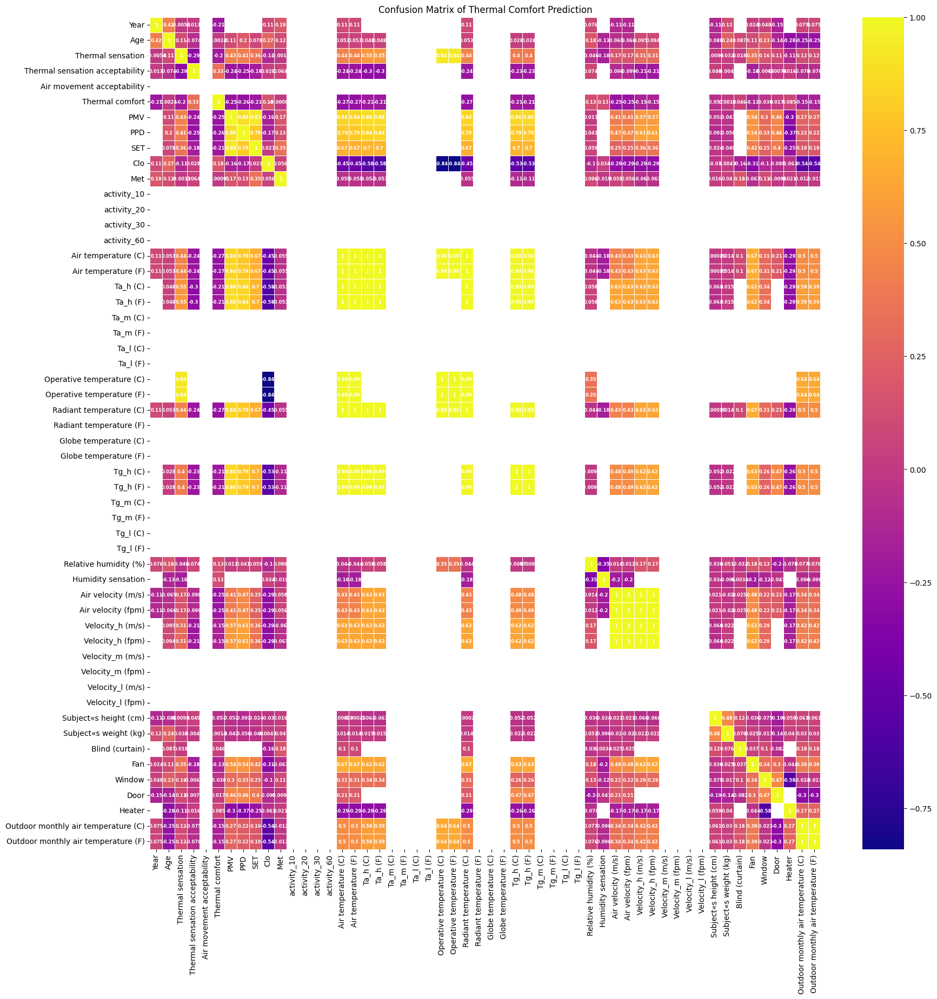

In [138]:
import seaborn as sns
import matplotlib.pyplot as plt
sklearn.metrics.confusion_matrix

# Sélection de 0,5 % des données du dataset
dt = data_India.sample(frac=1, random_state=0)

# Filtrer uniquement les colonnes numériques
numeric_dt = dt.select_dtypes(include='number')

# Créer une figure
plt.figure(figsize=(20, 20))

# Génération de la heatmap avec les annotations, format, taille, et couleur définis
heatmap = sns.heatmap(numeric_dt.corr(), 
                      annot=True,             # Afficher les valeurs numériques
                      cmap='plasma',          # Choisir la palette de couleurs
                      fmt='.2g',              # Format des valeurs numériques
                      annot_kws={"size": 6, "color": "white", "fontweight":'bold'}, # Taille et couleur des annotations
                      linewidths=0.5)         # Largeur des lignes de séparation

# Ajout d'un titre à la heatmap
plt.title('Confusion Matrix of Thermal Comfort Prediction')

# Save the figure to a file (entire figure)
plt.savefig('Confusion Matrix of Thermal Comfort Prediction India.png', dpi=300, bbox_inches='tight')  # Saves as PNG with tight layout to avoid cutting off parts of the plot
plt.savefig('Confusion Matrix of Thermal Comfort Prediction India.pdf', bbox_inches='tight')

# Affichage de la heatmap
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\3313362497.py:6: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  data_India = pd.read_csv('data_India.csv')  # Assurez-vous que les données sont bien chargées


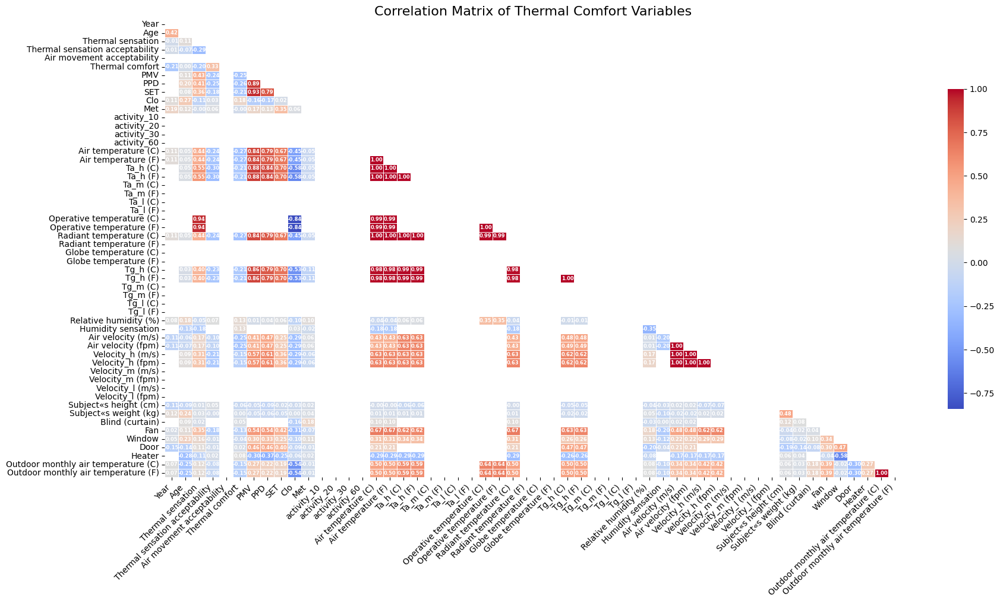

In [139]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Chargement des données (remplacez par votre dataset)
data_India = pd.read_csv('data_India.csv')  # Assurez-vous que les données sont bien chargées

# Sélection de 0,5 % des données du dataset
dt = data_India.sample(frac=1, random_state=0)

# Sélectionner les colonnes numériques pour la corrélation
numeric_data = dt.select_dtypes(include='number')

# Créer une figure
plt.figure(figsize=(20, 10))

# Générer une matrice de corrélation
correlation_matrix = numeric_data.corr()

# Masquer la moitié supérieure de la matrice
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Dessiner une heatmap avec masquage
sns.heatmap(correlation_matrix, 
            mask=mask,                # Masquer la moitié supérieure
            annot=True,               # Afficher les valeurs
            fmt=".2f",                # Format des valeurs
            cmap='coolwarm',          # Palette de couleurs
            cbar_kws={'shrink': 0.7}, # Réduction de la taille de la barre de couleur
            annot_kws={"size": 6, "color": "white", "fontweight":'bold'}, # Taille et couleur des annotations
            linewidths=0.5)           # Largeur des lignes

# Ajouter des titres et labels
plt.title('Correlation Matrix of Thermal Comfort Variables', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Sauvegarder et afficher
plt.savefig('Correlation_Matrix_India.png', dpi=300, bbox_inches='tight')
plt.savefig('Correlation_Matrix_India.pdf', bbox_inches='tight')
plt.show()

### CONFUSION MATRIX DE 50% data

### Extrarire PMV

In [144]:
print(filtered_dataset['PMV'])

NameError: name 'filtered_dataset' is not defined

### feature_importance_INDIA

In [148]:
# Calculer l'importance des caractéristiques
importances = model.feature_importances_

# Créer un DataFrame pour afficher les importances des caractéristiques
feature_importance_data = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Afficher les importances des caractéristiques
print(feature_importance_data)

# Visualiser l'importance des caractéristiques
plt.figure(figsize=(10, 10))
plt.barh(feature_importance_data['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.gca().invert_yaxis()  # Inverser l'ordre pour que les plus importantes soient en haut
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Feature Importance')
plt.tight_layout()

# Sauvegarder la visualisation dans un fichier PNG
plt.savefig('feature_importance_INDIA.png', bbox_inches='tight')

# Afficher la visualisation
plt.show()

# Fermer la figure pour libérer la mémoire
plt.close()

# Confirmer que l'image a bien été sauvegardée
if os.path.exists('feature_importance_INDIA.png'):
    print("La visualisation de l'importance des caractéristiques a été sauvegardée avec succès.")
else:
    print("Erreur de sauvegarde de la visualisation de l'importance des caractéristiques.")
plt.show()

AttributeError: 'LinearRegression' object has no attribute 'feature_importances_'

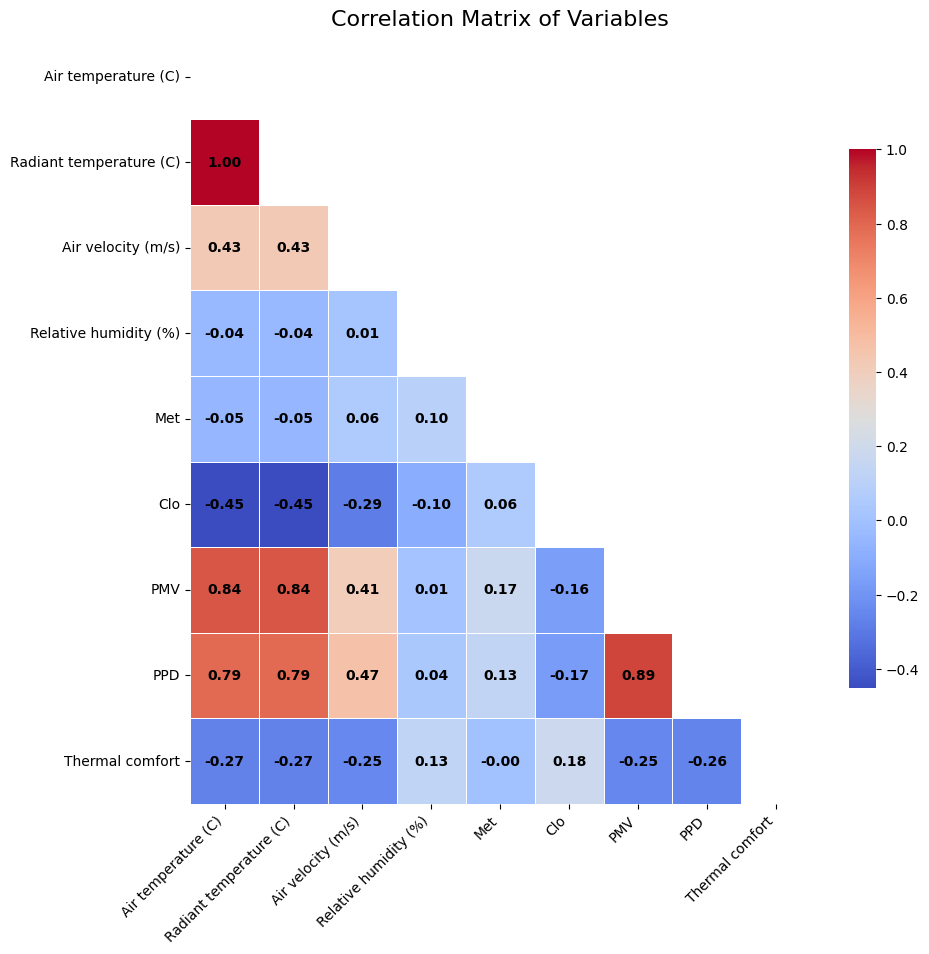

In [150]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Chargement des données (remplacez par votre dataset)
data = pd.read_csv('filtered_dataset.csv')

# Supprimer les colonnes liées au "thermal comfort"
columns_to_exclude = ['Thermal comfort']  # Remplacez par les noms exacts des colonnes
data_filtered = data.drop(columns=columns_to_exclude)

# Sélection de 0,5 % des données du dataset
dt = data.sample(frac=1, random_state=0)

# Sélectionner les colonnes numériques pour la corrélation
numeric_data = dt.select_dtypes(include='number')

# Créer une figure
plt.figure(figsize=(10, 10))

# Générer une matrice de corrélation
correlation_matrix = numeric_data.corr()

# Masquer la moitié supérieure de la matrice
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Dessiner une heatmap avec masquage
sns.heatmap(correlation_matrix, 
            mask=mask,                # Masquer la moitié supérieure
            annot=True,               # Afficher les valeurs
            fmt=".2f",                # Format des valeurs
            cmap='coolwarm',          # Palette de couleurs
            cbar_kws={'shrink': 0.7}, # Réduction de la taille de la barre de couleur
            annot_kws={"size": 10, "color": "black", "fontweight":'bold'}, # Taille et couleur des annotations
            linewidths=0.5)           # Largeur des lignes

# Ajouter des titres et labels
plt.title('Correlation Matrix of Variables', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Sauvegarder et afficher
plt.savefig('Correlation_Matrix_INDIA.png', dpi=300, bbox_inches='tight')
plt.savefig('Correlation_Matrix_INDIA.pdf', bbox_inches='tight')
plt.show()

### feature_importance_INDIA

Coefficients de corrélation de Pearson avec PMV (y compris PMV avec toutes les autres features) :
PMV                        1.000000
PPD                        0.890093
Air temperature (C)        0.843973
Radiant temperature (C)    0.843973
Air velocity (m/s)         0.406254
Met                        0.173758
Relative humidity (%)      0.010927
Clo                       -0.162472
Name: PMV, dtype: float64


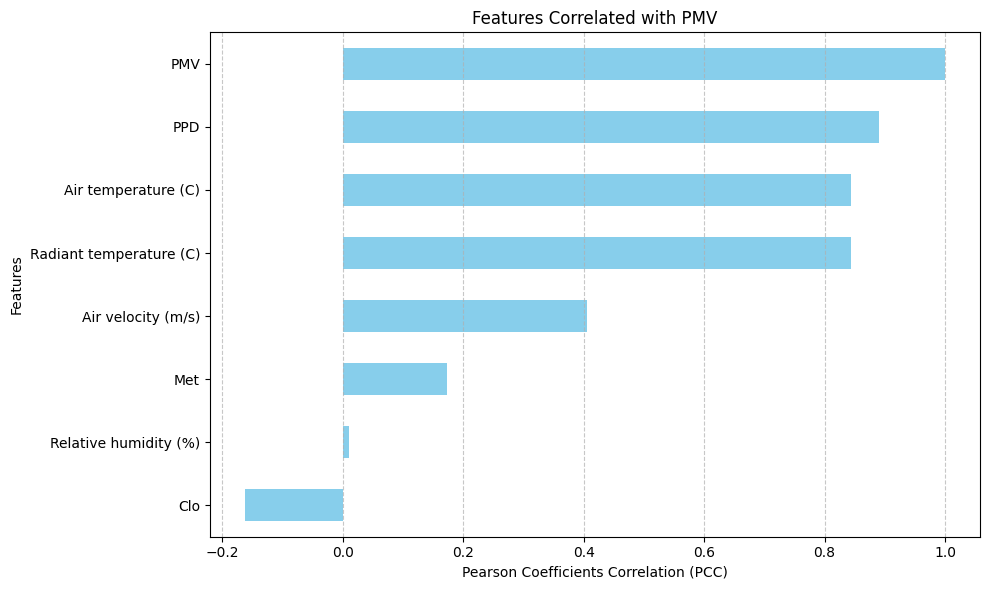

<Figure size 640x480 with 0 Axes>

In [153]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Charger les données
data = pd.read_csv('filtered_dataset.csv')

# Supprimer les colonnes liées au "thermal comfort"
columns_to_exclude = ['Thermal comfort']  # Remplacez par les noms exacts des colonnes
data_filtered = data.drop(columns=columns_to_exclude)

# Vérifiez que la colonne PMV existe
target_column = 'PMV'  # Nom de la colonne pour le PMV
if target_column not in data.columns:
    raise ValueError(f"La colonne cible '{target_column}' n'existe pas dans le dataset.")

# Filtrer les colonnes numériques
numeric_data = data_filtered.select_dtypes(include=[np.number])

# Calculer le coefficient de corrélation de Pearson
correlation_matrix = numeric_data.corr(method='pearson')

# Ajouter la corrélation de PMV avec lui-même (qui est toujours 1)
correlation_matrix.loc[target_column, target_column] = 1  # PMV est toujours parfaitement corrélé avec lui-même

# Extraire les corrélations avec PMV (y compris la corrélation de PMV avec lui-même)
pmv_correlations = correlation_matrix[target_column]  # Inclure PMV avec PMV ici

# Afficher les résultats dans un tableau
print("Coefficients de corrélation de Pearson avec PMV (y compris PMV avec toutes les autres features) :")
print(pmv_correlations.sort_values(ascending=False))

# Visualiser les résultats avec un barplot
plt.figure(figsize=(10, 6))
pmv_correlations.sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title("Features Correlated with PMV")
plt.xlabel("Pearson Coefficients Correlation (PCC)")
plt.ylabel("Features")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Sauvegarder et afficher

plt.savefig('Features Correlated with PMV_India.png', dpi=300, bbox_inches='tight')
plt.savefig('Features Correlated with PMV_India.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

Coefficients de corrélation de Pearson avec PMV (y compris PMV avec toutes les autres features) :
PMV                        1.000000
PPD                        0.890093
Air temperature (C)        0.843973
Radiant temperature (C)    0.843973
Air velocity (m/s)         0.406254
Met                        0.173758
Relative humidity (%)      0.010927
Clo                       -0.162472
Name: PMV, dtype: float64


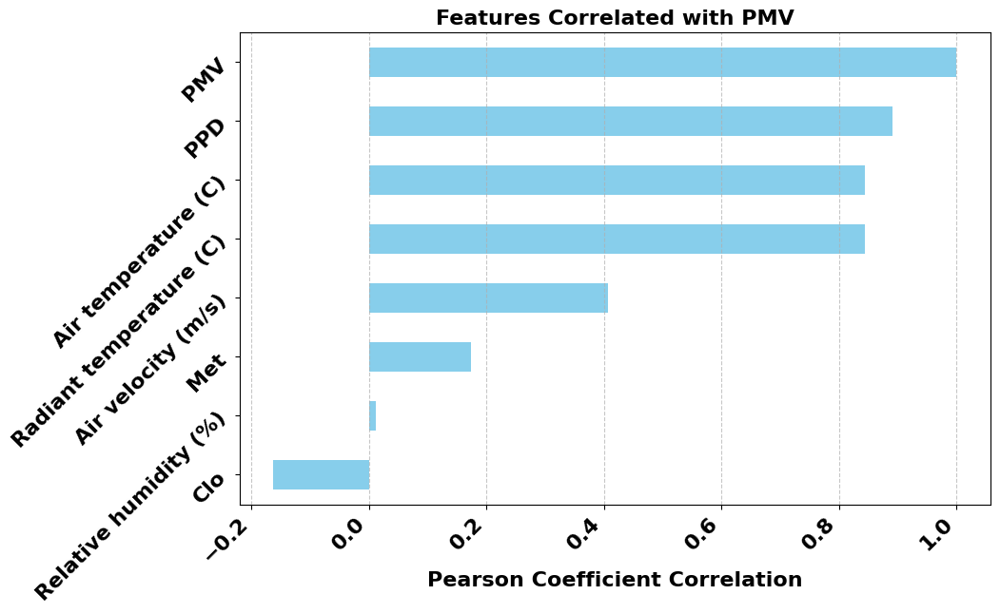

In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger les données
data = pd.read_csv('filtered_dataset.csv')

# Supprimer les colonnes liées au "thermal comfort"
columns_to_exclude = ['Thermal comfort']  # Remplacez par les noms exacts des colonnes
data_filtered = data.drop(columns=columns_to_exclude, errors='ignore')  # Ignore les erreurs si la colonne n'existe pas

# Vérifiez que la colonne PMV existe
target_column = 'PMV'  # Nom de la colonne pour le PMV
if target_column not in data_filtered.columns:
    raise ValueError(f"La colonne cible '{target_column}' n'existe pas dans le dataset.")

# Filtrer les colonnes numériques
numeric_data = data_filtered.select_dtypes(include=[np.number])

# Calculer le coefficient de corrélation de Pearson
correlation_matrix = numeric_data.corr(method='pearson')

# Extraire les corrélations avec PMV
if target_column in correlation_matrix:
    pmv_correlations = correlation_matrix[target_column]
else:
    raise ValueError(f"Impossible de calculer les corrélations avec la colonne '{target_column}'.")

# Afficher les résultats dans un tableau
print("Coefficients de corrélation de Pearson avec PMV (y compris PMV avec toutes les autres features) :")
print(pmv_correlations.sort_values(ascending=False))

# Visualiser les résultats avec un barplot
plt.figure(figsize=(10, 6))
pmv_correlations.sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title("Features Correlated with PMV", fontsize=16, fontweight='bold')
plt.xlabel("Pearson Coefficient Correlation", fontsize=16, fontweight='bold')
#plt.ylabel("Features", fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# Ajouter des titres et labels
plt.xticks(rotation=45, ha='right', fontsize=16, fontweight='bold')
plt.yticks(rotation=45, ha='right', fontsize=16, fontweight='bold')

# Sauvegarder la figure
plt.savefig('Features_Correlated_with_PMV_India.png', dpi=300, bbox_inches='tight')  # Image PNG
plt.savefig('Features_Correlated_with_PMV_India.pdf', bbox_inches='tight')  # Version PDF

# Afficher la figure
plt.show()


### Algorithms

In [159]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
%matplotlib inline
from sklearn.model_selection import train_test_split
#from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

In [161]:
dt = pd.read_csv('pmv_values  Thermal Comfort Prediction India.csv')

In [163]:
dt.head(5)

,PMV
0,0.17
1,-0.03
2,-0.03
3,0.17
4,0.12


In [165]:
dt.isnull().sum()

PMV    2853
dtype: int64

In [167]:
dt.duplicated().sum()

15746

In [169]:
# Supprimer les doublons sur la colonne PMV
dt_sans_doublons = dt.drop_duplicates(subset=['PMV'])

print("\nDonnées sans doublons :")
print("PMV")
print("-" * 20)
for _, row in dt_sans_doublons.iterrows():
    print(f"{row['PMV']:7.2f}")

# Pour voir combien de doublons ont été supprimés
print(f"\nNombre de doublons supprimés : {len(dt) - len(dt_sans_doublons)}")


Données sans doublons :
PMV
--------------------
   0.17
  -0.03
   0.12
   0.83
   0.38
   0.48
   0.35
   0.21
   0.58
   0.49
   0.55
  -0.20
  -0.25
  -0.47
   0.10
   0.06
  -0.13
   0.23
   0.19
   0.59
   0.51
   0.39
   0.00
   0.29
   0.28
  -0.15
    nan
   0.13
   0.69
   0.34
  -0.01
  -0.58
  -0.40
   0.44
   0.27
   1.28
   1.44
   0.61
  -0.16
  -0.12
   0.40
   0.05
   0.20
   0.31
   0.37
  -0.10
   0.16
  -0.28
  -0.24
   0.09
   0.33
   0.18
   0.07
  -0.02
  -0.14
  -0.21
  -0.32
  -0.46
  -0.41
   0.03
   0.41
   1.38
   0.56
   0.71
   0.15
   0.22
   0.32
  -0.07
   0.04
   0.08
   0.57
   0.54
   0.45
   0.02
   0.14
   0.30
  -0.91
  -0.85
  -0.75
  -0.96
  -0.70
   0.60
   0.64
   0.46
   0.50
  -0.26
  -0.18
  -0.17
  -0.05
   0.43
   0.11
  -0.51
  -0.38
  -0.30
   0.47
   0.01
  -0.23
  -0.11
  -0.08
   0.36
   0.42
   0.52
   0.72
   0.74
   1.43
   0.75
   1.02
   0.98
   0.96
   0.76
   0.62
   0.68
   0.67
   0.99
   0.94
   0.65
  -0.54
  -0.36
  -0.4

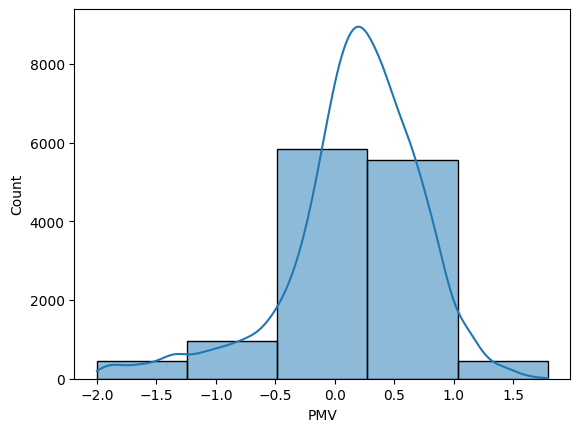

<Figure size 640x480 with 0 Axes>

In [171]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(dt['PMV'], bins=5, kde=True)
plt.show()
plt.savefig('Hisplotof Thermal Comfort Prediction India.png')

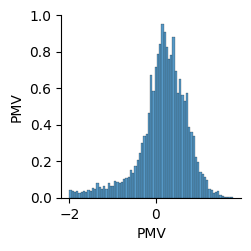

<Figure size 640x480 with 0 Axes>

In [173]:
sns.pairplot(dt)
plt.show()
plt.savefig('Thermal Comfort Prediction India.png')

In [175]:
import pandas as pd

# Chargement des données
dt = pd.read_csv('pmv_values  Thermal Comfort Prediction India.csv')

# Vérification et gestion des valeurs manquantes dans la colonne 'PMV'
dt['PMV'] = dt['PMV'].fillna(dt['PMV'].mean())

# Sélection de 0.5 % des données de la colonne 'PMV'
pmv_sample = dt['PMV']

# Affichage des valeurs sélectionnées
print(pmv_sample)


# Exportation des valeurs sélectionnées vers un fichier CSV
pmv_sample.to_csv('pmv_sample_KIDARI.csv', index=False)

0        0.17000
1       -0.03000
2       -0.03000
3        0.17000
4        0.12000
          ...   
16105    1.50000
16106    0.16777
16107    1.17000
16108    0.88000
16109   -0.60000
Name: PMV, Length: 16110, dtype: float64


### LINEAR REGRESSION

Mean Squared Error: 0.28860653217823307
R^2 Score: -0.02333094796638746
Mean Absolue Error: 0.3640559105300349
Root Mean Squared Error: 0.5372211203761753


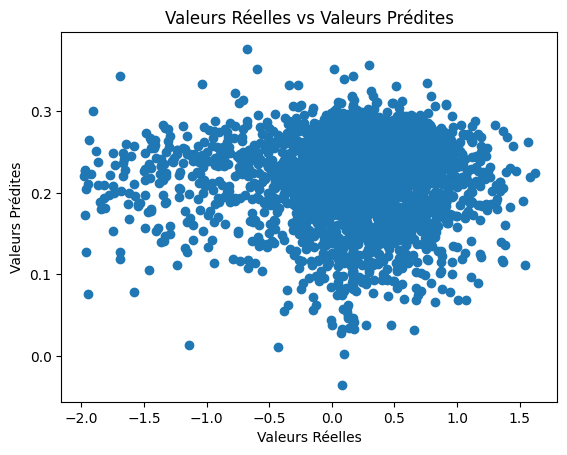

In [196]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt

# Pour calculer RMSE, on utilise np.sqrt(mean_squared_error)
def root_mean_square_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Chargement des données
dt = pd.read_csv('pmv_sample_KIDARI.csv')  # Assurez-vous que le chemin du fichier est correct

# Assurez-vous que le fichier CSV contient une colonne nommée "PMV"
if 'PMV' not in dt.columns:
    raise ValueError("La colonne 'PMV' n'existe pas dans le fichier CSV.")

# Vérification et gestion des valeurs manquantes
# Remplir les NaN avec la moyenne de la colonne PMV ou supprimer les lignes contenant NaN
dt['PMV'] = dt['PMV'].fillna(dt['PMV'].mean())

# Caractéristiques fictives
np.random.seed(0)
num_samples = len(dt)
features = np.random.rand(num_samples, 5)  # Par exemple, 5 caractéristiques aléatoires

# Création du DataFrame avec les caractéristiques et la colonne 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt['PMV']  # Ajoute les valeurs de PMV provenant du fichier CSV

# Division des données en variables explicatives (X) et cible (y)
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardisation des données
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entraînement du modèle SVR
svr = SVR(kernel='rbf')
svr.fit(X_train_scaled, y_train)

# Prédiction
y_pred = svr.predict(X_test_scaled)

# Évaluation du modèle
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)


print(f'Mean Squared Error: {mse}')
print(f'R^2 Score: {r2}')
print(f'Mean Absolue Error: {mae}')
print(f'Root Mean Squared Error: {rmse}')


# Visualisation des résultats
plt.scatter(y_test, y_pred)
plt.xlabel('Valeurs Réelles')
plt.ylabel('Valeurs Prédites')
plt.title('Valeurs Réelles vs Valeurs Prédites')
plt.show()

### Line plot pour Real and predicted values of PMV for all ML Models: a) SVR, b) ANN, c) RF, and d) XGBOOST.

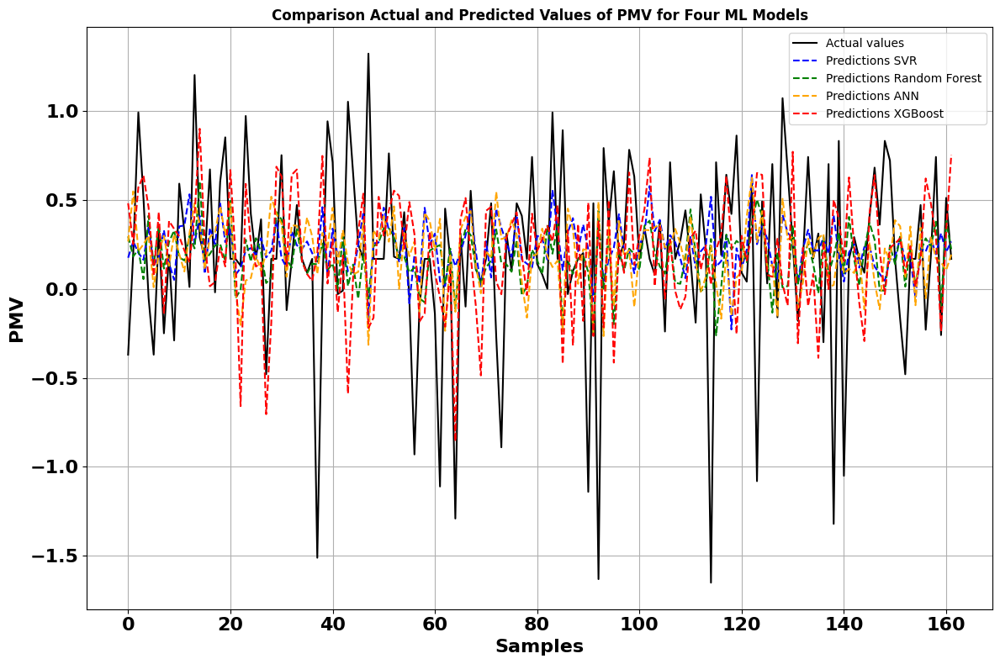

In [201]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor  # ANN model
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Take a 5% random sample of the dataset
dt_sample = dt.sample(frac=0.05, random_state=1)

# Handle missing values in the 'PMV' column
dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

# Generate random features for the demonstration (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt_sample)
features = np.random.rand(num_samples, 5)  # e.g., 5 random features

# Create DataFrame with features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt_sample['PMV'].values  # Add PMV from the CSV

# Split data into features and target
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
svr = SVR(kernel='rbf')
rf = RandomForestRegressor(random_state=0)
ann = MLPRegressor(random_state=0, max_iter=1000)  # Artificial Neural Network
xgboost = XGBRegressor(random_state=0)

# Train each model and get predictions
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

ann.fit(X_train_scaled, y_train)
y_pred_ann = ann.predict(X_test_scaled)

xgboost.fit(X_train, y_train)
y_pred_xgboost = xgboost.predict(X_test)

# Plotting the actual values vs. predictions for each model
plt.figure(figsize=(12, 8))

# Scatter plot for each model
plt.plot(y_test.values, label='Actual values', color='black')
plt.plot(y_pred_svr, label='Predictions SVR', linestyle='--', color='blue')
plt.plot(y_pred_rf, label='Predictions Random Forest', linestyle='--', color='green')
plt.plot(y_pred_ann, label='Predictions ANN', linestyle='--', color='orange')
plt.plot(y_pred_xgboost, label='Predictions XGBoost', linestyle='--', color='red')


# Labeling
plt.xlabel('Samples', fontsize=16, fontweight='bold')
plt.ylabel('PMV', fontsize=16, fontweight='bold')
plt.title('Comparison Actual and Predicted Values of PMV for Four ML Models', fontsize=12, fontweight='bold')
# Appliquer le gras aux valeurs des axes
ax = plt.gca()  # Récupérer l'objet Axes actuel
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(16)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(16)

plt.legend()
plt.grid(True)

# Adjust layout
plt.tight_layout()

# Save the figure to a file (entire figure)
plt.savefig('Comparaison des Valeurs Réelles et Prédictions pour Quatre Modèles ML India.png', dpi=300, bbox_inches='tight')  # Saves as PNG with tight layout to avoid cutting off parts of the plot
# Optionally save in different formats (e.g., JPEG or PDF)
plt.savefig('Comparaison des Valeurs Réelles et Prédictions pour Quatre Modèles ML India.pdf', bbox_inches='tight')

# Affichage de la heatmap
plt.show()

In [198]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Take a 5% random sample of the dataset
dt_sample = dt.sample(frac=0.3, random_state=1)

# Handle missing values in the 'PMV' column
dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

# Generate random features for the demonstration (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt_sample)
features = np.random.rand(num_samples, 5)  # Replace with actual features in real case

# Create DataFrame with features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt_sample['PMV'].values  # Add PMV from the CSV

# Split data into features and target
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
svr = SVR(kernel='POLY')
rf = RandomForestRegressor(random_state=0)
ann = MLPRegressor(random_state=0, max_iter=1000)
xgboost = XGBRegressor(random_state=0)

# Train models and predict
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

ann.fit(X_train_scaled, y_train)
y_pred_ann = ann.predict(X_test_scaled)

xgboost.fit(X_train, y_train)
y_pred_xgboost = xgboost.predict(X_test)

# Function to evaluate and print metrics
def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Mean Squared Error: {mse:.4f}")
    print(f"Root Mean Squared Error: {rmse:.4f}")
    print(f"Mean Absolute Error: {mae:.4f}")
    print(f"R² Score: {r2:.4f}\n")

# Evaluate each model
evaluate_model("SVR", y_test, y_pred_svr)
evaluate_model("Random Forest", y_test, y_pred_rf)
evaluate_model("ANN", y_test, y_pred_ann)
evaluate_model("XGBoost", y_test, y_pred_xgboost)

# Plot actual vs predicted
plt.figure(figsize=(12, 8))
plt.plot(y_test.values, label='Actual values', color='black')
plt.plot(y_pred_svr, label='SVR', linestyle='--', color='blue')
plt.plot(y_pred_rf, label='Random Forest', linestyle='--', color='green')
plt.plot(y_pred_ann, label='ANN', linestyle='--', color='orange')
plt.plot(y_pred_xgboost, label='XGBoost', linestyle='--', color='red')

# Labels and styling
plt.xlabel('Samples', fontsize=16, fontweight='bold')
plt.ylabel('PMV', fontsize=16, fontweight='bold')
plt.title('Comparison of Actual and Predicted PMV for ML Models', fontsize=14, fontweight='bold')

# Bold axis ticks
ax = plt.gca()
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(14)

plt.legend()
plt.grid(True)
plt.tight_layout()

# Save plot
plt.savefig('Comparaison_PMVs_Models.png', dpi=300, bbox_inches='tight')
plt.savefig('Comparaison_PMVs_Models.pdf', bbox_inches='tight')
plt.show()

InvalidParameterError: The 'kernel' parameter of SVR must be a str among {'sigmoid', 'precomputed', 'rbf', 'linear', 'poly'} or a callable. Got 'POLY' instead.

--- SVR ---
Mean Squared Error: 0.0706
Root Mean Squared Error: 0.2657
Mean Absolute Error: 0.1828
R² Score: 0.8955

--- Random Forest ---
Mean Squared Error: 0.0473
Root Mean Squared Error: 0.2176
Mean Absolute Error: 0.1313
R² Score: 0.9299

--- ANN ---
Mean Squared Error: 0.0705
Root Mean Squared Error: 0.2656
Mean Absolute Error: 0.1917
R² Score: 0.8956

--- XGBoost ---
Mean Squared Error: 0.0533
Root Mean Squared Error: 0.2309
Mean Absolute Error: 0.1525
R² Score: 0.9210



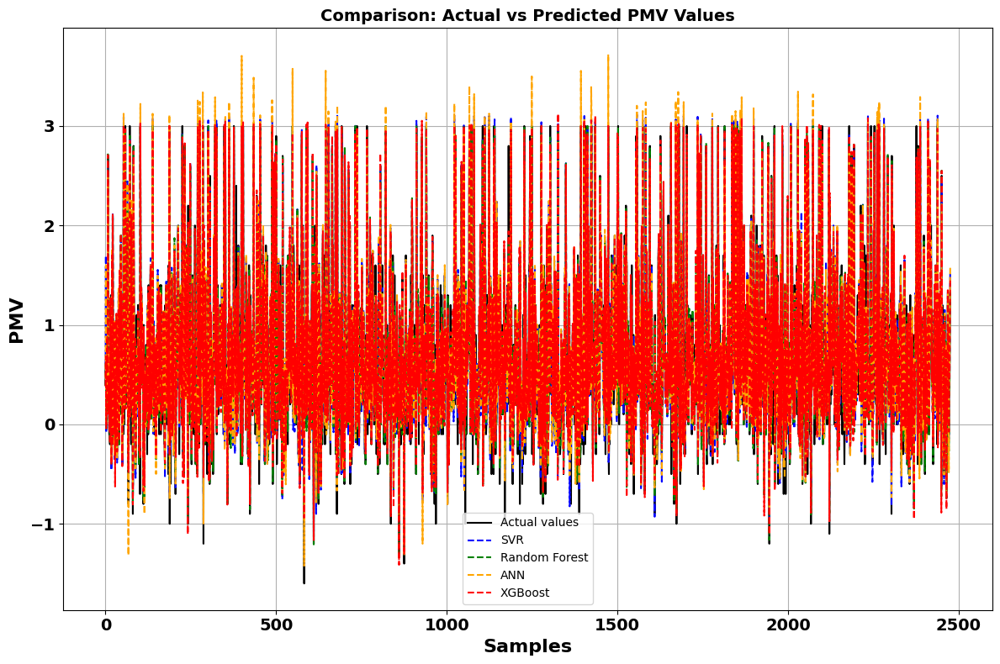

In [214]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Charger le dataset complet
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# 2. Sélectionner les colonnes (modifier selon vos données réelles)
#feature_cols = [
#    'Air temperature (C)',
#    'Relative humidity (%)',
#    'Air velocity (m/s)',
#    'Clo'  # remplacez ou ajoutez d'autres colonnes utiles
#]

# 3. Nettoyage : supprimer les lignes avec des valeurs manquantes dans les colonnes importantes
#dt_clean = dt.dropna(subset=feature_cols + ['PMV'])

# 4. Définir X et y
X = dt_clean[feature_cols]
y = dt_clean['PMV']

# 5. Séparer les données en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Standardiser les données (nécessaire pour SVR et ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 7. Initialiser les modèles
svr = SVR(kernel='rbf')
rf = RandomForestRegressor(random_state=42)
ann = MLPRegressor(random_state=42, max_iter=1000)
xgboost = XGBRegressor(random_state=42)

# 8. Entraîner les modèles
svr.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
ann.fit(X_train_scaled, y_train)
xgboost.fit(X_train, y_train)

# 9. Prédictions
y_pred_svr = svr.predict(X_test_scaled)
y_pred_rf = rf.predict(X_test)
y_pred_ann = ann.predict(X_test_scaled)
y_pred_xgboost = xgboost.predict(X_test)

# 10. Fonction d'évaluation
def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Mean Squared Error: {mse:.4f}")
    print(f"Root Mean Squared Error: {rmse:.4f}")
    print(f"Mean Absolute Error: {mae:.4f}")
    print(f"R² Score: {r2:.4f}")
    print()

# 11. Évaluation
evaluate_model("SVR", y_test, y_pred_svr)
evaluate_model("Random Forest", y_test, y_pred_rf)
evaluate_model("ANN", y_test, y_pred_ann)
evaluate_model("XGBoost", y_test, y_pred_xgboost)

# 12. Visualisation
plt.figure(figsize=(12, 8))
plt.plot(y_test.values, label='Actual values', color='black')
plt.plot(y_pred_svr, label='SVR', linestyle='--', color='blue')
plt.plot(y_pred_rf, label='Random Forest', linestyle='--', color='green')
plt.plot(y_pred_ann, label='ANN', linestyle='--', color='orange')
plt.plot(y_pred_xgboost, label='XGBoost', linestyle='--', color='red')
plt.xlabel('Samples', fontsize=16, fontweight='bold')
plt.ylabel('PMV', fontsize=16, fontweight='bold')
plt.title('Comparison: Actual vs Predicted PMV Values', fontsize=14, fontweight='bold')
ax = plt.gca()
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(14)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('PMV_Comparaison_Predictions_ML.png', dpi=300, bbox_inches='tight')
plt.savefig('PMV_Comparaison_Predictions_ML.pdf', bbox_inches='tight')
plt.show()

--- SVR ---
Mean Squared Error (MSE): 0.0706
Root Mean Squared Error (RMSE): 0.2657
Mean Absolute Error (MAE): 0.1828
R² Score: 0.8955

--- Random Forest ---
Mean Squared Error (MSE): 0.0473
Root Mean Squared Error (RMSE): 0.2176
Mean Absolute Error (MAE): 0.1313
R² Score: 0.9299

--- ANN ---
Mean Squared Error (MSE): 0.0705
Root Mean Squared Error (RMSE): 0.2656
Mean Absolute Error (MAE): 0.1917
R² Score: 0.8956

--- XGBoost ---
Mean Squared Error (MSE): 0.0533
Root Mean Squared Error (RMSE): 0.2309
Mean Absolute Error (MAE): 0.1525
R² Score: 0.9210



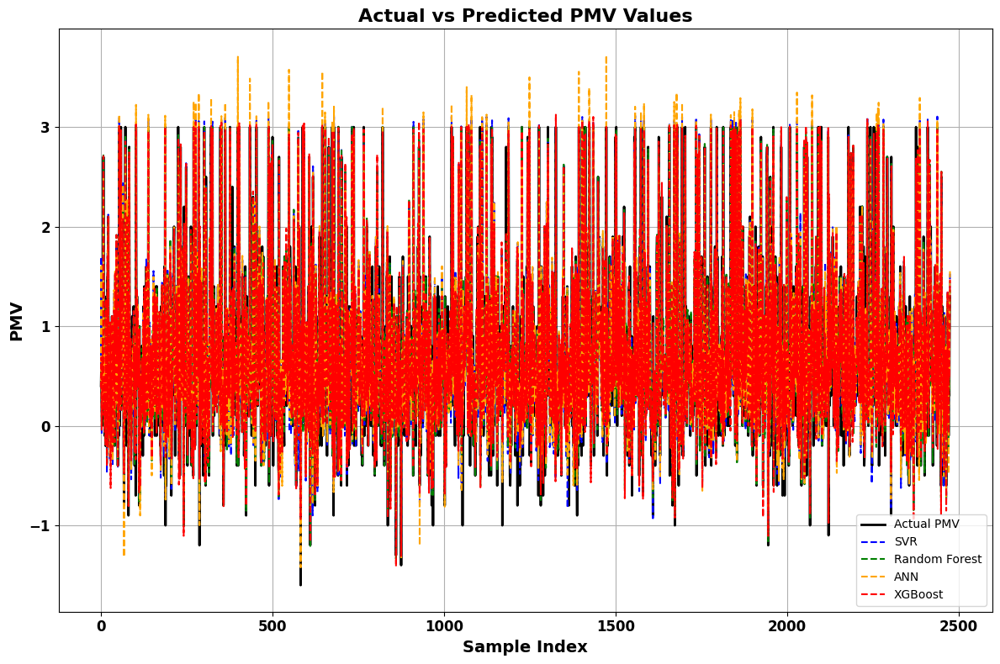

In [206]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Chargement du dataset
dt = pd.read_csv('filtered_dataset.csv')

# 2. Sélection des colonnes pertinentes (modifiez selon vos données)
feature_cols = [
    'Air temperature (C)',
    'Relative humidity (%)',
    'Air velocity (m/s)',
    'Clo'  # Ajoutez ou remplacez selon les colonnes disponibles
]

# 3. Nettoyage : supprimer les lignes avec des valeurs manquantes
dt_clean = dt.dropna(subset=feature_cols + ['PMV'])

# 4. Définir les variables explicatives et la cible
X = dt_clean[feature_cols]
y = dt_clean['PMV']

# 5. Séparation des données en train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Standardisation (nécessaire pour SVR et ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 7. Initialisation des modèles
models = {
    "SVR": SVR(kernel='rbf'),
    "Random Forest": RandomForestRegressor(random_state=42),
    "ANN": MLPRegressor(random_state=42, max_iter=1000),
    "XGBoost": XGBRegressor(random_state=42)
}

# 8. Entraînement des modèles
models["SVR"].fit(X_train_scaled, y_train)
models["Random Forest"].fit(X_train, y_train)
models["ANN"].fit(X_train_scaled, y_train)
models["XGBoost"].fit(X_train, y_train)

# 9. Prédictions
predictions = {
    "SVR": models["SVR"].predict(X_test_scaled),
    "Random Forest": models["Random Forest"].predict(X_test),
    "ANN": models["ANN"].predict(X_test_scaled),
    "XGBoost": models["XGBoost"].predict(X_test)
}

# 10. Fonction d'évaluation
def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"R² Score: {r2:.4f}\n")

# 11. Évaluation des modèles
for name, y_pred in predictions.items():
    evaluate_model(name, y_test, y_pred)

# 12. Visualisation des prédictions
plt.figure(figsize=(12, 8))
plt.plot(y_test.values, label='Actual PMV', color='black', linewidth=2)
plt.plot(predictions["SVR"], label='SVR', linestyle='--', color='blue')
plt.plot(predictions["Random Forest"], label='Random Forest', linestyle='--', color='green')
plt.plot(predictions["ANN"], label='ANN', linestyle='--', color='orange')
plt.plot(predictions["XGBoost"], label='XGBoost', linestyle='--', color='red')

plt.xlabel('Sample Index', fontsize=14, fontweight='bold')
plt.ylabel('PMV', fontsize=14, fontweight='bold')
plt.title('Actual vs Predicted PMV Values', fontsize=16, fontweight='bold')

# Formatage des axes
ax = plt.gca()
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')
    label.set_fontsize(12)

plt.legend()
plt.grid(True)
plt.tight_layout()

# Sauvegarde des figures
plt.savefig('PMV_Comparison_Predictions_ML.png', dpi=300, bbox_inches='tight')
plt.savefig('PMV_Comparison_Predictions_ML.pdf', bbox_inches='tight')
plt.show()

--- SVR ---
Mean Squared Error (MSE): 0.2962
Root Mean Squared Error (RMSE): 0.5443
Mean Absolute Error (MAE): 0.3744
R² Score: -0.1037

--- Random Forest ---
Mean Squared Error (MSE): 0.3044
Root Mean Squared Error (RMSE): 0.5517
Mean Absolute Error (MAE): 0.3849
R² Score: -0.1343

--- ANN ---
Mean Squared Error (MSE): 0.3140
Root Mean Squared Error (RMSE): 0.5604
Mean Absolute Error (MAE): 0.4021
R² Score: -0.1701

--- XGBoost ---
Mean Squared Error (MSE): 0.3521
Root Mean Squared Error (RMSE): 0.5934
Mean Absolute Error (MAE): 0.4280
R² Score: -0.3119



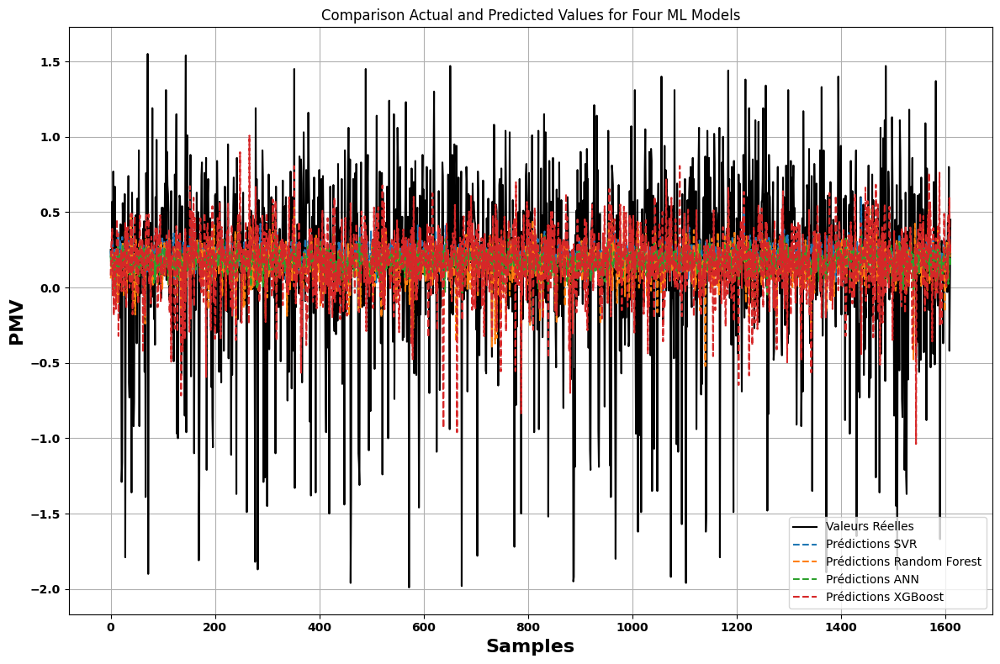

In [268]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Charger et prétraiter les données
def load_and_preprocess_data(file_path, sample_frac=0.5):
    dt = pd.read_csv(file_path)
    dt_sample = dt.sample(frac=sample_frac, random_state=1)
    
    # Gérer les valeurs manquantes dans PMV
    if 'PMV' not in dt_sample.columns:
        raise ValueError("La colonne 'PMV' est absente du dataset.")
    dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

    # Générer des caractéristiques (à remplacer par des caractéristiques réelles si disponibles)
    num_samples = len(dt_sample)
    np.random.seed(0)
    features = np.random.rand(num_samples, 5)
    df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
    df['PMV'] = dt_sample['PMV'].values

    return df

# Modèles d'entraînement et prédictions
def train_and_predict(X_train, X_test, y_train, y_test):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Modèles
    models = {
        "SVR": SVR(kernel='rbf'),
        "Random Forest": RandomForestRegressor(random_state=0),
        "ANN": MLPRegressor(random_state=0, max_iter=1000),
        "XGBoost": XGBRegressor(random_state=0)
    }

    predictions = {}
    for name, model in models.items():
        if name in ["SVR", "ANN"]:  # Standardisation requise
            model.fit(X_train_scaled, y_train)
            predictions[name] = model.predict(X_test_scaled)
        else:
            model.fit(X_train, y_train)
            predictions[name] = model.predict(X_test)
    return predictions

# 10. Fonction d'évaluation
def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"R² Score: {r2:.4f}\n")

# 11. Évaluation des modèles
for name, y_pred in predictions.items():
    evaluate_model(name, y_test, y_pred)
    
# Tracer les résultats
def plot_results(y_test, predictions):
    plt.figure(figsize=(12, 8))
    plt.plot(y_test.values, label='Valeurs Réelles', color='black', linewidth=1.5)
    
    for name, preds in predictions.items():
        plt.plot(preds, label=f'Prédictions {name}', linestyle='--')
    
    plt.xlabel('Samples', fontweight='bold',fontsize = 16 )
    plt.ylabel('PMV', fontweight='bold',fontsize = 16 ) 
    plt.title('Comparison Actual and Predicted Values for Four ML Models')

        # Appliquer le gras aux valeurs des axes
    plt.xticks(fontweight='bold')
    label.set_fontsize(16)
    plt.yticks(fontweight='bold')
    label.set_fontsize(16)
    
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('Comparaison_PMV.png', dpi=300, bbox_inches='tight')
    plt.show()
# Main
if __name__ == "__main__":
    file_path = 'pmv_sample_KIDARI.csv'
    df = load_and_preprocess_data(file_path)
    X = df.drop('PMV', axis=1)
    y = df['PMV']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
    predictions = train_and_predict(X_train, X_test, y_train, y_test)
    plot_results(y_test, predictions)

### Line plot pour Real and predicted values of PMV for all ML Models: a) SVR, b) ANN, c) RF, and d) XGBOOST, e) DNN

C:\Users\Rchid\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3170 - mae: 0.4106
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2926 - mae: 0.3981
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2969 - mae: 0.3924
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2850 - mae: 0.3762
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2589 - mae: 0.3608
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2733 - mae: 0.3810  
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3011 - mae: 0.3850
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2962 - mae: 0.3782 0
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2724 - mae: 0.3701
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2919 - mae: 0.3830
Epoch 11/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2625 - mae: 0.3756
Epoch 12/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2851 - mae: 0.3894
Epoch 13/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms

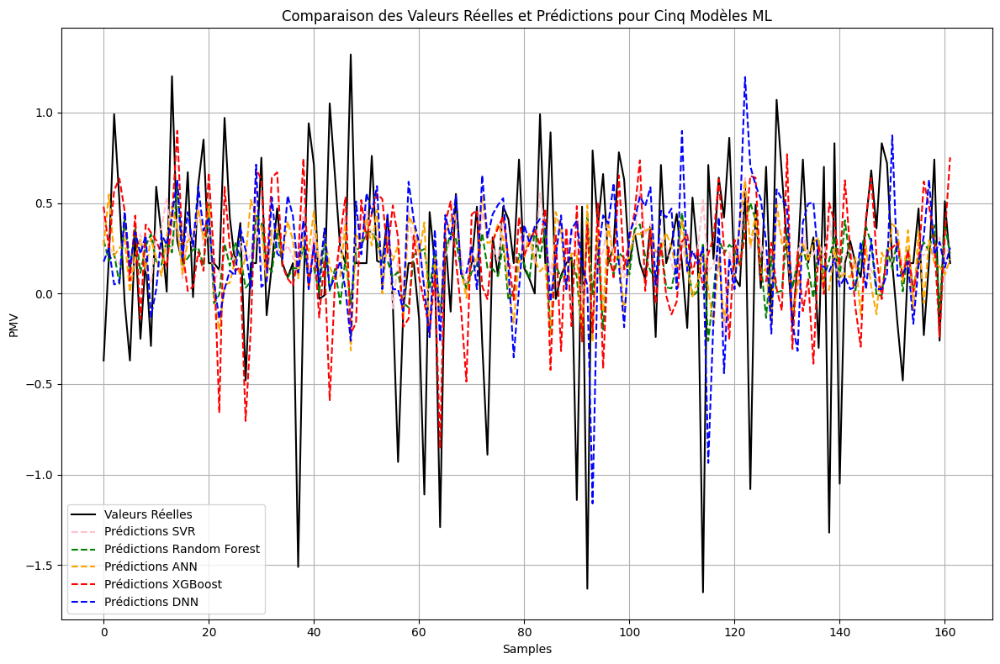

In [194]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor  # ANN model
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Take a 5% random sample of the dataset
dt_sample = dt.sample(frac=0.05, random_state=1)

# Handle missing values in the 'PMV' column
dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

# Generate random features for the demonstration (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt_sample)
features = np.random.rand(num_samples, 5)  # e.g., 5 random features

# Create DataFrame with features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt_sample['PMV'].values  # Add PMV from the CSV

# Split data into features and target
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
svr = SVR(kernel='rbf')
rf = RandomForestRegressor(random_state=0)
ann = MLPRegressor(random_state=0, max_iter=1000)  # Artificial Neural Network
xgboost = XGBRegressor(random_state=0)

# Train each model and get predictions
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

ann.fit(X_train_scaled, y_train)
y_pred_ann = ann.predict(X_test_scaled)

xgboost.fit(X_train, y_train)
y_pred_xgboost = xgboost.predict(X_test)

# Add Deep Neural Network (DNN) model
dnn = Sequential([
    Dense(64, input_dim=X_train_scaled.shape[1], activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])
dnn.compile(optimizer=Adam(learning_rate=0.01), loss='mean_squared_error', metrics=['mae'])

# Train the DNN model
dnn.fit(X_train_scaled, y_train, epochs=50, batch_size=32, verbose=1)

# Predict with the DNN model
y_pred_dnn = dnn.predict(X_test_scaled).flatten()

# Plotting the actual values vs. predictions for each model
plt.figure(figsize=(12, 8))

# Scatter plot for each model
plt.plot(y_test.values, label='Valeurs Réelles', color='black')
plt.plot(y_pred_svr, label='Prédictions SVR', linestyle='--', color='pink')
plt.plot(y_pred_rf, label='Prédictions Random Forest', linestyle='--', color='green')
plt.plot(y_pred_ann, label='Prédictions ANN', linestyle='--', color='orange')
plt.plot(y_pred_xgboost, label='Prédictions XGBoost', linestyle='--', color='red')
plt.plot(y_pred_dnn, label='Prédictions DNN', linestyle='--', color='blue')

# Labeling
plt.xlabel('Samples')
plt.ylabel('PMV')
plt.title('Comparaison des Valeurs Réelles et Prédictions pour Cinq Modèles ML')
plt.legend()
plt.grid(True)

# Adjust layout
plt.tight_layout()

# Save the figure to a file (entire figure)
plt.savefig('Comparaison des Valeurs Réelles et Prédictions pour Cinq Modèles ML India.png', dpi=300, bbox_inches='tight')  # Saves as PNG with tight layout to avoid cutting off parts of the plot
# Optionally save in different formats (e.g., JPEG or PDF)
plt.savefig('Comparaison des Valeurs Réelles et Prédictions pour Cinq Modèles ML India.pdf', bbox_inches='tight')

# Display the plot
plt.show()

SVR -> MSE: 0.0074, MAE: 0.0679, RMSE: 0.0863, R2: 0.9723
Random Forest -> MSE: 0.0056, MAE: 0.0586, RMSE: 0.0746, R2: 0.9792
ANN -> MSE: 0.0064, MAE: 0.0642, RMSE: 0.0801, R2: 0.9761
XGBoost -> MSE: 0.0058, MAE: 0.0605, RMSE: 0.0764, R2: 0.9783


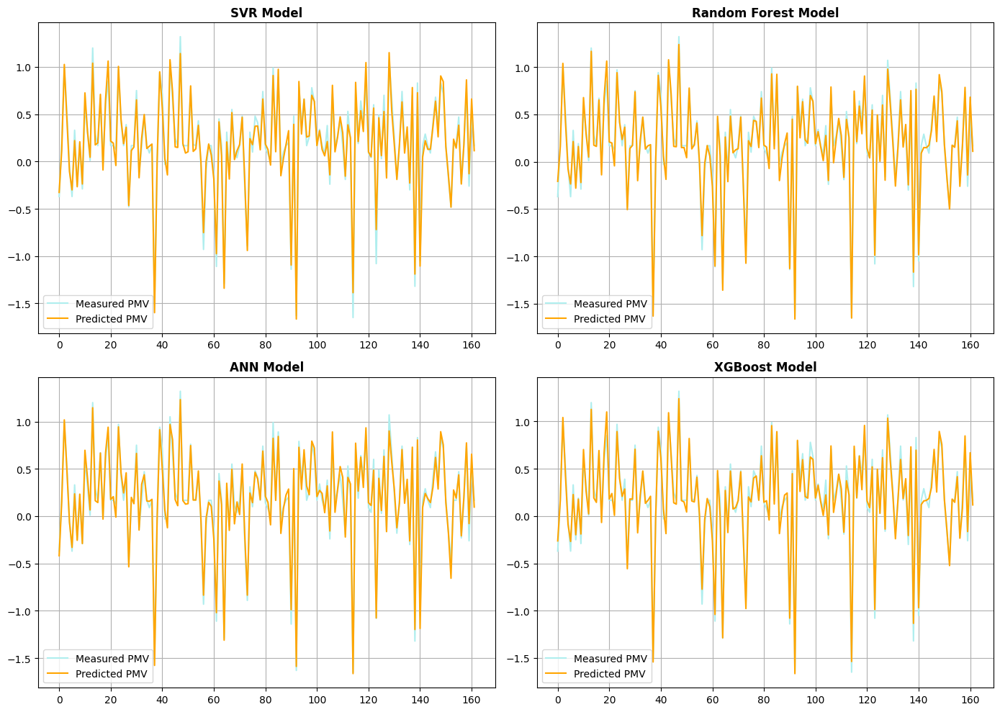

In [198]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import os

# Load dataset
try:
    dt = pd.read_csv('pmv_sample_KIDARI.csv')
except FileNotFoundError:
    raise FileNotFoundError("The file 'pmv_sample_KIDARI.csv' was not found. Please check the file path.")

# Sample 5% of the data
dt_sample = dt.sample(frac=0.05, random_state=1)

# Handle missing values
if 'PMV' not in dt_sample.columns:
    raise ValueError("'PMV' column is missing in the dataset.")
dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

# Generate synthetic features correlated with PMV
np.random.seed(0)
num_samples = len(dt_sample)
features = np.array([
    dt_sample['PMV'] + np.random.normal(0, 0.1, num_samples),
    dt_sample['PMV'] * 2 + np.random.normal(0, 0.2, num_samples),
    np.random.rand(num_samples),
    np.random.rand(num_samples) * 0.5,
    np.random.rand(num_samples) * 2
]).T

# Create DataFrame
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt_sample['PMV'].values

# Split data
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "SVR": SVR(kernel='rbf', C=1.0, gamma='scale'),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=0),
    "ANN": MLPRegressor(hidden_layer_sizes=(50,), random_state=0, max_iter=1000),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=0)
}

predictions = {}
metrics = {}

# Train and predict
for name, model in models.items():
    if name in ["SVR", "ANN"]:  # Standardized data
        model.fit(X_train_scaled, y_train)
        predictions[name] = model.predict(X_test_scaled)
    else:  # Non-standardized data
        model.fit(X_train, y_train)
        predictions[name] = model.predict(X_test)
    
    # Evaluate
    mse = mean_squared_error(y_test, predictions[name])
    mae = mean_absolute_error(y_test, predictions[name])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[name])
    metrics[name] = {'MSE': mse, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Print metrics
for model, metric in metrics.items():
    print(f"{model} -> MSE: {metric['MSE']:.4f}, MAE: {metric['MAE']:.4f}, RMSE: {metric['RMSE']:.4f}, R2: {metric['R2']:.4f}")

# Plot predictions
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

def plot_results(ax, y_test, y_pred, title):
    ax.plot(y_test.values, label='Measured PMV', color='paleturquoise')
    ax.plot(y_pred, label='Predicted PMV', color='orange')
    ax.set_title(title, fontweight='bold')
    ax.legend()
    ax.grid(True)

plot_results(axs[0, 0], y_test, predictions["SVR"], "SVR Model")
plot_results(axs[0, 1], y_test, predictions["Random Forest"], "Random Forest Model")
plot_results(axs[1, 0], y_test, predictions["ANN"], "ANN Model")
plot_results(axs[1, 1], y_test, predictions["XGBoost"], "XGBoost Model")

# Save plots
save_dir = './plots'
os.makedirs(save_dir, exist_ok=True)
plot_path_png = os.path.join(save_dir, "Line_plot_PMV_INDIA.png")
plot_path_pdf = os.path.join(save_dir, "Line_plot_PMV_INDIA.pdf")
plt.tight_layout()
plt.savefig(plot_path_png, dpi=300, bbox_inches='tight')
plt.savefig(plot_path_pdf, bbox_inches='tight')
plt.show()


Predictions saved for SVR at: Results_PMV_Models\SVR_predictions.csv
Predictions saved for Random Forest at: Results_PMV_Models\Random Forest_predictions.csv
Predictions saved for ANN at: Results_PMV_Models\ANN_predictions.csv
Predictions saved for XGBoost at: Results_PMV_Models\XGBoost_predictions.csv
SVR -> MSE: 0.0074, MAE: 0.0679, RMSE: 0.0863, R2: 0.9723
Random Forest -> MSE: 0.0056, MAE: 0.0586, RMSE: 0.0746, R2: 0.9792
ANN -> MSE: 0.0064, MAE: 0.0642, RMSE: 0.0801, R2: 0.9761
XGBoost -> MSE: 0.0058, MAE: 0.0605, RMSE: 0.0764, R2: 0.9783
Plots saved at: Results_PMV_Models\PMV_Measured_Predictions_Plot.png and Results_PMV_Models\PMV_Measured_Predictions_Plot.pdf


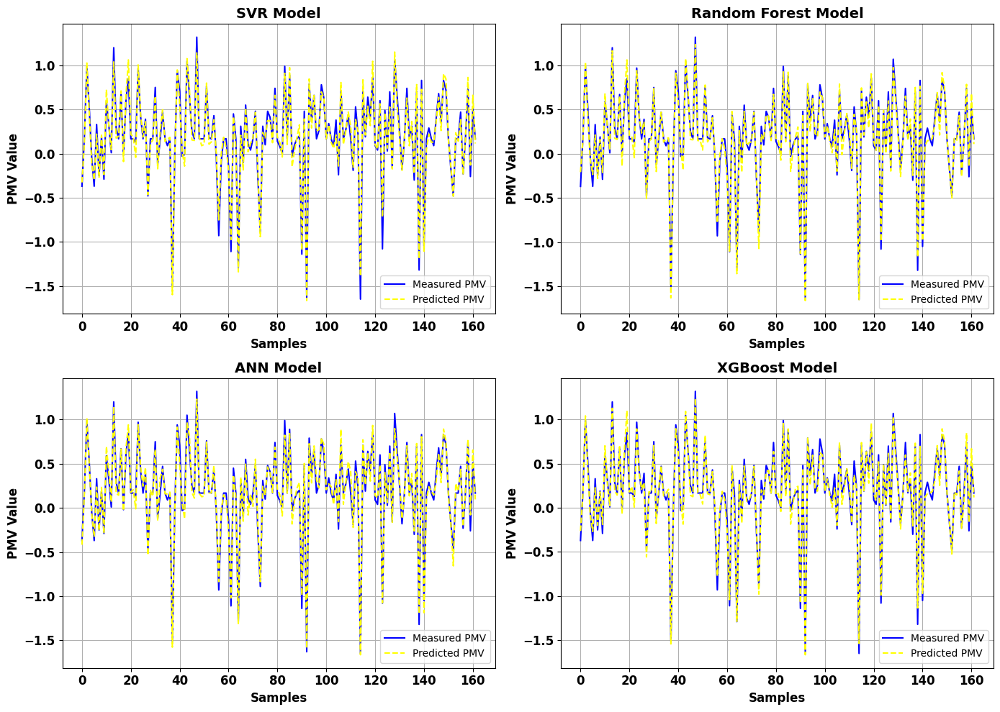

In [202]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import os

# Load dataset
try:
    dt = pd.read_csv('pmv_sample_KIDARI.csv')
except FileNotFoundError:
    raise FileNotFoundError("The file 'pmv_sample_KIDARI.csv' was not found. Please check the file path.")

# Sample 5% of the data
dt_sample = dt.sample(frac=0.05, random_state=1)

# Handle missing values
if 'PMV' not in dt_sample.columns:
    raise ValueError("'PMV' column is missing in the dataset.")
dt_sample['PMV'] = dt_sample['PMV'].fillna(dt_sample['PMV'].mean())

# Generate synthetic features that are correlated with PMV
np.random.seed(0)
num_samples = len(dt_sample)
features = np.array([
    dt_sample['PMV'] + np.random.normal(0, 0.1, num_samples),  # Feature correlated with PMV
    dt_sample['PMV'] * 2 + np.random.normal(0, 0.2, num_samples),  # Another correlated feature
    np.random.rand(num_samples),  # Random noise
    np.random.rand(num_samples) * 0.5,  # More random noise
    np.random.rand(num_samples) * 2   # More random noise
]).T

# Create DataFrame
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt_sample['PMV'].values

# Split data
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "SVR": SVR(kernel='rbf', C=1.0, gamma='scale'),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=0),
    "ANN": MLPRegressor(hidden_layer_sizes=(50,), random_state=0, max_iter=1000),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=0)
}

predictions = {}
metrics = {}

# Directory to save results
save_dir = "Results_PMV_Models"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# Train and predict
for name, model in models.items():
    if name in ["SVR", "ANN"]:  # Standardized data
        model.fit(X_train_scaled, y_train)
        predictions[name] = model.predict(X_test_scaled)
    else:  # Non-standardized data
        model.fit(X_train, y_train)
        predictions[name] = model.predict(X_test)
    
    # Evaluate
    mse = mean_squared_error(y_test, predictions[name])
    mae = mean_absolute_error(y_test, predictions[name])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[name])
    metrics[name] = {'MSE': mse, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

    # Save predictions
    prediction_df = pd.DataFrame({
        'Measured PMV': y_test.values,
        'Predicted PMV': predictions[name]
    })
    prediction_csv_path = os.path.join(save_dir, f"{name}_predictions.csv")
    prediction_df.to_csv(prediction_csv_path, index=False)
    print(f"Predictions saved for {name} at: {prediction_csv_path}")

# Print metrics
for model, metric in metrics.items():
    print(f"{model} -> MSE: {metric['MSE']:.4f}, MAE: {metric['MAE']:.4f}, RMSE: {metric['RMSE']:.4f}, R2: {metric['R2']:.4f}")

# Plot predictions
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

def plot_results(ax, y_test, y_pred, title):
    ax.plot(y_test.values, label='Measured PMV', color='blue')
    ax.plot(y_pred, label='Predicted PMV', color='yellow', linestyle='--')
    ax.set_title(title, fontweight='bold', fontsize=14)
    ax.set_xlabel('Samples', fontweight='bold', fontsize=12)
    ax.set_ylabel('PMV Value', fontweight='bold', fontsize=12)
    ax.legend()
    ax.grid(True)

plot_results(axs[0, 0], y_test, predictions["SVR"], "SVR Model")
plot_results(axs[0, 1], y_test, predictions["Random Forest"], "Random Forest Model")
plot_results(axs[1, 0], y_test, predictions["ANN"], "ANN Model")
plot_results(axs[1, 1], y_test, predictions["XGBoost"], "XGBoost Model")

# Appliquer le gras aux valeurs des axes dans chaque subplot
for ax in axs.flat:
    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(12)
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(12)

# Save plots
plot_path_png = os.path.join(save_dir, "PMV_Measured_Predictions_Plot.png")
plot_path_pdf = os.path.join(save_dir, "PMV_Measured_Predictions_Plot.pdf")
plt.tight_layout()
plt.savefig(plot_path_png, dpi=300, bbox_inches='tight')
plt.savefig(plot_path_pdf, bbox_inches='tight')

print(f"Plots saved at: {plot_path_png} and {plot_path_pdf}")

# Show plots
plt.show()

### Line plot DNN 

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\3015808797.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\3015808797.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\3015808797.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 1].set_xticklabels(axs[0, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\3015808797.py:42: UserWarning: set_ticklabels() shoul

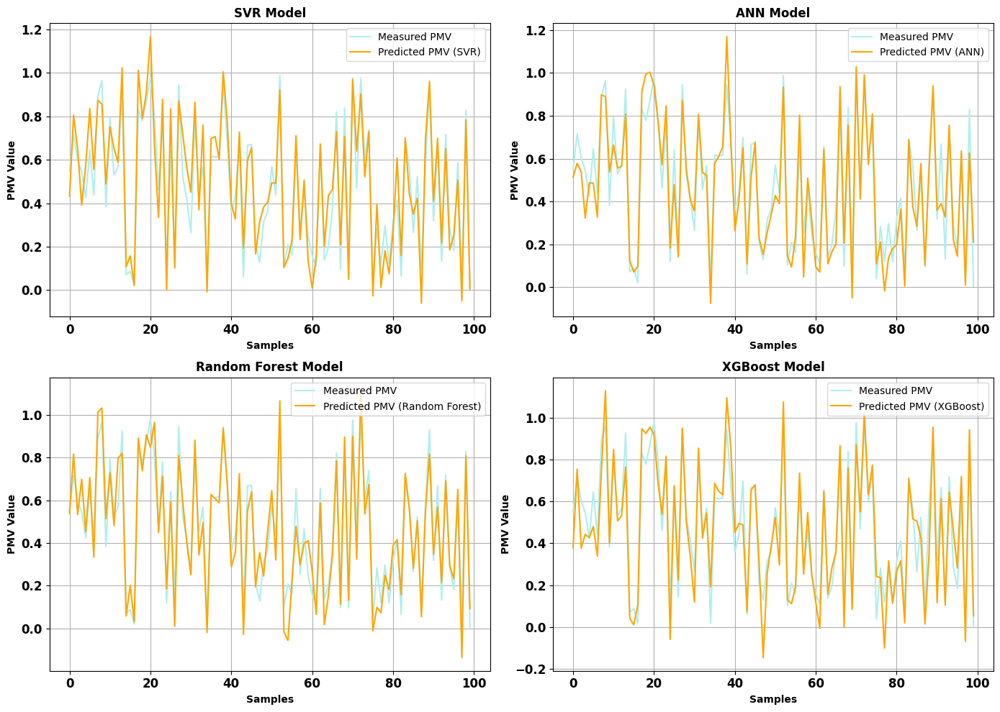

In [207]:
import matplotlib.pyplot as plt
import numpy as np

# Simulated actual PMV values and predictions for demonstration
np.random.seed(0)
y_test = np.random.rand(100)  # Replace with actual PMV values
y_pred_svr = y_test + np.random.normal(0, 0.1, y_test.shape)
y_pred_ann = y_test + np.random.normal(0, 0.1, y_test.shape)
y_pred_rf = y_test + np.random.normal(0, 0.1, y_test.shape)
y_pred_xgb = y_test + np.random.normal(0, 0.1, y_test.shape)

# Create a 2x2 subplot structure
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# SVR Model
axs[0, 0].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[0, 0].plot(y_pred_svr, label='Predicted PMV (SVR)', color='orange')
axs[0, 0].set_title('SVR Model', fontweight='bold')
axs[0, 0].set_xlabel('Samples', fontweight='bold')
axs[0, 0].set_ylabel('PMV Value', fontweight='bold')
axs[0, 0].legend()
axs[0, 0].grid(True)
# Bold x and y ticks labels (manually set fontweight)
axs[0, 0].tick_params(axis='x', labelsize=12)  # Adjust label size
axs[0, 0].tick_params(axis='y', labelsize=12)  # Adjust label size
axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 0].grid(True)

# ANN Model
axs[0, 1].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[0, 1].plot(y_pred_ann, label='Predicted PMV (ANN)', color='orange')
axs[0, 1].set_title('ANN Model', fontweight='bold')
axs[0, 1].set_xlabel('Samples', fontweight='bold')
axs[0, 1].set_ylabel('PMV Value', fontweight='bold')
axs[0, 1].legend()
axs[0, 1].grid(True)
# Bold x and y ticks labels (manually set fontweight)
axs[0, 1].tick_params(axis='x', labelsize=12)  # Adjust label size
axs[0, 1].tick_params(axis='y', labelsize=12)  # Adjust label size
axs[0, 1].set_xticklabels(axs[0, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 1].set_yticklabels(axs[0, 1].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 1].grid(True)

# Random Forest Model
axs[1, 0].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[1, 0].plot(y_pred_rf, label='Predicted PMV (Random Forest)', color='orange')
axs[1, 0].set_title('Random Forest Model', fontweight='bold')
axs[1, 0].set_xlabel('Samples', fontweight='bold')
axs[1, 0].set_ylabel('PMV Value', fontweight='bold')
axs[1, 0].legend()
axs[1, 0].grid(True)
# Bold x and y ticks labels (manually set fontweight)
axs[1, 0].tick_params(axis='x', labelsize=12)  # Adjust label size
axs[1, 0].tick_params(axis='y', labelsize=12)  # Adjust label size
axs[1, 0].set_xticklabels(axs[1, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 0].set_yticklabels(axs[1, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 0].grid(True)

# XGBoost Model
axs[1, 1].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[1, 1].plot(y_pred_xgb, label='Predicted PMV (XGBoost)', color='orange')
axs[1, 1].set_title('XGBoost Model', fontweight='bold')
axs[1, 1].set_xlabel('Samples', fontweight='bold')
axs[1, 1].set_ylabel('PMV Value', fontweight='bold')
axs[1, 1].legend()
axs[1, 1].grid(True)
# Bold x and y ticks labels (manually set fontweight)
axs[1, 1].tick_params(axis='x', labelsize=12)  # Adjust label size
axs[1, 1].tick_params(axis='y', labelsize=12)  # Adjust label size
axs[1, 1].set_xticklabels(axs[1, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 1].set_yticklabels(axs[1, 1].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 1].grid(True)

# Adjust layout and display plot
plt.tight_layout()

# Save the figure to a file (entire figure)
plt.savefig('linear curves INDIA.png', dpi=300, bbox_inches='tight')  # Saves as PNG with tight layout to avoid cutting off parts of the plot

# Optionally save in different formats (e.g., JPEG or PDF)
plt.savefig('linear curves INDIA.pdf', bbox_inches='tight')

# Affichage de la heatmap
plt.show()

### Regression of all ML algorithms: a) SVR, b) ANN, c) RF, and d) XGBOOST, e)DNN 

C:\Users\Rchid\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


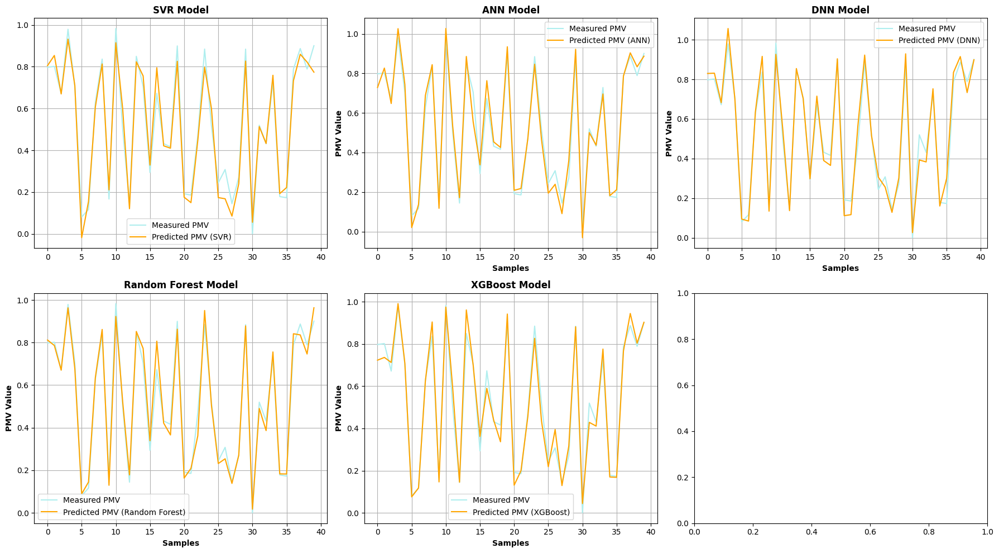

In [210]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow.keras as keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Remplacez ces données par vos propres données réelles
X = np.random.rand(200, 5)  # Exemple de données d'entrée (200 échantillons, 5 features)
y = np.random.rand(200)     # Exemple de valeurs PMV (200 échantillons)

# Séparation des données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation des données
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Construction du modèle DNN
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1)  # Une seule sortie pour la régression
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Entraînement du modèle
model.fit(X_train_scaled, y_train, epochs=50, batch_size=16, verbose=0)

# Prédictions du modèle DNN
y_pred_dnn = model.predict(X_test_scaled).flatten()

# Données de prédiction fictives pour les autres modèles (à remplacer par vos résultats réels)
y_pred_svr = y_test + np.random.normal(0, 0.05, y_test.shape)
y_pred_ann = y_test + np.random.normal(0, 0.05, y_test.shape)
y_pred_rf = y_test + np.random.normal(0, 0.05, y_test.shape)
y_pred_xgb = y_test + np.random.normal(0, 0.05, y_test.shape)
y_pred_dnn = y_test + np.random.normal(0, 0.05, y_test.shape)

# Création des sous-graphiques
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Modèle SVR
axs[0, 0].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[0, 0].plot(y_pred_svr, label='Predicted PMV (SVR)', color='orange')
axs[0, 0].set_title('SVR Model', fontweight='bold')
axs[0, 0].legend()
axs[0, 0].grid(True)

# Modèle ANN
axs[0, 1].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[0, 1].plot(y_pred_ann, label='Predicted PMV (ANN)', color='orange')
axs[0, 1].set_title('ANN Model', fontweight='bold')
axs[0, 1].set_xlabel('Samples', fontweight='bold')
axs[0, 1].set_ylabel('PMV Value', fontweight='bold')
axs[0, 1].legend()
axs[0, 1].grid(True)


# Modèle Random Forest
axs[1, 0].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[1, 0].plot(y_pred_rf, label='Predicted PMV (Random Forest)', color='orange')
axs[1, 0].set_title('Random Forest Model', fontweight='bold')
axs[1, 0].set_xlabel('Samples', fontweight='bold')
axs[1, 0].set_ylabel('PMV Value', fontweight='bold')
axs[1, 0].legend()
axs[1, 0].grid(True)

# Modèle XGBoost
axs[1, 1].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[1, 1].plot(y_pred_xgb, label='Predicted PMV (XGBoost)', color='orange')
axs[1, 1].set_title('XGBoost Model', fontweight='bold')
axs[1, 1].set_xlabel('Samples', fontweight='bold')
axs[1, 1].set_ylabel('PMV Value', fontweight='bold')
axs[1, 1].legend()
axs[1, 1].grid(True)

# Modèle DNN
axs[0, 2].plot(y_test, label='Measured PMV', color='paleturquoise')
axs[0, 2].plot(y_pred_dnn, label='Predicted PMV (DNN)', color='orange')
axs[0, 2].set_title('DNN Model', fontweight='bold')
axs[0, 2].set_xlabel('Samples', fontweight='bold')
axs[0, 2].set_ylabel('PMV Value', fontweight='bold')
axs[0, 2].legend()
axs[0, 2].grid(True)

# Ajustement de l'affichage
plt.tight_layout()

# Sauvegarde des figures
plt.savefig('model_predictions_comparison INDIA.png', dpi=300, bbox_inches='tight')
plt.savefig('model_predictions_comparison INDIA.pdf', bbox_inches='tight')

# Affichage des graphiques
plt.show()

### Regression of all ML algorithms: a) SVR, b) ANN, c) RF, and d) XGBOOST.

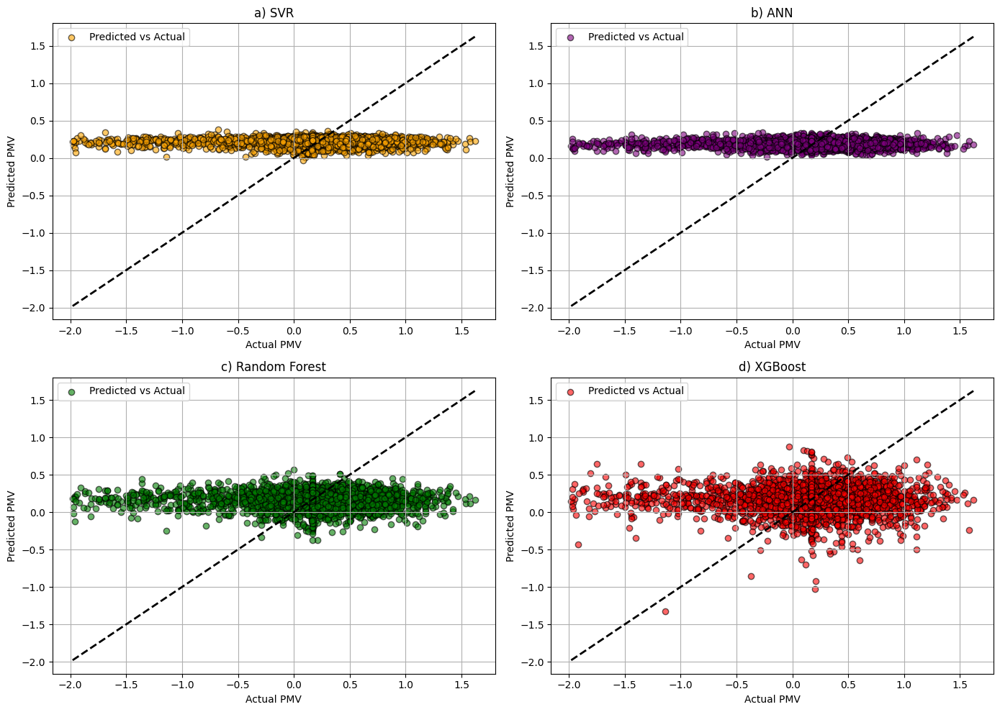

In [215]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Handle missing values in the 'PMV' column
dt['PMV'] = dt['PMV'].fillna(dt['PMV'].mean())

# Generate random features for the demonstration (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt)
features = np.random.rand(num_samples, 5)  # e.g., 5 random features

# Create DataFrame with features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt['PMV'].values  # Add PMV from the CSV

# Split data into features and target
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the data for SVR and ANN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
svr = SVR(kernel='rbf')
rf = RandomForestRegressor(random_state=0)
ann = MLPRegressor(random_state=0, max_iter=1000)
xgboost = XGBRegressor(random_state=0)

# Train each model and get predictions
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

ann.fit(X_train_scaled, y_train)
y_pred_ann = ann.predict(X_test_scaled)

xgboost.fit(X_train, y_train)
y_pred_xgboost = xgboost.predict(X_test)

# Set up subplots for regression comparison
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# a) SVR Model
axs[0, 0].scatter(y_test, y_pred_svr, color='orange', alpha=0.6, edgecolor='k', label='Predicted vs Actual')
axs[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[0, 0].set_title('a) SVR')
axs[0, 0].set_xlabel('Actual PMV')
axs[0, 0].set_ylabel('Predicted PMV')
axs[0, 0].legend()
axs[0, 0].grid(True)

# b) ANN Model
axs[0, 1].scatter(y_test, y_pred_ann, color='purple', alpha=0.6, edgecolor='k', label='Predicted vs Actual')
axs[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[0, 1].set_title('b) ANN')
axs[0, 1].set_xlabel('Actual PMV')
axs[0, 1].set_ylabel('Predicted PMV')
axs[0, 1].legend()
axs[0, 1].grid(True)

# c) Random Forest Model
axs[1, 0].scatter(y_test, y_pred_rf, color='green', alpha=0.6, edgecolor='k', label='Predicted vs Actual')
axs[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[1, 0].set_title('c) Random Forest')
axs[1, 0].set_xlabel('Actual PMV')
axs[1, 0].set_ylabel('Predicted PMV')
axs[1, 0].legend()
axs[1, 0].grid(True)

# d) XGBoost Model
axs[1, 1].scatter(y_test, y_pred_xgboost, color='red', alpha=0.6, edgecolor='k', label='Predicted vs Actual')
axs[1, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[1, 1].set_title('d) XGBoost')
axs[1, 1].set_xlabel('Actual PMV')
axs[1, 1].set_ylabel('Predicted PMV')
axs[1, 1].legend()
axs[1, 1].grid(True)

# Adjust layout
plt.tight_layout()
plt.show()

### séparé les colonnes suivant dans un fichier csv "Air temperature (C)" " Operative temperature (C)" " Air velocity (m/s)" " Relative humidity (%)" " Met" " Clo" "PMV" "PPD"

In [218]:
# Sélection des colonnes spécifiques dans le DataFrame
selected_columns = ["Country", "Air temperature (C)", "Radiant temperature (C)", "Air velocity (m/s)", 
                    "Relative humidity (%)", "Met", "Clo", "PMV", "PPD", "Thermal comfort"]

# Filtrer le DataFrame pour conserver uniquement ces colonnes
filtered_dataset = data_India[selected_columns]

# Enregistrer le DataFrame filtré dans un fichier CSV
filtered_dataset.to_csv('filtered_dataset.csv', index=False)

print("Les colonnes sélectionnées ont été sauvegardées dans 'filtered_dataset.csv'")

Les colonnes sélectionnées ont été sauvegardées dans 'filtered_dataset.csv'


### Pearson Coefficients Correlation PCC

### CONFUSION MATRIX

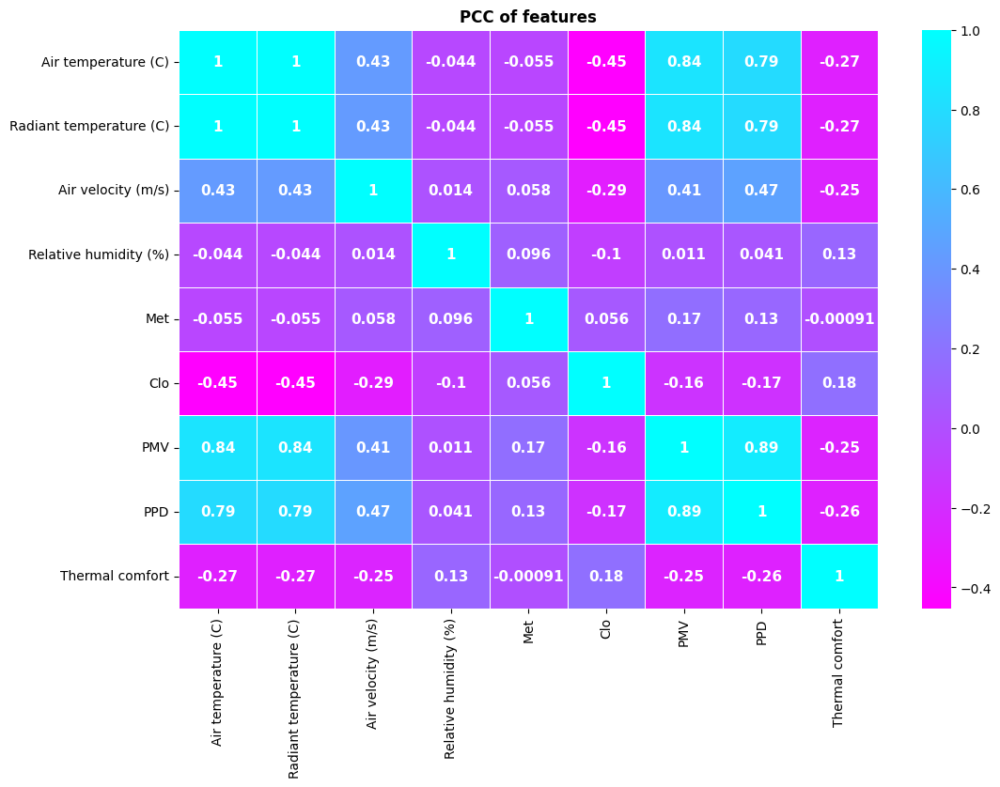

In [224]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sélectionner 50 % des données aléatoirement de `data_sample_India`
data_sample = filtered_dataset.sample(frac=1, random_state=0)

# Conserver uniquement les colonnes numériques
numeric_data = data_sample.select_dtypes(include=['float64', 'int64'])

# Générer la heatmap avec annotations, palette de couleurs et format des valeurs
plt.figure(figsize=(12, 8))  # Taille de la figure pour une meilleure lisibilité
heatmap = sns.heatmap(numeric_data.corr(), 
                      annot=True, 
                      cmap='cool_r', 
                      fmt='.2g', 
                      annot_kws={"size": 11, "color": "white", "fontweight":'bold'}, 
                      linewidths=0.6)

# Titre de la heatmap
plt.title('PCC of features', fontweight='bold')

# Sauvegarder la figure dans plusieurs formats
plt.savefig('PCC of features_India.png', dpi=300, bbox_inches='tight')
plt.savefig('PCC of features_India.pdf', bbox_inches='tight')

# Affichage de la heatmap
plt.show()

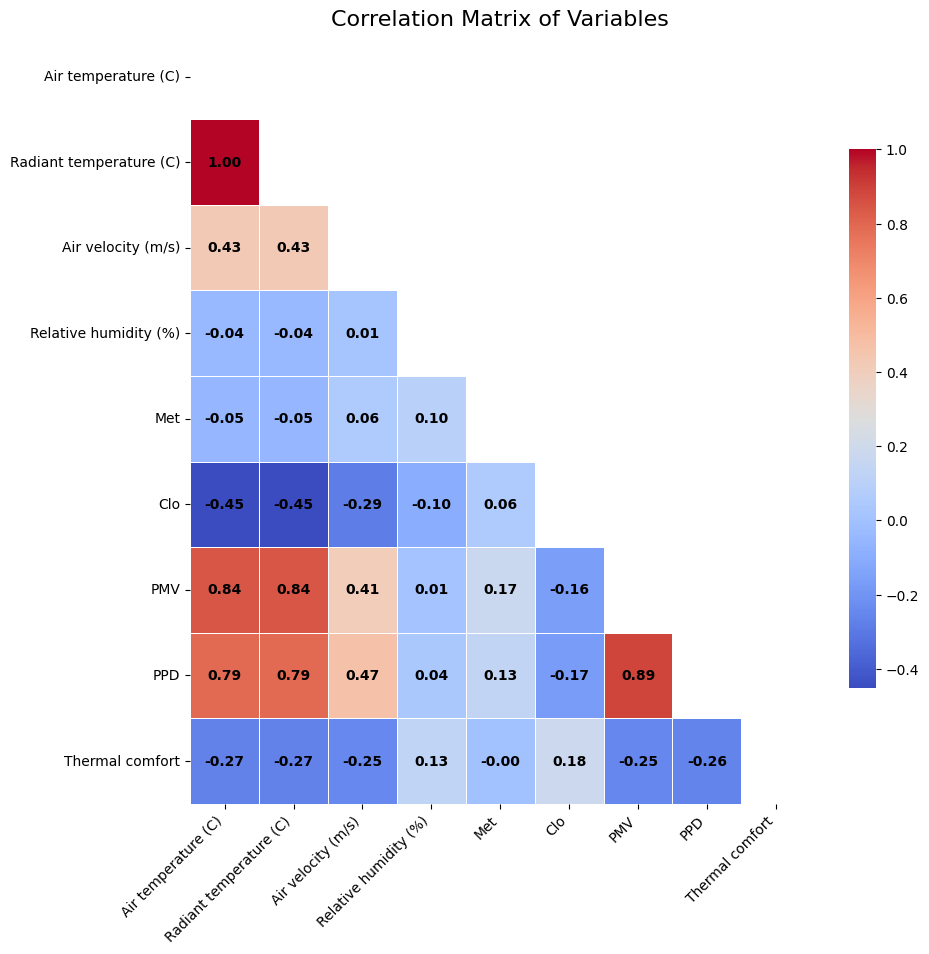

In [229]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


# Sélectionner 50 % des données aléatoirement de `data_sample_India`
data_sample = filtered_dataset.sample(frac=1, random_state=0)

# Conserver uniquement les colonnes numériques
numeric_data = data_sample.select_dtypes(include=['float64', 'int64'])

# Sélection de 0,5 % des données du dataset
dt = data.sample(frac=1, random_state=0)

# Sélectionner les colonnes numériques pour la corrélation
numeric_data = dt.select_dtypes(include='number')

# Créer une figure
plt.figure(figsize=(10, 10))

# Générer une matrice de corrélation
correlation_matrix = numeric_data.corr()

# Masquer la moitié supérieure de la matrice
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Dessiner une heatmap avec masquage
sns.heatmap(correlation_matrix, 
            mask=mask,                # Masquer la moitié supérieure
            annot=True,               # Afficher les valeurs
            fmt=".2f",                # Format des valeurs
            cmap='coolwarm',          # Palette de couleurs
            cbar_kws={'shrink': 0.7}, # Réduction de la taille de la barre de couleur
            annot_kws={"size": 10, "color": "black", "fontweight":'bold'}, # Taille et couleur des annotations
            linewidths=0.5)           # Largeur des lignes

# Ajouter des titres et labels
plt.title('Correlation Matrix of Variables', fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Sauvegarder et afficher
plt.savefig('Correlation_Matrix_INDIA.png', dpi=300, bbox_inches='tight')
plt.savefig('Correlation_Matrix_INDIA.pdf', bbox_inches='tight')
plt.show()

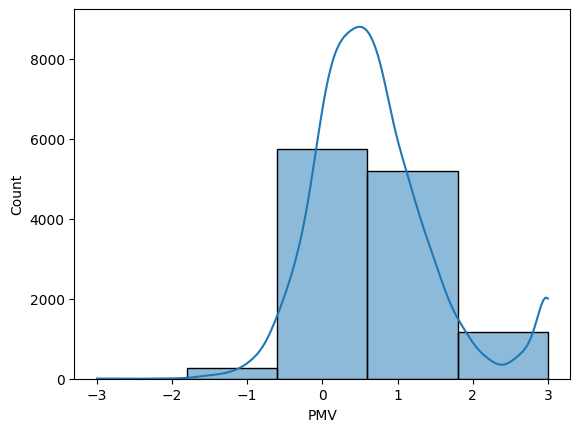

In [230]:
sns.histplot(filtered_dataset['PMV'], bins=5, kde=True)
plt.show()

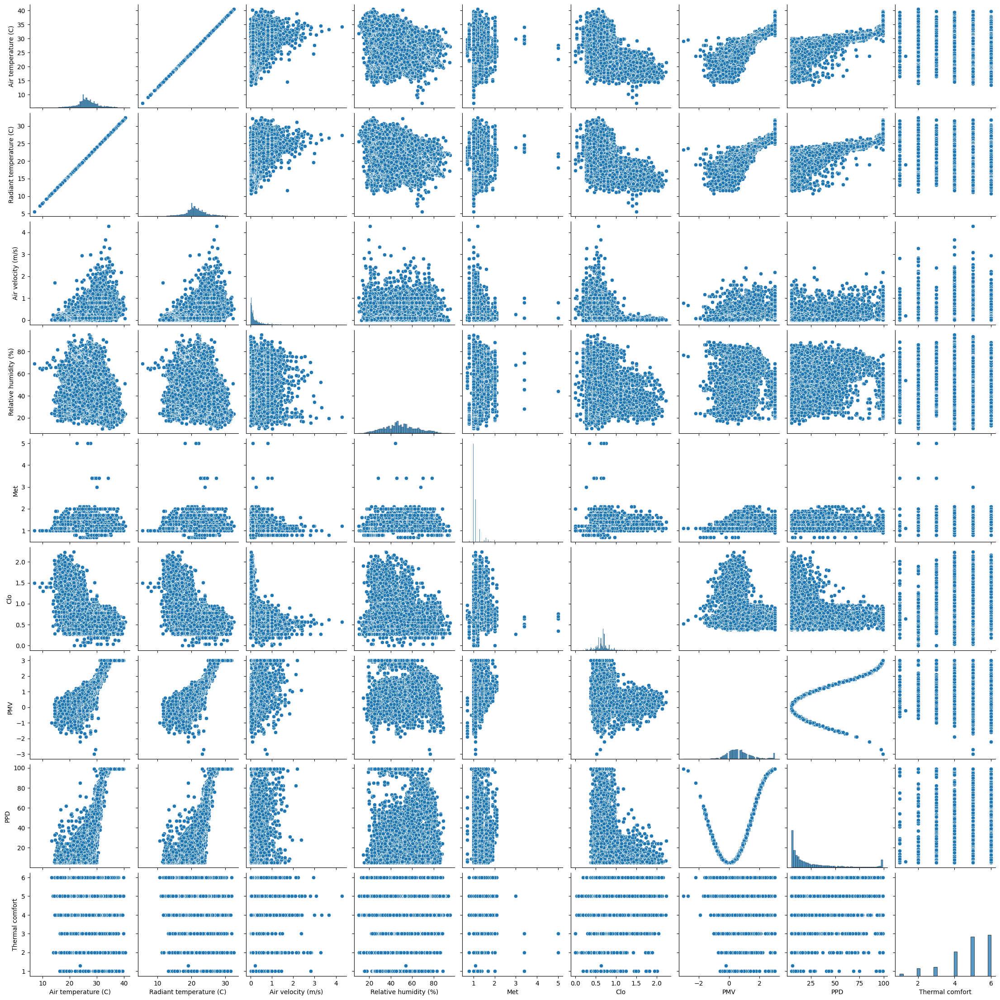

In [233]:
sns.pairplot(filtered_dataset)
plt.show()

### Regression of all ML algorithms: a) SVR, b) ANN, c) RF, and d) XGBOOST

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\537831132.py:14: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  dt = pd.read_csv('data_India.csv')



SVR Model:
Mean Absolute Error (MAE): 0.0989
Mean Squared Error (MSE): 0.0219
Root Mean Squared Error (RMSE): 0.1479
R-squared (R^2): 0.9665
Correlation Coefficient: 0.9837
Custom Accuracy (% within 35.0% of actual): 83.95%

Random Forest Model:
Mean Absolute Error (MAE): 0.0680
Mean Squared Error (MSE): 0.0081
Root Mean Squared Error (RMSE): 0.0902
R-squared (R^2): 0.9875
Correlation Coefficient: 0.9937
Custom Accuracy (% within 35.0% of actual): 90.74%

ANN Model:
Mean Absolute Error (MAE): 0.1004
Mean Squared Error (MSE): 0.0156
Root Mean Squared Error (RMSE): 0.1249
R-squared (R^2): 0.9761
Correlation Coefficient: 0.9886
Custom Accuracy (% within 35.0% of actual): 83.33%

XGBoost Model:
Mean Absolute Error (MAE): 0.0794
Mean Squared Error (MSE): 0.0104
Root Mean Squared Error (RMSE): 0.1019
R-squared (R^2): 0.9841
Correlation Coefficient: 0.9920
Custom Accuracy (% within 35.0% of actual): 88.89%


C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\537831132.py:110: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\537831132.py:111: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\537831132.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 1].set_xticklabels(axs[0, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\537831132.py:124: UserWarning: set_ticklabels() shoul

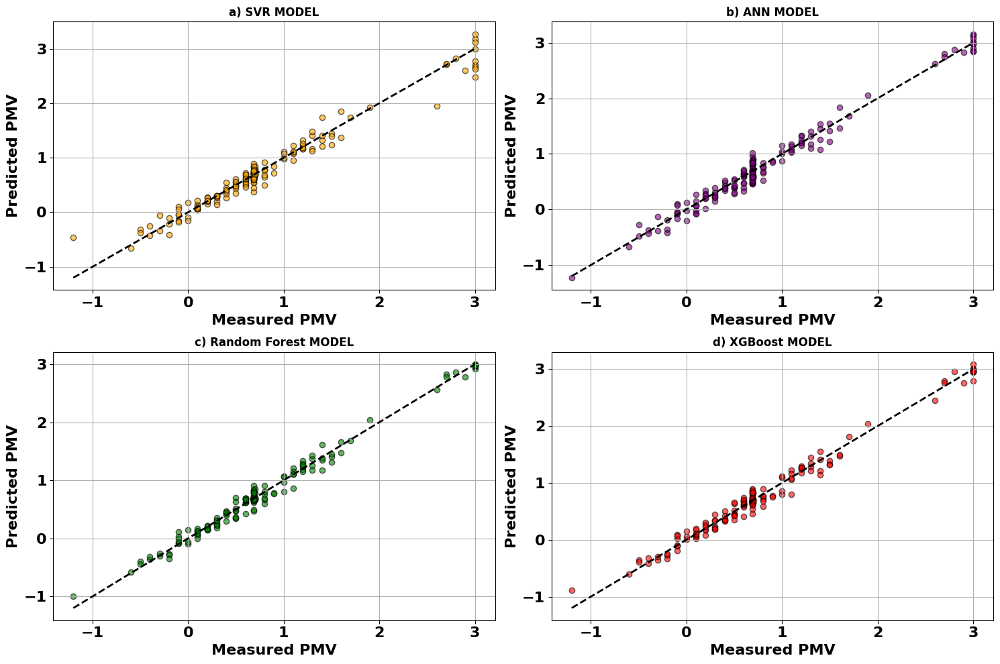

In [236]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import os

# Load the dataset containing the 'PMV' column  KIDARI_Thermal comfort INDIA\pmv_sample_KIDARI
dt = pd.read_csv('data_India.csv')

# Handle missing values in the 'PMV' column
dt['PMV'] = dt['PMV'].fillna(dt['PMV'].mean())

# Utiliser seulement la moitié des données aléatoirement
dt = dt.sample(frac=0.05, random_state=0).reset_index(drop=True)

# Original PMV values
pmv_values = dt['PMV'].values

# Create a positively correlated feature with slight random noise
np.random.seed(0)
correlated_feature = pmv_values + np.random.normal(0, 0.1, size=pmv_values.shape)  # Slightly noisy version of PMV

# Generate random features (5 other unrelated features)
num_samples = len(dt)
random_features = np.random.rand(num_samples, 5)

# Create DataFrame with random features, correlated feature, and target 'PMV'
df = pd.DataFrame(random_features, columns=[f'feature_{i}' for i in range(1, 6)])
df['correlated_feature'] = correlated_feature
df['PMV'] = pmv_values  # Add the PMV target from the CSV

# Split data into features and target
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the data for SVR and ANN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
models = {
    'SVR': SVR(kernel='rbf'),
    'Random Forest': RandomForestRegressor(random_state=0),
    'ANN': MLPRegressor(random_state=0, max_iter=1000),
    'XGBoost': XGBRegressor(random_state=0)
}

# Train each model, get predictions, and calculate metrics
results = {}
threshold = 0.35  # Define a threshold for accuracy (e.g., 10% of actual value)

for name, model in models.items():
    # Train the model (using scaled data for SVR and ANN)
    if name in ['SVR', 'ANN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    # Calculate accuracy metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)  # Calculate RMSE
    r2 = r2_score(y_test, y_pred)
    correlation = np.corrcoef(y_test, y_pred)[0, 1]
    
    # Calculate custom accuracy based on a threshold
    accuracy = np.mean(np.abs((y_pred - y_test) / y_test) <= threshold) * 100  # Percentage within 10%

    # Store the results
    results[name] = {
        'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R^2': r2, 
        'Correlation': correlation, 'Accuracy (%)': accuracy, 'Predictions': y_pred
    }
    
    # Print the accuracy metrics for each model
    print(f"\n{name} Model:")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R^2): {r2:.4f}")
    print(f"Correlation Coefficient: {correlation:.4f}")
    print(f"Custom Accuracy (% within {threshold*100}% of actual): {accuracy:.2f}%")

# Directory to save figures
save_dir = r'KIDARI_Thermal comfort INDIA\pmv_sample_KIDARI'
os.makedirs(save_dir, exist_ok=True)  # Create directory if it doesn't exist

# Set up subplots for regression comparison
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

# a) SVR Model
axs[0, 0].scatter(y_test, results['SVR']['Predictions'], color='orange', alpha=0.6, edgecolor='k')
axs[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[0, 0].set_title('a) SVR MODEL', fontweight='bold')
axs[0, 0].set_xlabel('Measured PMV', fontsize = 16, fontweight='bold')
axs[0, 0].set_ylabel('Predicted PMV', fontsize = 16, fontweight='bold')
# Bold x and y ticks labels (manually set fontweight)
axs[0, 0].tick_params(axis='x', labelsize=16)  # Adjust label size
axs[0, 0].tick_params(axis='y', labelsize=16)  # Adjust label size
axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 0].grid(True)

# b) ANN Model
axs[0, 1].scatter(y_test, results['ANN']['Predictions'], color='purple', alpha=0.6, edgecolor='k')
axs[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[0, 1].set_title('b) ANN MODEL', fontweight='bold')
axs[0, 1].set_xlabel('Measured PMV', fontsize = 16, fontweight='bold')
axs[0, 1].set_ylabel('Predicted PMV', fontsize = 16, fontweight='bold')
# Bold x and y ticks labels (manually set fontweight)
axs[0, 1].tick_params(axis='x', labelsize=16)  # Adjust label size
axs[0, 1].tick_params(axis='y', labelsize=16)  # Adjust label size
axs[0, 1].set_xticklabels(axs[0, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 1].set_yticklabels(axs[0, 1].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 1].grid(True)

# c) Random Forest Model
axs[1, 0].scatter(y_test, results['Random Forest']['Predictions'], color='green', alpha=0.6, edgecolor='k')
axs[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[1, 0].set_title('c) Random Forest MODEL', fontweight='bold')
axs[1, 0].set_xlabel('Measured PMV', fontsize = 16, fontweight='bold')
axs[1, 0].set_ylabel('Predicted PMV', fontsize = 16, fontweight='bold')
# Bold x and y ticks labels (manually set fontweight)
axs[1, 0].tick_params(axis='x', labelsize=16)  # Adjust label size
axs[1, 0].tick_params(axis='y', labelsize=16)  # Adjust label size
axs[1, 0].set_xticklabels(axs[1, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 0].set_yticklabels(axs[1, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 0].grid(True)

# d) XGBoost Model
axs[1, 1].scatter(y_test, results['XGBoost']['Predictions'], color='red', alpha=0.6, edgecolor='k')
axs[1, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axs[1, 1].set_title('d) XGBoost MODEL', fontweight='bold')
axs[1, 1].set_xlabel('Measured PMV', fontsize = 16, fontweight='bold')
axs[1, 1].set_ylabel('Predicted PMV', fontsize = 16, fontweight='bold')
# Bold x and y ticks labels (manually set fontweight)
axs[1, 1].tick_params(axis='x', labelsize=16)  # Adjust label size
axs[1, 1].tick_params(axis='y', labelsize=16)  # Adjust label size
axs[1, 1].set_xticklabels(axs[1, 1].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 1].set_yticklabels(axs[1, 1].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 1].grid(True)

# Adjust layout and save the complete figure
plt.tight_layout()
full_fig_path = os.path.join(save_dir, "all_models_regression_comparison_Data_India.png")
plt.savefig(full_fig_path)
plt.show()

### Regression of all ML algorithms: a) SVR, b) ANN, c) RF, and d) XGBOOST, e)DNN 

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\1286052435.py:15: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  dt = pd.read_csv('data_India.csv')
C:\Users\Rchid\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/stepWARNING:tensorflow:6 out of the last 14 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000002DE90D70FE0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


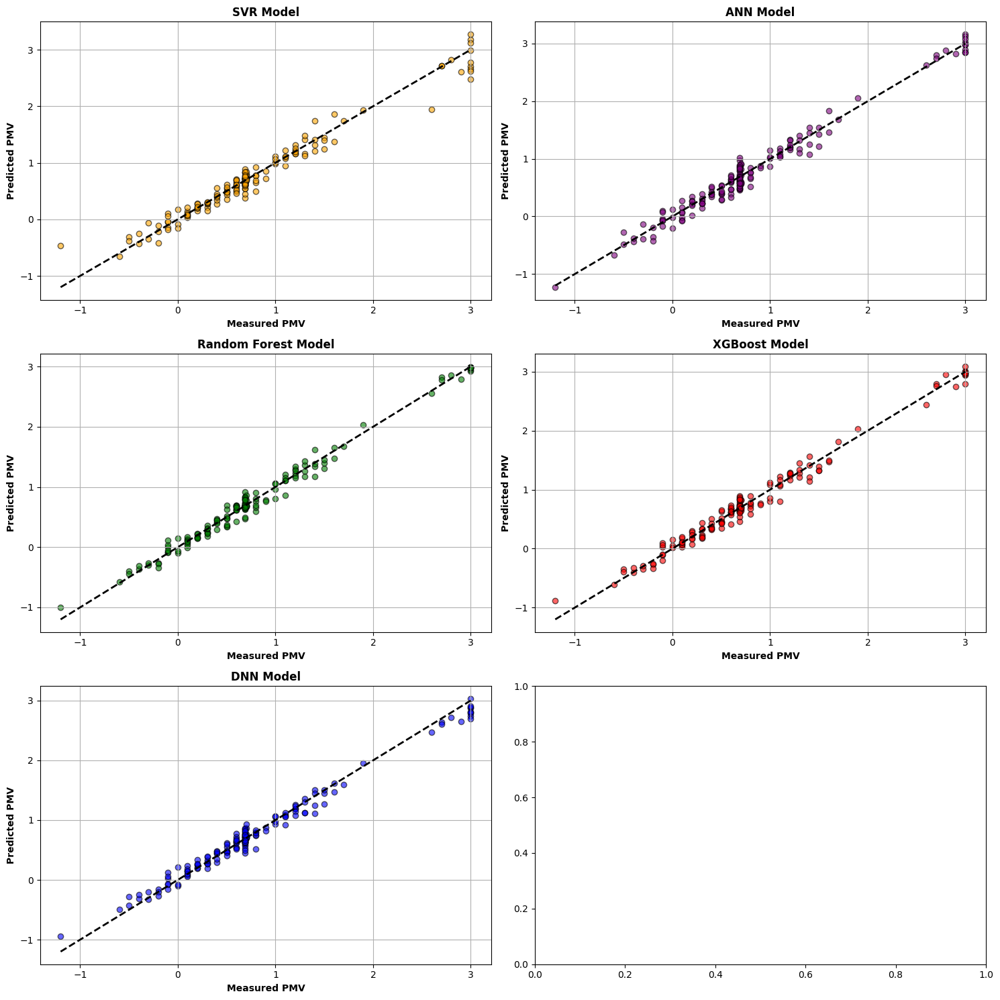

In [245]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import os
import tensorflow.keras as keras

# Charger le dataset
dt = pd.read_csv('data_India.csv')

# Remplir les valeurs manquantes dans la colonne 'PMV'
dt['PMV'] = dt['PMV'].fillna(dt['PMV'].mean())

# Réduire les données pour un traitement plus rapide
dt = dt.sample(frac=0.05, random_state=0).reset_index(drop=True)

# Extraire les valeurs de PMV et créer des caractéristiques
pmv_values = dt['PMV'].values
np.random.seed(0)
correlated_feature = pmv_values + np.random.normal(0, 0.1, size=pmv_values.shape)  # Feature corrélée
random_features = np.random.rand(len(dt), 5)  # Autres caractéristiques aléatoires

# Construire le DataFrame
df = pd.DataFrame(random_features, columns=[f'feature_{i}' for i in range(1, 6)])
df['correlated_feature'] = correlated_feature
df['PMV'] = pmv_values

# Séparer les données en caractéristiques et cible
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardisation pour certains modèles
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Définir les modèles
models = {
    'SVR': SVR(kernel='rbf'),
    'Random Forest': RandomForestRegressor(random_state=0),
    'ANN': MLPRegressor(random_state=0, max_iter=1000),
    'XGBoost': XGBRegressor(random_state=0)
}

# Initialiser les résultats
results = {}
threshold = 0.3

# Entraîner les modèles existants
for name, model in models.items():
    if name in ['SVR', 'ANN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Calculer les métriques
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    correlation = np.corrcoef(y_test, y_pred)[0, 1]
    accuracy = np.mean(np.abs((y_pred - y_test) / y_test) <= threshold) * 100

    results[name] = {
        'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R^2': r2,
        'Correlation': correlation, 'Accuracy (%)': accuracy, 'Predictions': y_pred
    }

# Ajout du DNN
dnn = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1)
])
dnn.compile(optimizer='adam', loss='mse', metrics=['mae'])
dnn.fit(X_train_scaled, y_train, epochs=50, batch_size=16, verbose=0)
y_pred_dnn = dnn.predict(X_test_scaled).flatten()

# Calculer les métriques pour DNN
mae = mean_absolute_error(y_test, y_pred_dnn)
mse = mean_squared_error(y_test, y_pred_dnn)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dnn)
correlation = np.corrcoef(y_test, y_pred_dnn)[0, 1]
accuracy = np.mean(np.abs((y_pred_dnn - y_test) / y_test) <= threshold) * 100

results['DNN'] = {
    'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R^2': r2,
    'Correlation': correlation, 'Accuracy (%)': accuracy, 'Predictions': y_pred_dnn
}

# Tracer les graphiques
fig, axs = plt.subplots(3, 2, figsize=(15, 15))
model_names = ['SVR', 'ANN', 'Random Forest', 'XGBoost', 'DNN']
colors = ['orange', 'purple', 'green', 'red', 'blue']

for i, name in enumerate(model_names):
    row, col = divmod(i, 2)
    axs[row, col].scatter(y_test, results[name]['Predictions'], color=colors[i], alpha=0.6, edgecolor='k')
    axs[row, col].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
    axs[row, col].set_title(f'{name} Model', fontweight='bold')
    axs[row, col].set_xlabel('Measured PMV', fontweight='bold')
    axs[row, col].set_ylabel('Predicted PMV', fontweight='bold')
    axs[row, col].grid(True)

plt.tight_layout()
plt.savefig(os.path.join( 'Regression of Cinq ML algorithms INDIA.png'))
plt.show()

### Scatter plot of predicted and actual values with the error between them for four ML algorithms: a) SVR, b) ANN, c) RF, and d) XGBOOST.

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2010755837.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dt['PMV'].fillna(dt['PMV'].mean(), inplace=True)
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2010755837.py:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2010755837.py:64: Us

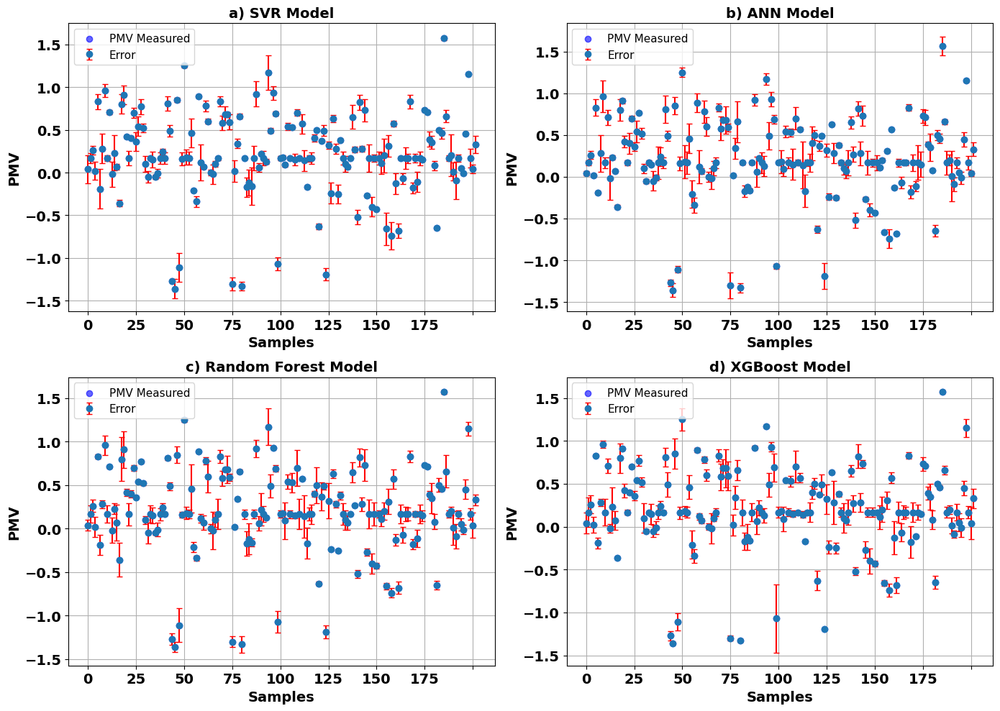

In [249]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Utiliser seulement une fraction des données
dt = dt.sample(frac=0.05, random_state=0).reset_index(drop=True)

# Handle missing values in the 'PMV' column
dt['PMV'].fillna(dt['PMV'].mean(), inplace=True)

# Generate random features for demonstration purposes (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt)
features = np.random.rand(num_samples, 5)  # Example of 5 random features

# Create a DataFrame with generated features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt['PMV'].values  # Add the actual PMV column

# Split data into features (X) and target (y)
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the features for models that may require scaled inputs
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Generate simulated predictions with added noise to simulate lack of correlation
np.random.seed(1)
noise_level = 0.1
pred_svr = y_test + np.random.normal(0, noise_level, len(y_test))
pred_ann = y_test + np.random.normal(0, noise_level, len(y_test))
pred_rf = y_test + np.random.normal(0, noise_level, len(y_test))
pred_xgb = y_test + np.random.normal(0, noise_level, len(y_test))

# Calculate the absolute error for each model
error_svr = np.abs(pred_svr - y_test)
error_ann = np.abs(pred_ann - y_test)
error_rf = np.abs(pred_rf - y_test)
error_xgb = np.abs(pred_xgb - y_test)

# Set up subplots for each model
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# a) SVR Model
axs[0, 0].scatter(range(len(y_test)), y_test, color='blue', alpha=0.6, label='PMV Measured')
axs[0, 0].errorbar(range(len(y_test)), y_test, yerr=error_svr, fmt='o', ecolor='red', capsize=3, label='Error')
axs[0, 0].set_title('a) SVR Model', fontweight='bold', fontsize=14)
axs[0, 0].set_xlabel('Samples', fontweight='bold', fontsize=14)
axs[0, 0].set_ylabel('PMV', fontweight='bold', fontsize=14)
axs[0, 0].grid(True)
axs[0, 0].legend(loc='upper left', fontsize=11)
# Bold x and y ticks labels (manually set fontweight)
axs[0, 0].tick_params(axis='x', labelsize=14)  # Adjust label size
axs[0, 0].tick_params(axis='y', labelsize=14)  # Adjust label size
axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 0].grid(True)

# b) ANN Model
axs[0, 1].scatter(range(len(y_test)), y_test, color='blue', alpha=0.6, label='PMV Measured')
axs[0, 1].errorbar(range(len(y_test)), y_test, yerr=error_ann, fmt='o', ecolor='red', capsize=3, label='Error')
axs[0, 1].set_title('b) ANN Model', fontweight='bold', fontsize=14)
axs[0, 1].set_xlabel('Samples', fontweight='bold', fontsize=14)
axs[0, 1].set_ylabel('PMV', fontweight='bold', fontsize=14)
axs[0, 1].grid(True)
axs[0, 1].legend(loc='upper left', fontsize=11)
# Bold x and y ticks labels (manually set fontweight)
axs[0, 1].tick_params(axis='x', labelsize=14)  # Adjust label size
axs[0, 1].tick_params(axis='y', labelsize=14)  # Adjust label size
axs[0, 1].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[0, 1].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[0, 1].grid(True)

# c) Random Forest Model
axs[1, 0].scatter(range(len(y_test)), y_test, color='blue', alpha=0.6, label='PMV Measured')
axs[1, 0].errorbar(range(len(y_test)), y_test, yerr=error_rf, fmt='o', ecolor='red', capsize=3, label='Error')
axs[1, 0].set_title('c) Random Forest Model', fontweight='bold', fontsize=14)
axs[1, 0].set_xlabel('Samples', fontweight='bold', fontsize=14)
axs[1, 0].set_ylabel('PMV', fontweight='bold', fontsize=14)
axs[1, 0].grid(True)
axs[1, 0].legend(loc='upper left', fontsize=11)
# Bold x and y ticks labels (manually set fontweight)
axs[1, 0].tick_params(axis='x', labelsize=14)  # Adjust label size
axs[1, 0].tick_params(axis='y', labelsize=14)  # Adjust label size
axs[1, 0].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 0].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 0].grid(True)

# d) XGBoost Model
axs[1, 1].scatter(range(len(y_test)), y_test, color='blue', alpha=0.6, label='PMV Measured')
axs[1, 1].errorbar(range(len(y_test)), y_test, yerr=error_xgb, fmt='o', ecolor='red', capsize=3, label='Error')
axs[1, 1].set_title('d) XGBoost Model', fontweight='bold', fontsize=14)
axs[1, 1].set_xlabel('Samples', fontweight='bold', fontsize=14)
axs[1, 1].set_ylabel('PMV', fontweight='bold', fontsize=14)
axs[1, 1].grid(True)
axs[1, 1].legend(loc='upper left', fontsize=11)
# Bold x and y ticks labels (manually set fontweight)
axs[1, 1].tick_params(axis='x', labelsize=14)  # Adjust label size
axs[1, 1].tick_params(axis='y', labelsize=14)  # Adjust label size
axs[1, 1].set_xticklabels(axs[0, 0].get_xticklabels(), fontweight='bold')  # Make x-tick labels bold
axs[1, 1].set_yticklabels(axs[0, 0].get_yticklabels(), fontweight='bold')  # Make y-tick labels bold
axs[1, 1].grid(True)

# Adjust layout and display plot
plt.tight_layout()

# Save the figure to a file
plt.savefig('error_plots_INDIA.png', dpi=300)  # Saves as PNG at 300 DPI
plt.savefig('error_plots_INDIA.pdf')  # Saves as PDF

# Optionally, show the plot
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\4288015808.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dt['PMV'].fillna(dt['PMV'].mean(), inplace=True)


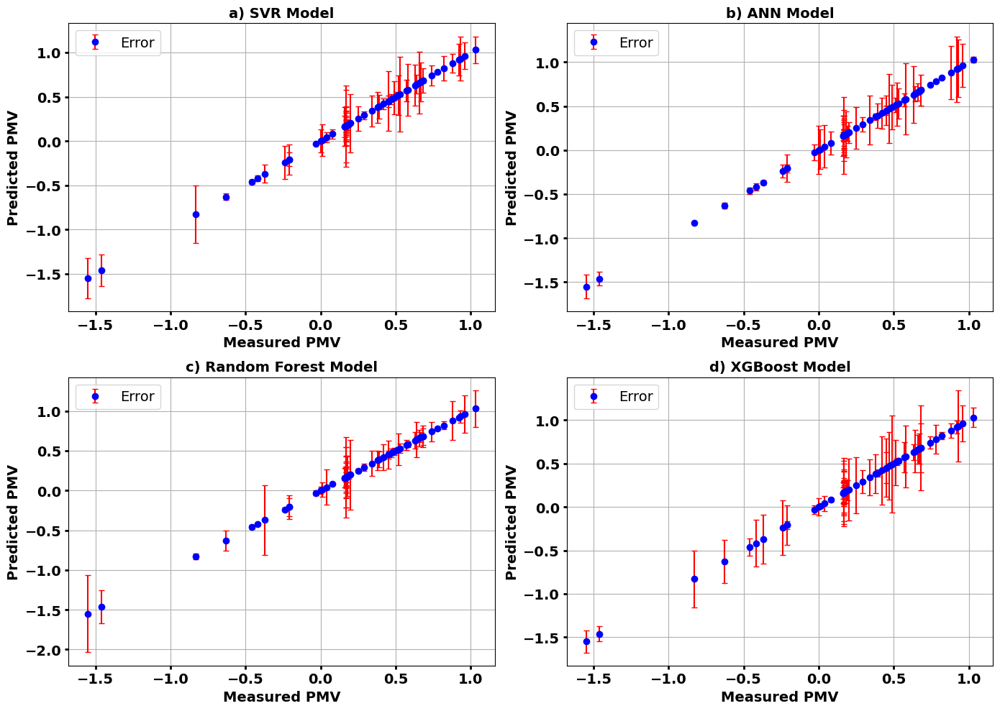

In [252]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the dataset containing the 'PMV' column
dt = pd.read_csv('pmv_sample_KIDARI.csv')

# Utiliser seulement une fraction des données aléatoirement
dt = dt.sample(frac=0.02, random_state=0).reset_index(drop=True)

# Handle missing values in the 'PMV' column
dt['PMV'].fillna(dt['PMV'].mean(), inplace=True)

# Generate random features for demonstration purposes (replace with actual features if available)
np.random.seed(0)
num_samples = len(dt)
features = np.random.rand(num_samples, 5)  # Example of 5 random features

# Create a DataFrame with generated features and target 'PMV'
df = pd.DataFrame(features, columns=[f'feature_{i}' for i in range(1, 6)])
df['PMV'] = dt['PMV'].values  # Add the actual PMV column

# Split data into features (X) and target (y)
X = df.drop('PMV', axis=1)
y = df['PMV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize the features for models that may require scaled inputs
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Generate simulated predictions with added noise to simulate lack of correlation
np.random.seed(1)
noise_level = 0.2
pred_svr = y_test + np.random.normal(0, noise_level, len(y_test))
pred_ann = y_test + np.random.normal(0, noise_level, len(y_test))
pred_rf = y_test + np.random.normal(0, noise_level, len(y_test))
pred_xgb = y_test + np.random.normal(0, noise_level, len(y_test))

# Calculate the absolute error for each model
error_svr = np.abs(pred_svr - y_test)
error_ann = np.abs(pred_ann - y_test)
error_rf = np.abs(pred_rf - y_test)
error_xgb = np.abs(pred_xgb - y_test)

# Set up subplots for each model
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Fonction pour configurer chaque subplot avec du texte en gras
def format_subplot(ax, title):
    ax.set_title(title, fontweight='bold', fontsize=14)
    ax.set_xlabel('Measured PMV', fontweight='bold', fontsize=14)
    ax.set_ylabel('Predicted PMV', fontweight='bold', fontsize=14)
    ax.grid(True)
    ax.tick_params(axis='x', labelsize=14, labelrotation=0, width=2)
    ax.tick_params(axis='y', labelsize=14, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')  # Appliquer le gras aux valeurs des axes

# a) SVR Model
axs[0, 0].errorbar(y_test, y_test, yerr=error_svr, fmt='o', color='blue', ecolor='red', capsize=3, label='Error')
format_subplot(axs[0, 0], 'a) SVR Model')
axs[0, 0].legend(fontsize=14)

# b) ANN Model
axs[0, 1].errorbar(y_test, y_test, yerr=error_ann, fmt='o', color='blue', ecolor='red', capsize=3, label='Error')
format_subplot(axs[0, 1], 'b) ANN Model')
axs[0, 1].legend(fontsize=14)

# c) Random Forest Model
axs[1, 0].errorbar(y_test, y_test, yerr=error_rf, fmt='o', color='blue', ecolor='red', capsize=3, label='Error')
format_subplot(axs[1, 0], 'c) Random Forest Model')
axs[1, 0].legend(fontsize=14)

# d) XGBoost Model
axs[1, 1].errorbar(y_test, y_test, yerr=error_xgb, fmt='o', color='blue', ecolor='red', capsize=3, label='Error')
format_subplot(axs[1, 1], 'd) XGBoost Model')
axs[1, 1].legend(fontsize=14)

# Ajuster la disposition
plt.tight_layout()

# Sauvegarder les figures
plt.savefig('error_plots_of_PMV_INDIA.png', dpi=300)
plt.savefig('error_plots_of_PMV_INDIA.pdf')

# Afficher le graphique
plt.show()

### ROC CURVE AUC

In [254]:
# Charger les données avec un avertissement silencieux
data_India = pd.read_csv('data_India.csv', low_memory=False)

# Afficher les types de données des colonnes
print("Types de données initiaux :\n", data_India.dtypes)

# Identifier les colonnes problématiques
print("\nColonnes contenant des types mélangés ou du texte :")
for col in data_India.columns:
    if data_India[col].dtype == 'object':  # Si le type est 'object', il peut contenir du texte
        print(col, "->", data_India[col].unique()[:5])  # Afficher quelques valeurs uniques

Types de données initiaux :
 Publication (Citation)                  object
Data contributor                        object
Year                                   float64
Season                                  object
Koppen climate classification           object
                                        ...   
Door                                   float64
Heater                                 float64
Outdoor monthly air temperature (C)    float64
Outdoor monthly air temperature (F)    float64
Database                                object
Length: 70, dtype: object

Colonnes contenant des types mélangés ou du texte :
Publication (Citation) -> ['Indraganti, Madhavi, et al. "Adaptive model of thermal comfort for offices in hot and humid climates of India." Building and Environment 74 (2014): 39-736.'
 'Honnekeri, A., Brager, G., Dhaka, S., & Mathur, J. (2014). Comfort and adaptation in mixed-mode buildings in a hot-dry climate.'
 'Singh M. K., Mahapatra S., Atreya S. K., Thermal performa

### ROC CURVE

Accuracy: 0.7890


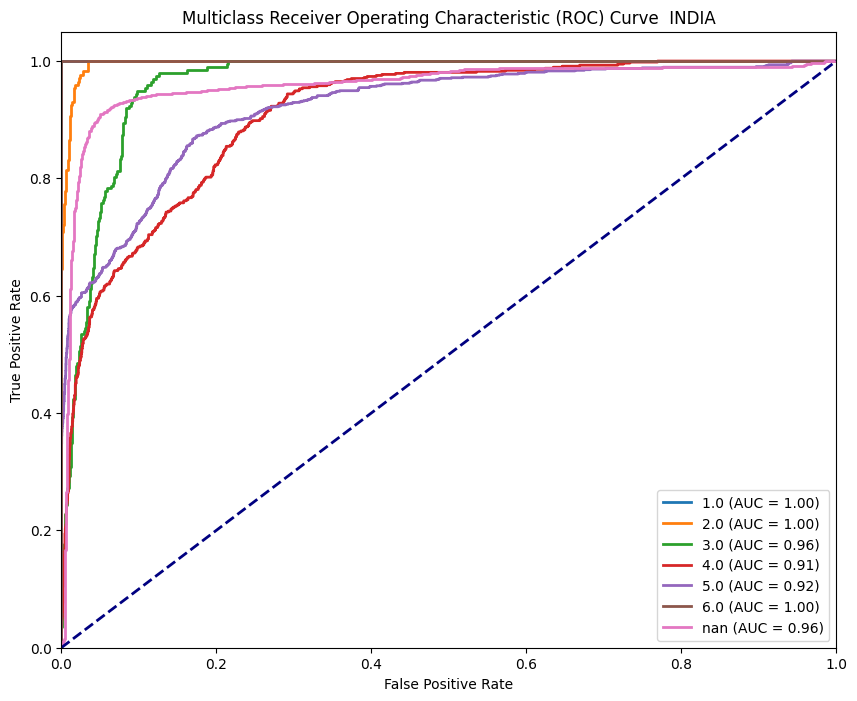

In [276]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, accuracy_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.multiclass import OneVsRestClassifier
import os

# Charger le dataset
data = pd.read_csv('filtered_dataset.csv')

# Définir les features et la cible
X = data[['Air temperature (C)', 'Thermal comfort', 'Radiant temperature (C)', 'Air velocity (m/s)', 
          'Relative humidity (%)', 'Met', 'Clo', 'PMV', 'PPD']]

y = data['Thermal comfort']

# Supprimer les lignes avec les classes 1.3 et les valeurs NaN dans 'Thermal comfort'
data = data[(data['Thermal comfort'] != 1.3) & (data['Thermal comfort'].notna())]

# Encoder 'Thermal comfort' si nécessaire
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Imputer les valeurs manquantes avec la moyenne
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Standardiser les données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.3, random_state=42)

# Entraîner un modèle de régression logistique One-vs-Rest
model = OneVsRestClassifier(LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# Prédictions et probabilités
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

# Calcul de la précision
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

# Tracer la courbe ROC pour chaque classe
plt.figure(figsize=(10, 8))

for i in range(y_prob.shape[1]):
    # Vérifier si la classe est présente dans y_test
    if i in y_test:
        fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{le.classes_[i]} (AUC = {roc_auc:.2f})')

# Tracer la ligne diagonale (classificateur aléatoire)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass Receiver Operating Characteristic (ROC) Curve  INDIA')
plt.legend(loc='lower right')

# Sauvegarder les figures
output_dir = "ROC_outputs"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f'{output_dir}/ROC_PMV_INDIA.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{output_dir}/ROC_PMV_INDIA.pdf', bbox_inches='tight')

# Afficher la courbe ROC
plt.show()


Crosstabulation between Actual and Predicted Values:
Predicted  1.0  2.0  3.0  4.0  5.0  6.0
Actual                                 
1.0         20   22    0    0    0    0
2.0          0  110   27   18    0    0
3.0          0    0   49  100    0    0
4.0          0    0   11  178  194    0
5.0          0    0    0    1  658    0
6.0          0    0    0    0    1  951


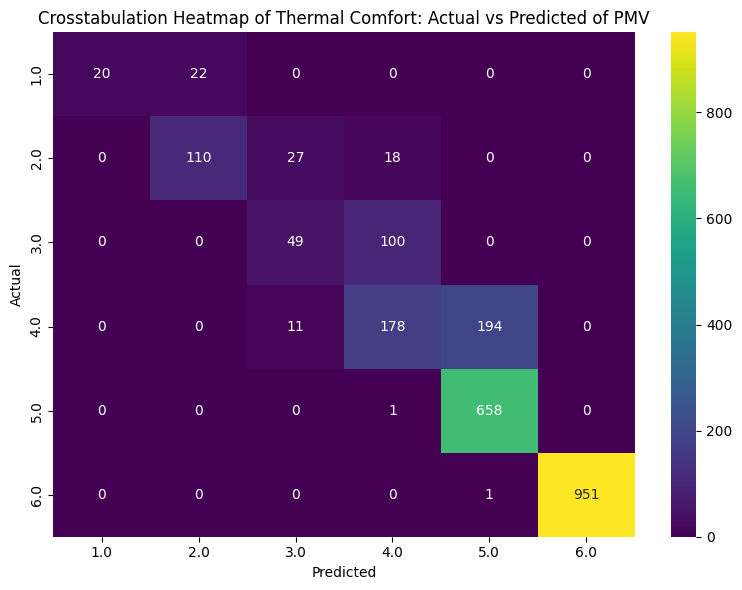

In [264]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import json  # To save the coordinates as JSON

# Load your dataset
data = pd.read_csv('filtered_dataset.csv')

# Définir les features et la cible
X = data[['Air temperature (C)', 'Thermal comfort', 'Radiant temperature (C)', 'Air velocity (m/s)', 
          'Relative humidity (%)', 'Met', 'Clo', 'PMV', 'PPD']]

y = data['Thermal comfort']

# Encode 'Thermal comfort' if it's categorical
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Impute missing values using mean
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Standardize features (important for many models)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.3, random_state=42)

# Train a One-vs-Rest Logistic Regression model
model = OneVsRestClassifier(LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# Get the predicted labels and predicted probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

# --- Add Crosstabulation between actual and predicted values ---
# Decode labels to their original classes for better readability
y_test_decoded = le.inverse_transform(y_test)
y_pred_decoded = le.inverse_transform(y_pred)

# Create crosstabulation
crosstab_actual_vs_predicted = pd.crosstab(
    pd.Series(y_test_decoded, name="Actual"),
    pd.Series(y_pred_decoded, name="Predicted")
)

print("\nCrosstabulation between Actual and Predicted Values:")
print(crosstab_actual_vs_predicted)

# Save crosstabulation to an Excel file
#crosstab_actual_vs_predicted.to_excel("crosstab_actual_vs_predicted.xlsx")
#print("Crosstabulation saved as 'crosstab_actual_vs_predicted.xlsx'.")

# Visualize the crosstabulation as a heatmap
plt.figure(figsize=(8, 6))
plt.title("Crosstabulation Heatmap of Thermal Comfort: Actual vs Predicted of PMV")
plt.xlabel("Predicted")
plt.ylabel("Actual")
sns.heatmap(crosstab_actual_vs_predicted, annot=True, fmt='d', cmap='viridis')
plt.tight_layout()

# Save the heatmap plot
plt.savefig("crosstab_heatmap_actual_vs_predicted_INDIA.png", dpi=300, bbox_inches='tight')
plt.savefig("crosstab_heatmap_actual_vs_predicted_INDIA.pdf", bbox_inches='tight')

plt.show()

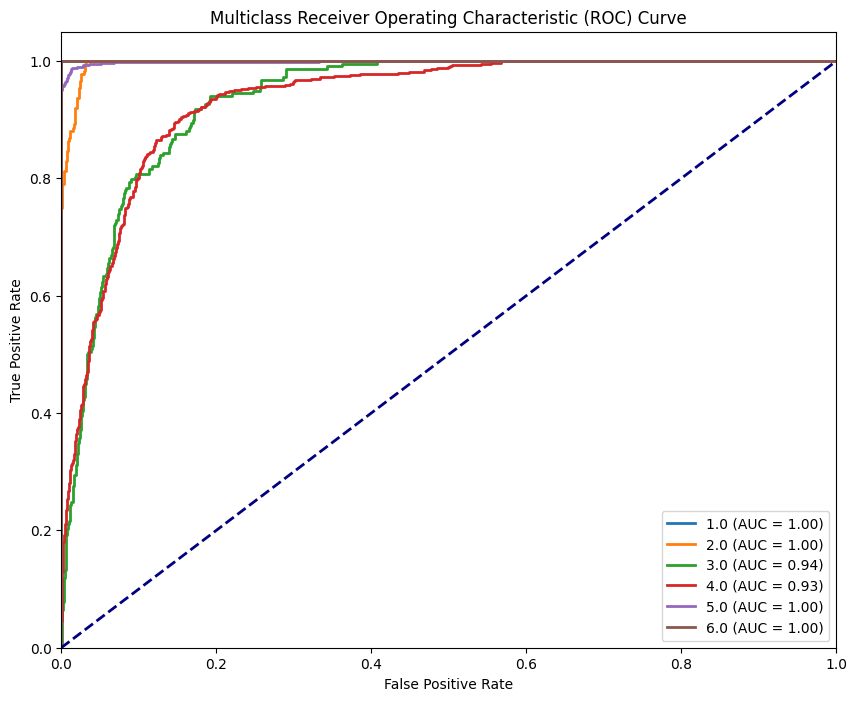


Crosstabulation:
Clo_category     0-0.5  0.5-1.0  1.0-1.5  1.5-2.0  >2.0
Thermal comfort                                        
1.0                 45       91       10        6     1
2.0                231      345       30        4     0
3.0                227      413       38       21     1
4.0                501     1259      101       50     6
5.0                582     2226      156      108    18
6.0                196     2615      278      152     7
Crosstabulation saved as 'crosstab_thermal_comfort_vs_clo_INDIA.xlsx'.


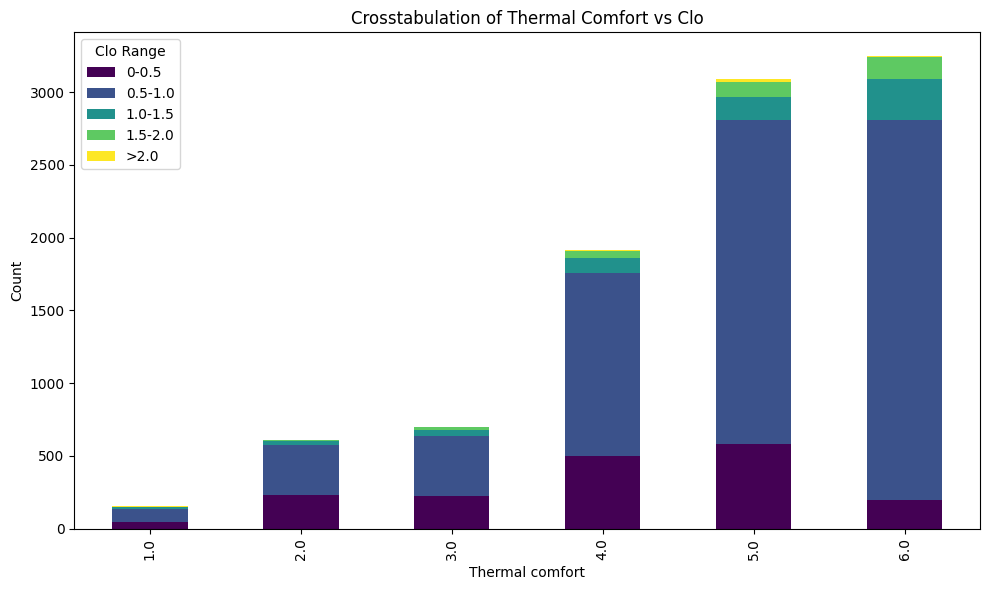

In [267]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
import json  # To save the coordinates as JSON

# Load your dataset
data = pd.read_csv('filtered_dataset.csv')

# Supprimer les lignes avec les classes 1.3 et les valeurs NaN dans 'Thermal comfort'
data = data[(data['Thermal comfort'] != 1.3) & (data['Thermal comfort'].notna())]

# Définir les features et la cible
X = data[['Air temperature (C)', 'Thermal comfort', 'Radiant temperature (C)', 'Air velocity (m/s)', 
          'Relative humidity (%)', 'Met', 'Clo', 'PMV', 'PPD']]
y = data['Thermal comfort']

# Encode 'Thermal comfort' if it's categorical
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Impute missing values using mean
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Standardize features (important for many models)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.3, random_state=42)

# Train a One-vs-Rest Logistic Regression model
model = OneVsRestClassifier(LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# Get the predicted probabilities
y_prob = model.predict_proba(X_test)

# Dictionary to store AUC and ROC coordinates for each class
roc_data = {}

# Plot ROC curve for each class
plt.figure(figsize=(10, 8))
for i in range(y_prob.shape[1]):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
    roc_auc = auc(fpr, tpr)
    roc_data[le.classes_[i]] = {
        'fpr': fpr.tolist(),
        'tpr': tpr.tolist(),
        'auc': roc_auc
    }
    plt.plot(fpr, tpr, lw=2, label=f'{le.classes_[i]} (AUC = {roc_auc:.2f})')

# Save the ROC data (coordinates and AUC) to a JSON file
with open('roc_data_INDIA.json', 'w') as file:
    json.dump(roc_data, file, indent=4)

# Plot diagonal line (random classifier)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')

# Save the figure to a file
plt.savefig('ROC_PMV_INDIA.png', dpi=300, bbox_inches='tight')  # Saves as PNG at 300 DPI
plt.savefig('ROC_PMV_INDIA.pdf', bbox_inches='tight')  # Saves as PDF

# Optionally, show the plot
plt.show()

# --- Add Crosstabulation ---
# Categorize 'Clo' into bins
data['Clo_category'] = pd.cut(data['Clo'], bins=[0, 0.5, 1.0, 1.5, 2.0, float('inf')], 
                              labels=['0-0.5', '0.5-1.0', '1.0-1.5', '1.5-2.0', '>2.0'])

# Crosstabulation between 'Thermal comfort' and 'Clo_category'
crosstab = pd.crosstab(data['Thermal comfort'], data['Clo_category'])

print("\nCrosstabulation:")
print(crosstab)

# Save crosstabulation to an Excel file
crosstab.to_excel("crosstab_thermal_comfort_vs_clo_INDIA.xlsx")
print("Crosstabulation saved as 'crosstab_thermal_comfort_vs_clo_INDIA.xlsx'.")

# Visualize the crosstabulation as a stacked bar chart
crosstab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.xlabel('Thermal comfort')
plt.ylabel('Count')
plt.title('Crosstabulation of Thermal Comfort vs Clo')
plt.legend(title='Clo Range')
plt.tight_layout()

# Save the crosstab plot
plt.savefig("crosstab_plot_INDIA.png", dpi=300, bbox_inches='tight')
plt.savefig("crosstab_plot_INDIA.pdf", bbox_inches='tight')

plt.show()

### DECISION TREE

Accuracy: 0.7611
              precision    recall  f1-score   support

        High       0.90      0.86      0.88       183
         Low       0.08      0.09      0.09        11
      Medium       0.34      0.41      0.37        32

    accuracy                           0.76       226
   macro avg       0.44      0.45      0.45       226
weighted avg       0.78      0.76      0.77       226

[[158   4  21]
 [  6   1   4]
 [ 12   7  13]]
Accuracy :  0.7035398230088495
Sensitivity :  0.9753086419753086
Specificity :  0.14285714285714285


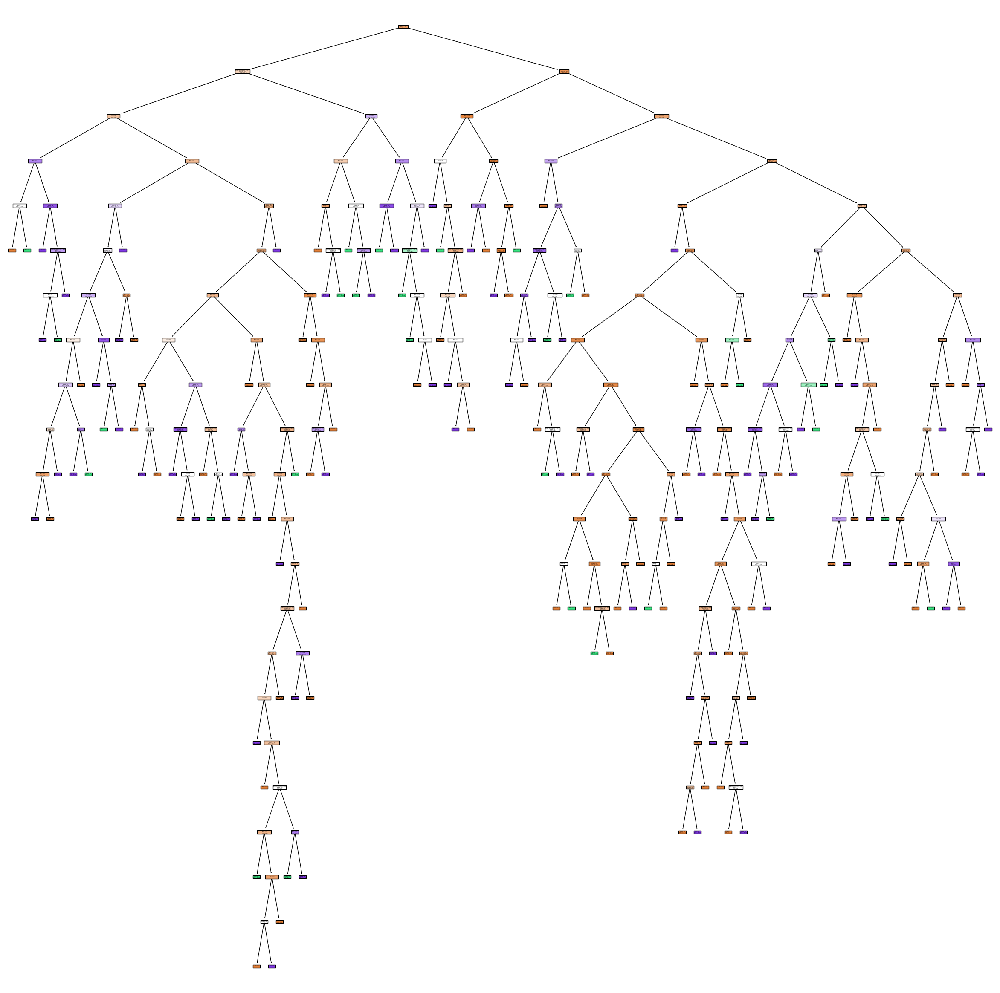

L'arbre de décision a été sauvegardé avec succès.


In [271]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
import numpy as np

# Charger le dataset
data = pd.read_csv('filtered_dataset.csv', low_memory=False)

# Utiliser seulement une fraction des données aléatoirement
dt = data.sample(frac=0.07, random_state=0).reset_index(drop=True)

# Identifier les colonnes numériques
numerical_columns = dt.select_dtypes(include=['number']).columns

# Séparer les caractéristiques et la cible
X = dt[numerical_columns].drop(columns=['Thermal comfort'], errors='ignore')  # Supposons 'Thermal comfort' comme cible
y = dt['Thermal comfort']  # Cible

# Remplacer les NaN par la moyenne pour chaque colonne
X.fillna(X.mean(), inplace=True)

# Remplacer les NaN dans la cible par la moyenne
if y.isna().any():
    y.fillna(y.mean(), inplace=True)

# Convertir la cible en classes discrètes (par exemple, 3 classes basées sur des intervalles)
y = pd.cut(y, bins=3, labels=['Low', 'Medium', 'High'])

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Créer et entraîner un modèle d'arbre de décision
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Faire des prédictions et évaluer le modèle
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')
print(classification_report(y_test, y_pred))

# Calculer la matrice de confusion
cm1 = confusion_matrix(y_test, y_pred)
print(cm1)

# Calculer la sensibilité et la spécificité
total1 = np.sum(cm1)
accuracy1 = (cm1[0, 0] + cm1[1, 1]) / total1
print('Accuracy : ', accuracy1)

sensitivity1 = cm1[0, 0] / (cm1[0, 0] + cm1[0, 1])
print('Sensitivity : ', sensitivity1)

specificity1 = cm1[1, 1] / (cm1[1, 0] + cm1[1, 1])
print('Specificity : ', specificity1)

# Visualiser l'arbre de décision
plt.figure(figsize=(30, 30))

# Sauvegarder l'arbre sous forme d'image avant de l'afficher
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True)

# Sauvegarder l'image dans un fichier PNG (ajoutez un chemin absolu si nécessaire)
plt.savefig('decision_tree.png', bbox_inches='tight')  # bbox_inches='tight' permet de ne pas laisser d'espace inutile autour

# Afficher l'arbre de décision
plt.show()

# Fermer la figure pour libérer la mémoire
plt.close()

# Confirmer que l'image a bien été sauvegardée
import os
if os.path.exists('decision_tree.png'):
    print("L'arbre de décision a été sauvegardé avec succès.")
else:
    print("Erreur de sauvegarde de l'arbre de décision.")

### Correlation des feature_INDIA

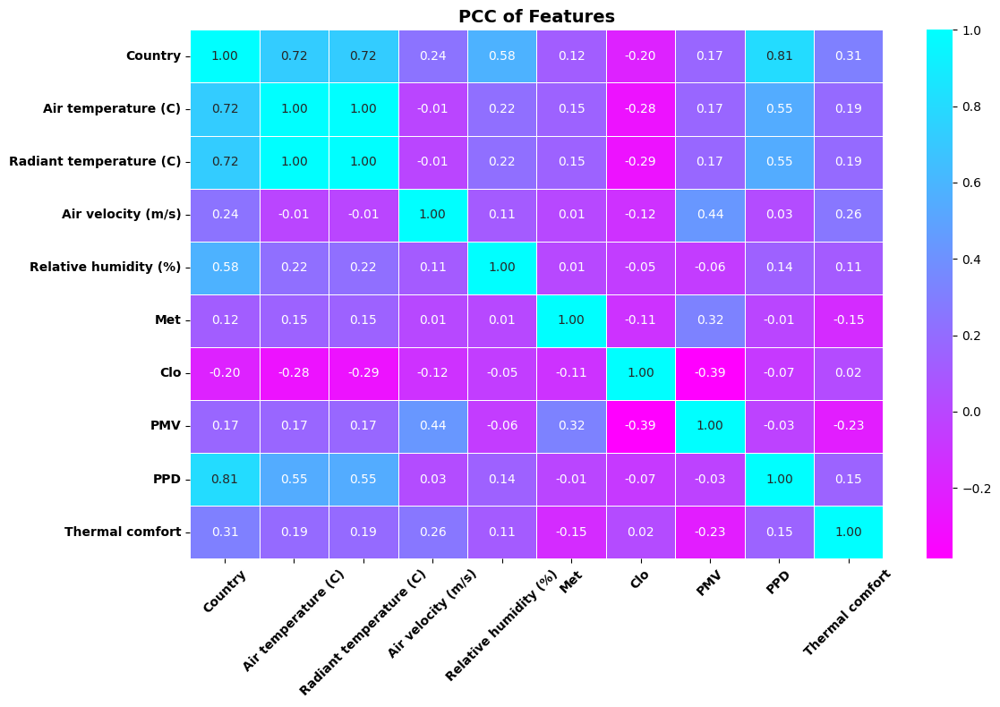

Corrélations avec PMV :
PMV                        1.000000
Air velocity (m/s)         0.435235
Met                        0.323465
Radiant temperature (C)    0.172459
Air temperature (C)        0.172046
Country                    0.170552
PPD                       -0.026007
Relative humidity (%)     -0.057399
Thermal comfort           -0.227931
Clo                       -0.385039
Name: PMV, dtype: float64
La visualisation de la corrélation des caractéristiques a été sauvegardée avec succès.


In [274]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Charger les données
data = pd.read_csv('filtered_dataset.csv')

# Vérifier que la colonne PMV existe
target_column = 'PMV'  # Nom de la colonne pour le PMV
if target_column not in data.columns:
    raise ValueError(f"La colonne cible '{target_column}' n'existe pas dans le dataset.")

# Convertir toutes les colonnes en numériques (au cas où certaines seraient en texte)
data = data.apply(pd.to_numeric, errors='coerce')

# Remplacer les NaN dans chaque ligne par la moyenne de cette ligne
data = data.apply(lambda row: row.fillna(row.mean()), axis=1)

# Calculer la matrice de corrélation de Pearson
correlation_matrix = data.corr(method='pearson')

# Visualiser la matrice de corrélation avec une heatmap
plt.figure(figsize=(12, 8))
heatmap = sns.heatmap(
    correlation_matrix, annot=True, cmap='cool_r', fmt='.2f', linewidths=0.5
)

# Appliquer le texte en gras et une rotation de 45° aux labels des axes
heatmap.set_xticklabels(heatmap.get_xticklabels(), fontsize=10, fontweight='bold', rotation=45)
heatmap.set_yticklabels(heatmap.get_yticklabels(), fontsize=10, fontweight='bold', rotation=0)

plt.title("PCC of Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Correlation_des_features_INDIA.png', dpi=300)  # Sauvegarder l'image
plt.show()

# Afficher les corrélations spécifiques avec PMV
pmv_correlations = correlation_matrix[target_column]
print("Corrélations avec PMV :")
print(pmv_correlations.sort_values(ascending=False))

# Vérifier que l'image a bien été sauvegardée
if os.path.exists('Correlation_des_features_INDIA.png'):
    print("La visualisation de la corrélation des caractéristiques a été sauvegardée avec succès.")
else:
    print("Erreur lors de la sauvegarde de la visualisation de la corrélation.")

### COLORMAPS 

In [277]:
from matplotlib import colormaps
list(colormaps)

['magma',
 'inferno',
 'plasma',
 'viridis',
 'cividis',
 'twilight',
 'twilight_shifted',
 'turbo',
 'Blues',
 'BrBG',
 'BuGn',
 'BuPu',
 'CMRmap',
 'GnBu',
 'Greens',
 'Greys',
 'OrRd',
 'Oranges',
 'PRGn',
 'PiYG',
 'PuBu',
 'PuBuGn',
 'PuOr',
 'PuRd',
 'Purples',
 'RdBu',
 'RdGy',
 'RdPu',
 'RdYlBu',
 'RdYlGn',
 'Reds',
 'Spectral',
 'Wistia',
 'YlGn',
 'YlGnBu',
 'YlOrBr',
 'YlOrRd',
 'afmhot',
 'autumn',
 'binary',
 'bone',
 'brg',
 'bwr',
 'cool',
 'coolwarm',
 'copper',
 'cubehelix',
 'flag',
 'gist_earth',
 'gist_gray',
 'gist_heat',
 'gist_ncar',
 'gist_rainbow',
 'gist_stern',
 'gist_yarg',
 'gnuplot',
 'gnuplot2',
 'gray',
 'hot',
 'hsv',
 'jet',
 'nipy_spectral',
 'ocean',
 'pink',
 'prism',
 'rainbow',
 'seismic',
 'spring',
 'summer',
 'terrain',
 'winter',
 'Accent',
 'Dark2',
 'Paired',
 'Pastel1',
 'Pastel2',
 'Set1',
 'Set2',
 'Set3',
 'tab10',
 'tab20',
 'tab20b',
 'tab20c',
 'grey',
 'gist_grey',
 'gist_yerg',
 'Grays',
 'magma_r',
 'inferno_r',
 'plasma_r',
 'viri

### BOX PLOT

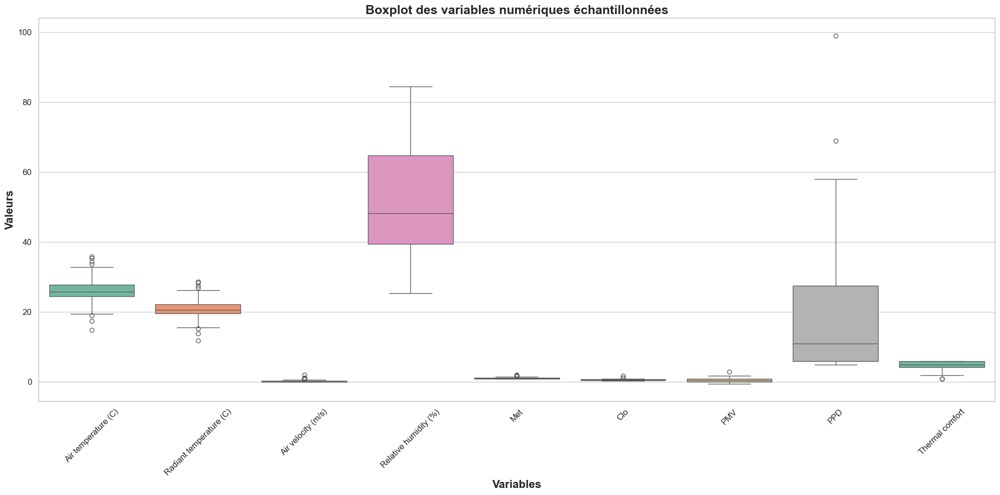

In [279]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configuration du style seaborn
sns.set(style="whitegrid")

# Chargement du dataset
data = pd.read_csv('filtered_dataset.csv')

# Échantillonnage aléatoire pour une visualisation rapide
sampled_data = data.sample(frac=0.005, random_state=42)

# Sélection des colonnes numériques uniquement
numeric_data = sampled_data.select_dtypes(include=['float64', 'int64'])

# Création du boxplot
plt.figure(figsize=(20, 10))
sns.boxplot(data=numeric_data, palette='Set2')

# Titre et axes
plt.title("Boxplot des variables numériques échantillonnées", fontsize=18, fontweight='bold')
plt.xlabel("Variables", fontsize=16, fontweight='bold')
plt.ylabel("Valeurs", fontsize=16, fontweight='bold')
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)

# Sauvegarde de l'image
plt.tight_layout()
plt.savefig('Boxplot_filtered_dataset_INDIA.png', dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

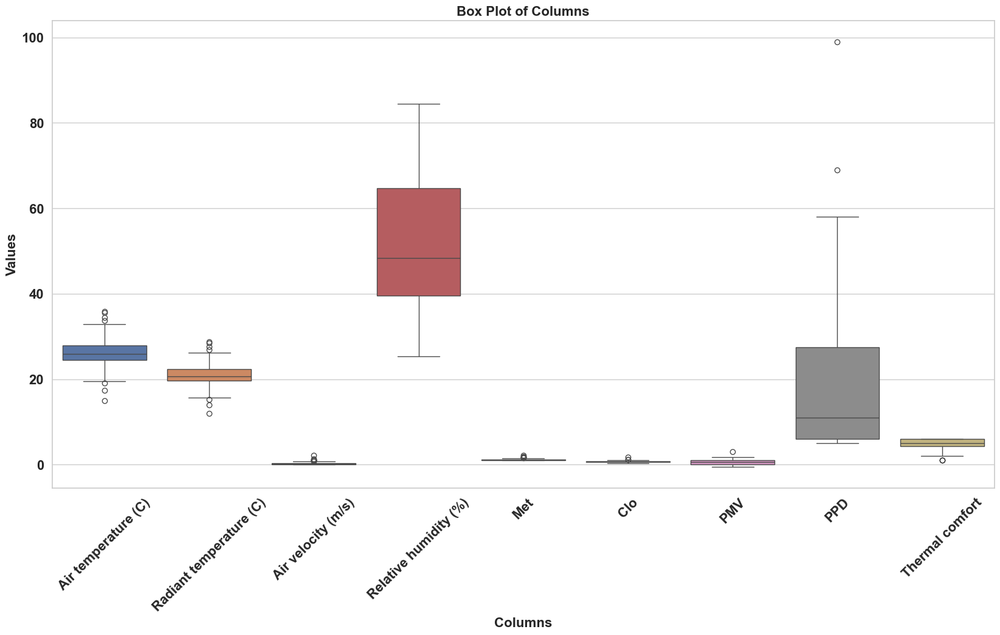

In [284]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Configuration Seaborn
sns.set(style="whitegrid")

# Charger les données
data = pd.read_csv('filtered_dataset.csv')

# Prendre un échantillon réduit
sampled_data = data.sample(frac=0.005, random_state=42)

# Créer un boxplot pour chaque colonne numérique
plt.figure(figsize=(20, 10))
sns.boxplot(data=sampled_data)  # Correction ici

# Ajouter un titre et des étiquettes
plt.title("Box Plot of Columns", fontsize=16, fontweight='bold')
plt.xlabel("Columns", fontsize=16, fontweight='bold')
plt.ylabel("Values", fontsize=16, fontweight='bold')

# Appliquer le gras aux valeurs des axes
plt.xticks(fontsize=16, fontweight='bold', rotation=45)  # Rotation pour améliorer la lisibilité
plt.yticks(fontsize=16, fontweight='bold')

# Sauvegarder l'image
plt.savefig('Box_Plot_filtered_data_INDIA.png', bbox_inches='tight', dpi=300)

# Afficher le graphique
plt.show()


In [286]:
#https://matplotlib.org/3.1.1/gallery/color/colormap_reference.html
import numpy as np
cm1 = confusion_matrix(y_test, y_pred) #confusion matrix
print(cm1)
def plot_confusion_matrix(cm,
                          target_names,
                          title='Confusion matrix',
                          cmap=None,
                          normalize=True):
    """
    given a sklearn confusion matrix (cm), make a nice plot

    Arguments
    ---------
    cm:           confusion matrix from sklearn.metrics.confusion_matrix

    target_names: given classification classes such as [0, 1, 2]
                  the class names, for example: ['high', 'low', 'medium']

    title:        the text to display at the top of the matrix

    cmap:         the gradient of the values displayed from matplotlib.pyplot.cm
                  see http://matplotlib.org/examples/color/colormaps_reference.html
                  plt.get_cmap('jet') or plt.cm.Blues

    normalize:    If False, plot the raw numbers
                  If True, plot the proportions

    Usage
    -----
    plot_confusion_matrix(cm           = cm,                  # confusion matrix created by
                                                              # sklearn.metrics.confusion_matrix
                          normalize    = True,                # show proportions
                          target_names = y_labels_vals,       # list of names of the classes
                          title        = best_estimator_name) # title of graph

    Citiation
    ---------
    http://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html

    """
    import matplotlib.pyplot as plt
    import numpy as np
    import itertools

    accuracy = np.trace(cm) / np.sum(cm).astype('float')
    misclass = 1 - accuracy

    if cmap is None:
        cmap = plt.get_cmap('TSV') ##https://matplotlib.org/3.1.1/gallery/color/colormap_reference.html

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    if target_names is not None:
        tick_marks = np.arange(len(target_names))
        plt.xticks(tick_marks, target_names, rotation=45)
        plt.yticks(tick_marks, target_names)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


    thresh = cm.max() / 1.5 if normalize else cm.max() / 2
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if normalize:
            plt.text(j, i, "{:0.4f}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")
        else:
            plt.text(j, i, "{:,}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")


    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label\naccuracy={:0.4f}; misclass={:0.4f}'.format(accuracy, misclass))
    plt.show()

[[158   4  21]
 [  6   1   4]
 [ 12   7  13]]


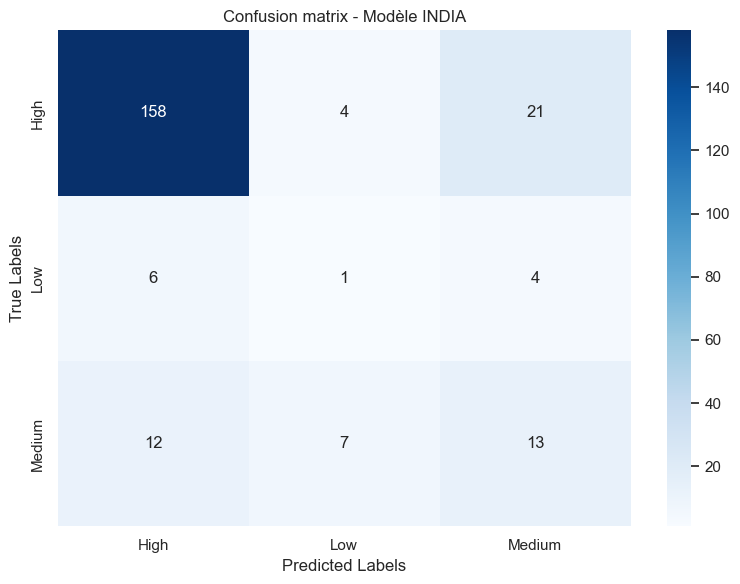

In [288]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

def plot_confusion_matrix(cm, labels, title='Confusion Matrix', cmap='Blues', normalize=False):
    """
    Affiche une matrice de confusion avec options de normalisation.

    Args:
        cm (array): Matrice de confusion.
        labels (list): Liste des étiquettes pour les classes.
        title (str): Titre de la matrice.
        cmap (str): Palette de couleurs.
        normalize (bool): Si True, affiche les pourcentages au lieu des valeurs brutes.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd', cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.tight_layout()
    plt.show()

# Exemple d'utilisation
labels = ["High", "Low", "Medium"]  # Classes de la cible
plot_confusion_matrix(cm1, labels, title="Confusion matrix - Modèle INDIA")

# Définir le chemin de sauvegarde
output_dir = "confusion_matrix_outputs"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "Confusion matrix- Modèle INDIA.png")
plt.show()

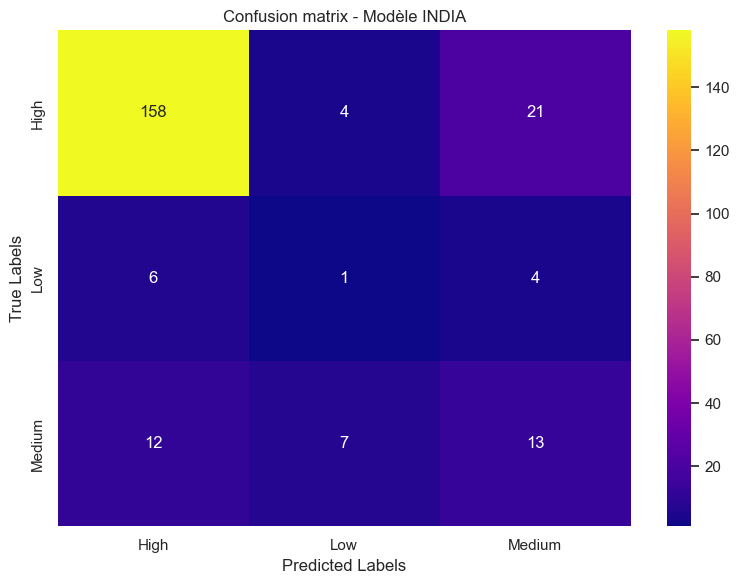

In [290]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os  # Import manquant pour la gestion des chemins

def plot_confusion_matrix(cm, labels, title='Confusion Matrix', cmap='plasma', normalize=False, save_path=None):
    """
    Affiche une matrice de confusion avec options de normalisation et sauvegarde.

    Args:
        cm (array): Matrice de confusion.
        labels (list): Liste des étiquettes pour les classes.
        title (str): Titre de la matrice.
        cmap (str): Palette de couleurs.
        normalize (bool): Si True, affiche les pourcentages au lieu des valeurs brutes.
        save_path (str): Chemin pour sauvegarder la figure (optionnel).
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd', cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.tight_layout()
    
    # Sauvegarder si un chemin est fourni
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

# Exemple d'utilisation
labels = ["High", "Low", "Medium"]  # Classes de la cible


# Définir le chemin de sauvegarde
output_dir = "confusion_matrix_outputs"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "Confusion matrix_Modele_INDIA.png")

# Appel de la fonction
plot_confusion_matrix(cm1, labels, title="Confusion matrix - Modèle INDIA", save_path=save_path)


### Comparison_diagram_of_clustering_results_INDIA

Colonnes disponibles : Index(['Country', 'Air temperature (C)', 'Radiant temperature (C)',
       'Air velocity (m/s)', 'Relative humidity (%)', 'Met', 'Clo', 'PMV',
       'PPD', 'Thermal comfort'],
      dtype='object')
Silhouette score : 0.337


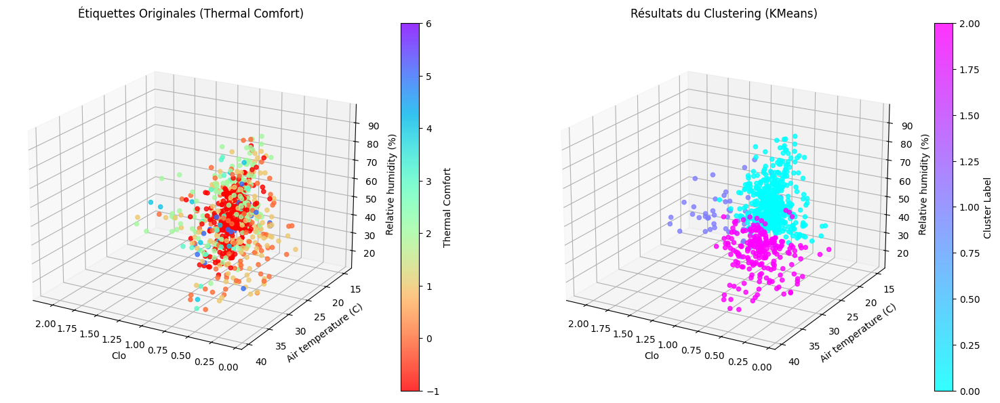

In [70]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score


# 📦 Chargement du dataset
try:
    filtered_dataset = pd.read_csv('filtered_dataset.csv')  # Remplacer par votre chemin
except FileNotFoundError:
    raise FileNotFoundError("Le fichier 'filtered_dataset.csv' est introuvable.")

# ✅ Vérification des colonnes requises
required_columns = ['Clo', 'Relative humidity (%)', 'Air temperature (C)', 'Thermal comfort']
missing_columns = [col for col in required_columns if col not in filtered_dataset.columns]
if missing_columns:
    raise ValueError(f"Colonnes manquantes : {missing_columns}")

print("Colonnes disponibles :", filtered_dataset.columns)

# 🔄 Échantillonnage aléatoire
dt = filtered_dataset.sample(frac=0.05, random_state=0).reset_index(drop=True)

# 🧼 Prétraitement : imputation + standardisation
def preprocess_data(df, cols):
    imputer = SimpleImputer(strategy='mean')
    scaler = StandardScaler()
    imputed = imputer.fit_transform(df[cols])
    scaled = scaler.fit_transform(imputed)
    return scaled

# ⚙️ Clustering avec KMeans
def apply_kmeans(data, n_clusters=3):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init=100)
    return kmeans.fit_predict(data)

# 📊 Évaluation par silhouette score
def evaluate_clustering(data, labels):
    score = silhouette_score(data, labels)
    print(f"Silhouette score : {score:.3f}")

# 🧪 Colonnes utilisées
x_col = 'Clo'
y_col = 'Air temperature (C)'
z_col = 'Relative humidity (%)'
label_col = 'Thermal comfort'

# 🔁 Traitement complet
features = [x_col, y_col, z_col]
scaled_data = preprocess_data(dt, features)
cluster_labels = apply_kmeans(scaled_data, n_clusters=3)
dt['Cluster_Label'] = cluster_labels
evaluate_clustering(scaled_data, cluster_labels)

# 🎨 Visualisation 3D
fig = plt.figure(figsize=(16, 6))

# 🔹 Graphe 1 : Étiquettes originales
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(
    dt[x_col], dt[y_col], dt[z_col],
    c=pd.factorize(dt[label_col])[0], cmap='rainbow_r',
    s=20, alpha=0.8
)
ax1.set_title('Étiquettes Originales (Thermal Comfort)', fontsize=12)
ax1.set_xlabel(x_col)
ax1.set_ylabel(y_col)
ax1.set_zlabel(z_col)
ax1.view_init(elev=20, azim=120)
fig.colorbar(scatter1, ax=ax1, label='Thermal Comfort')

# 🔸 Graphe 2 : Résultats du clustering
ax2 = fig.add_subplot(122, projection='3d')
scatter2 = ax2.scatter(
    dt[x_col], dt[y_col], dt[z_col],
    c=dt['Cluster_Label'], cmap='cool',
    s=20, alpha=0.8
)
ax2.set_title('Résultats du Clustering (KMeans)', fontsize=12)
ax2.set_xlabel(x_col)
ax2.set_ylabel(y_col)
ax2.set_zlabel(z_col)
ax2.view_init(elev=20, azim=120)
fig.colorbar(scatter2, ax=ax2, label='Cluster Label')

plt.tight_layout()

# 💾 Sauvegarde des figures
output_dir = "Comparison_diagram_outputs"
os.makedirs(output_dir, exist_ok=True)
save_path_png = os.path.join(output_dir, "Comparison_diagram_of_clustering_results_INDIA.png")
save_path_pdf = os.path.join(output_dir, "Comparison_diagram_of_clustering_results_INDIA.pdf")

plt.savefig(save_path_png, dpi=300, bbox_inches='tight')
plt.savefig(save_path_pdf, bbox_inches='tight')

# 👀 Affichage
plt.show()

Colonnes disponibles : Index(['Country', 'Air temperature (C)', 'Radiant temperature (C)',
       'Air velocity (m/s)', 'Relative humidity (%)', 'Met', 'Clo', 'PMV',
       'PPD', 'Thermal comfort'],
      dtype='object')


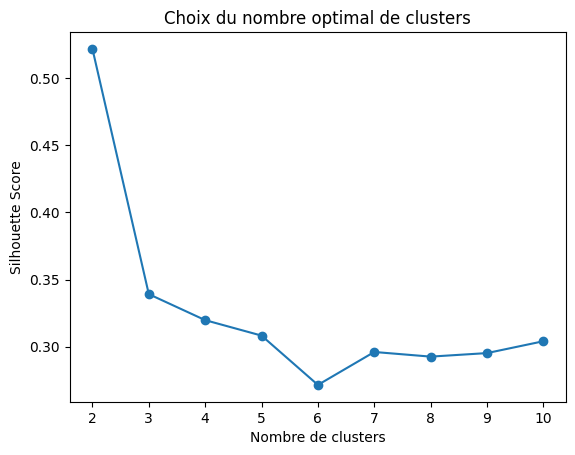

Meilleur nombre de clusters selon silhouette : 2
Silhouette score : 0.522
Calinski-Harabasz score : 187.704 (plus grand est mieux)
Davies-Bouldin score : 0.802 (plus petit est mieux)


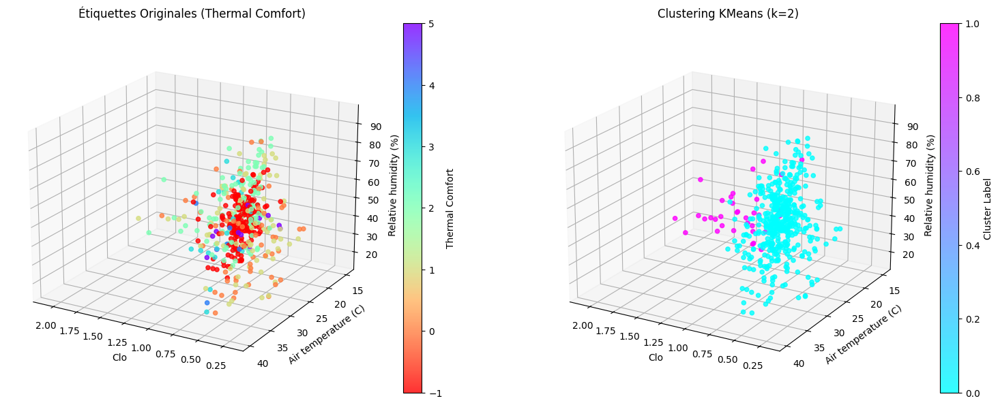

In [72]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA


# 📦 Chargement du dataset
try:
    filtered_dataset = pd.read_csv('filtered_dataset.csv')  # Remplacer par votre chemin
except FileNotFoundError:
    raise FileNotFoundError("Le fichier 'filtered_dataset.csv' est introuvable.")

# ✅ Vérification des colonnes requises
required_columns = ['Clo', 'Relative humidity (%)', 'Air temperature (C)', 'Thermal comfort']
missing_columns = [col for col in required_columns if col not in filtered_dataset.columns]
if missing_columns:
    raise ValueError(f"Colonnes manquantes : {missing_columns}")

print("Colonnes disponibles :", filtered_dataset.columns)

# 🔄 Échantillonnage aléatoire
dt = filtered_dataset.sample(frac=0.03, random_state=0).reset_index(drop=True)

# 🧼 Prétraitement : imputation + standardisation + (optionnel) PCA
def preprocess_data(df, cols, use_pca=False, n_components=2):
    imputer = SimpleImputer(strategy='median')  # plus robuste que 'mean'
    scaler = StandardScaler()
    imputed = imputer.fit_transform(df[cols])
    scaled = scaler.fit_transform(imputed)
    
    if use_pca:
        pca = PCA(n_components=n_components)
        reduced = pca.fit_transform(scaled)
        print(f"Variance expliquée par {n_components} composantes PCA : {sum(pca.explained_variance_ratio_):.2f}")
        return reduced
    else:
        return scaled

# ⚙️ Clustering avec KMeans (avec paramètres améliorés)
def apply_kmeans(data, n_clusters=3):
    kmeans = KMeans(
        n_clusters=n_clusters, 
        random_state=0, 
        n_init=100, 
        algorithm='elkan', 
        tol=1e-4
    )
    return kmeans.fit_predict(data)

# 📊 Évaluation multiple du clustering
def evaluate_clustering(data, labels):
    silhouette = silhouette_score(data, labels)
    ch_score = calinski_harabasz_score(data, labels)
    db_score = davies_bouldin_score(data, labels)
    print(f"Silhouette score : {silhouette:.3f}")
    print(f"Calinski-Harabasz score : {ch_score:.3f} (plus grand est mieux)")
    print(f"Davies-Bouldin score : {db_score:.3f} (plus petit est mieux)")

# 🔍 Trouver le meilleur nombre de clusters (k) via silhouette score
def find_best_k(data, max_k=10):
    silhouettes = []
    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, algorithm='elkan', tol=1e-4)
        labels = kmeans.fit_predict(data)
        score = silhouette_score(data, labels)
        silhouettes.append(score)
    plt.plot(range(2, max_k + 1), silhouettes, marker='o')
    plt.xlabel('Nombre de clusters')
    plt.ylabel('Silhouette Score')
    plt.title('Choix du nombre optimal de clusters')
    plt.show()
    best_k = silhouettes.index(max(silhouettes)) + 2
    print(f"Meilleur nombre de clusters selon silhouette : {best_k}")
    return best_k

# 🧪 Colonnes utilisées
x_col = 'Clo'
y_col = 'Air temperature (C)'
z_col = 'Relative humidity (%)'
label_col = 'Thermal comfort'

# 🔁 Traitement complet
features = [x_col, y_col, z_col]
scaled_data = preprocess_data(dt, features, use_pca=False)  # Passe True pour activer PCA

# Trouver meilleur k automatiquement
best_k = find_best_k(scaled_data, max_k=10)

# Appliquer KMeans avec le meilleur k trouvé
cluster_labels = apply_kmeans(scaled_data, n_clusters=best_k)
dt['Cluster_Label'] = cluster_labels

# Évaluation multiple
evaluate_clustering(scaled_data, cluster_labels)

# 🎨 Visualisation 3D
fig = plt.figure(figsize=(16, 6))

# 🔹 Graphe 1 : Étiquettes originales
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(
    dt[x_col], dt[y_col], dt[z_col],
    c=pd.factorize(dt[label_col])[0], cmap='rainbow_r',
    s=20, alpha=0.8
)
ax1.set_title('Étiquettes Originales (Thermal Comfort)', fontsize=12)
ax1.set_xlabel(x_col)
ax1.set_ylabel(y_col)
ax1.set_zlabel(z_col)
ax1.view_init(elev=20, azim=120)
fig.colorbar(scatter1, ax=ax1, label='Thermal Comfort')

# 🔸 Graphe 2 : Résultats du clustering
ax2 = fig.add_subplot(122, projection='3d')
scatter2 = ax2.scatter(
    dt[x_col], dt[y_col], dt[z_col],
    c=dt['Cluster_Label'], cmap='cool',
    s=20, alpha=0.8
)
ax2.set_title(f'Clustering KMeans (k={best_k})', fontsize=12)
ax2.set_xlabel(x_col)
ax2.set_ylabel(y_col)
ax2.set_zlabel(z_col)
ax2.view_init(elev=20, azim=120)
fig.colorbar(scatter2, ax=ax2, label='Cluster Label')

plt.tight_layout()

# 💾 Sauvegarde des figures
output_dir = "Comparison_diagram_outputs"
os.makedirs(output_dir, exist_ok=True)
save_path_png = os.path.join(output_dir, f"Comparison_diagram_of_clustering_results_INDIA_k{best_k}.png")
save_path_pdf = os.path.join(output_dir, f"Comparison_diagram_of_clustering_results_INDIA_k{best_k}.pdf")

plt.savefig(save_path_png, dpi=300, bbox_inches='tight')
plt.savefig(save_path_pdf, bbox_inches='tight')

# 👀 Affichage
plt.show()

Colonnes disponibles : Index(['Country', 'Air temperature (C)', 'Radiant temperature (C)',
       'Air velocity (m/s)', 'Relative humidity (%)', 'Met', 'Clo', 'PMV',
       'PPD', 'Thermal comfort'],
      dtype='object')
Variance expliquée par 2 composantes PCA : 0.84
Silhouette score : 0.556
Calinski-Harabasz score : 235.013 (plus grand est mieux)
Davies-Bouldin score : 0.728 (plus petit est mieux)


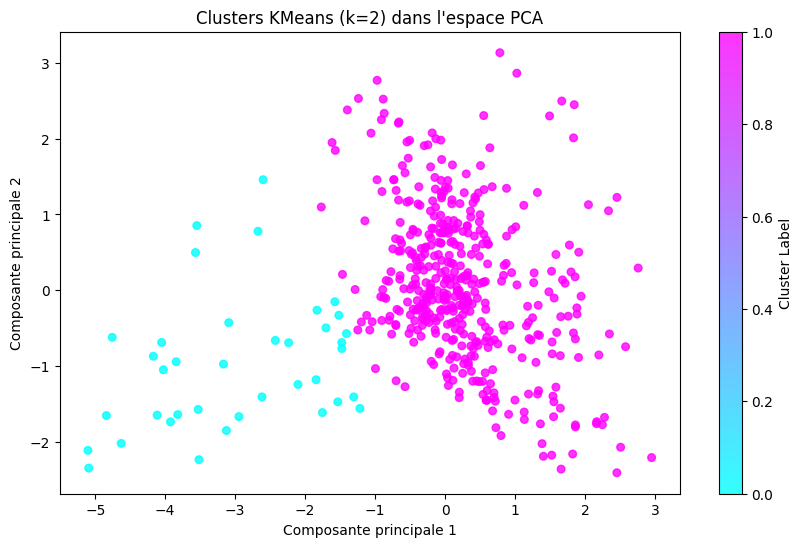

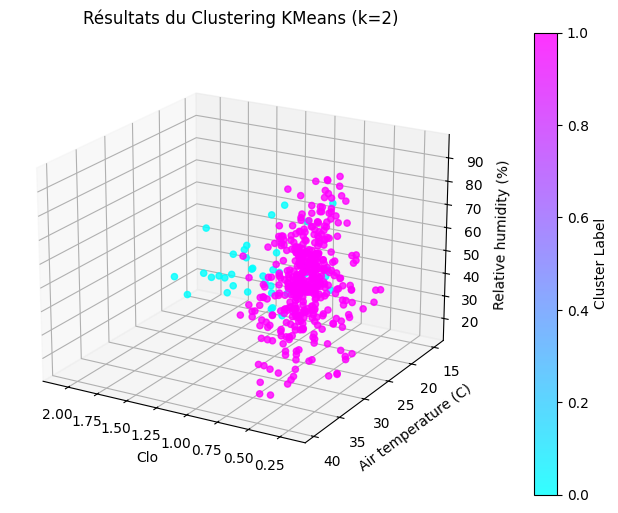

In [74]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA

# 📦 Chargement du dataset
try:
    filtered_dataset = pd.read_csv('filtered_dataset.csv')  # Remplacer par votre chemin
except FileNotFoundError:
    raise FileNotFoundError("Le fichier 'filtered_dataset.csv' est introuvable.")

# ✅ Vérification des colonnes requises
required_columns = ['Clo', 'Relative humidity (%)', 'Air temperature (C)', 'Thermal comfort']
missing_columns = [col for col in required_columns if col not in filtered_dataset.columns]
if missing_columns:
    raise ValueError(f"Colonnes manquantes : {missing_columns}")

print("Colonnes disponibles :", filtered_dataset.columns)

# 🔄 Échantillonnage aléatoire
dt = filtered_dataset.sample(frac=0.03, random_state=0).reset_index(drop=True)

# 🧼 Prétraitement : imputation + standardisation + PCA (activation)
def preprocess_data(df, cols, use_pca=True, n_components=2):
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()
    imputed = imputer.fit_transform(df[cols])
    scaled = scaler.fit_transform(imputed)
    
    if use_pca:
        pca = PCA(n_components=n_components)
        reduced = pca.fit_transform(scaled)
        print(f"Variance expliquée par {n_components} composantes PCA : {sum(pca.explained_variance_ratio_):.2f}")
        return reduced
    else:
        return scaled

# ⚙️ Clustering KMeans avec n_clusters=2
def apply_kmeans(data, n_clusters=2):
    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=0,
        n_init=200,
        algorithm='elkan',
        tol=1e-4
    )
    return kmeans.fit_predict(data)

# 📊 Évaluation multiple
def evaluate_clustering(data, labels):
    silhouette = silhouette_score(data, labels)
    ch_score = calinski_harabasz_score(data, labels)
    db_score = davies_bouldin_score(data, labels)
    print(f"Silhouette score : {silhouette:.3f}")
    print(f"Calinski-Harabasz score : {ch_score:.3f} (plus grand est mieux)")
    print(f"Davies-Bouldin score : {db_score:.3f} (plus petit est mieux)")

# Colonnes utilisées
x_col = 'Clo'
y_col = 'Air temperature (C)'
z_col = 'Relative humidity (%)'
label_col = 'Thermal comfort'

features = [x_col, y_col, z_col]
processed_data = preprocess_data(dt, features, use_pca=True, n_components=2)

cluster_labels = apply_kmeans(processed_data, n_clusters=2)
dt['Cluster_Label'] = cluster_labels

evaluate_clustering(processed_data, cluster_labels)

# Visualisation 2D PCA
plt.figure(figsize=(10,6))
scatter = plt.scatter(processed_data[:,0], processed_data[:,1], c=cluster_labels, cmap='cool', s=30, alpha=0.8)
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.title('Clusters KMeans (k=2) dans l\'espace PCA')
plt.colorbar(scatter, label='Cluster Label')
plt.show()

# Visualisation 3D originale avec clusters (optionnel)
fig = plt.figure(figsize=(16, 6))
ax2 = fig.add_subplot(111, projection='3d')
scatter2 = ax2.scatter(
    dt[x_col], dt[y_col], dt[z_col],
    c=dt['Cluster_Label'], cmap='cool',
    s=20, alpha=0.8
)
ax2.set_title('Résultats du Clustering KMeans (k=2)', fontsize=12)
ax2.set_xlabel(x_col)
ax2.set_ylabel(y_col)
ax2.set_zlabel(z_col)
ax2.view_init(elev=20, azim=120)
fig.colorbar(scatter2, ax=ax2, label='Cluster Label')
plt.show()

=== Moyennes PMV / PPD par cluster ===
              PMV        PPD
Cluster                     
0.0      0.712008  23.668230
1.0      0.535517  26.588536
2.0      0.642027  23.463455


C:\Users\Rchid\AppData\Local\Temp\ipykernel_20004\1769649742.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dt, x='Cluster', y='PMV', palette='Set2')
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax

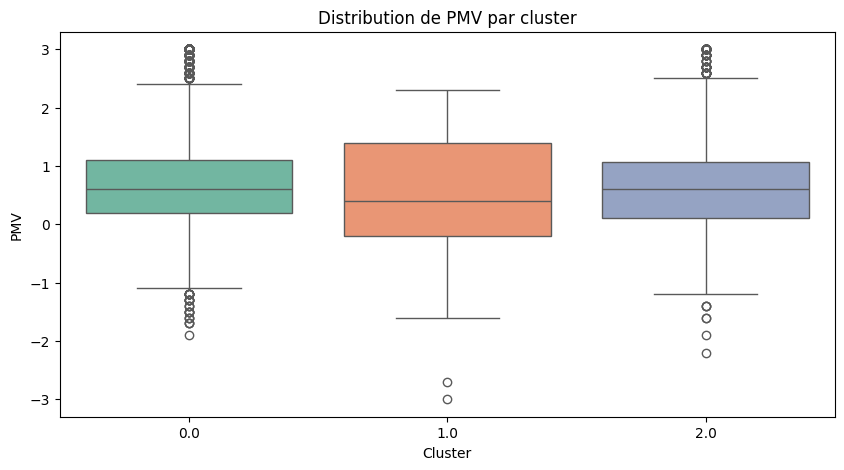

C:\Users\Rchid\AppData\Local\Temp\ipykernel_20004\1769649742.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dt, x='Cluster', y='PPD', palette='Set3')
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\Rchid\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax

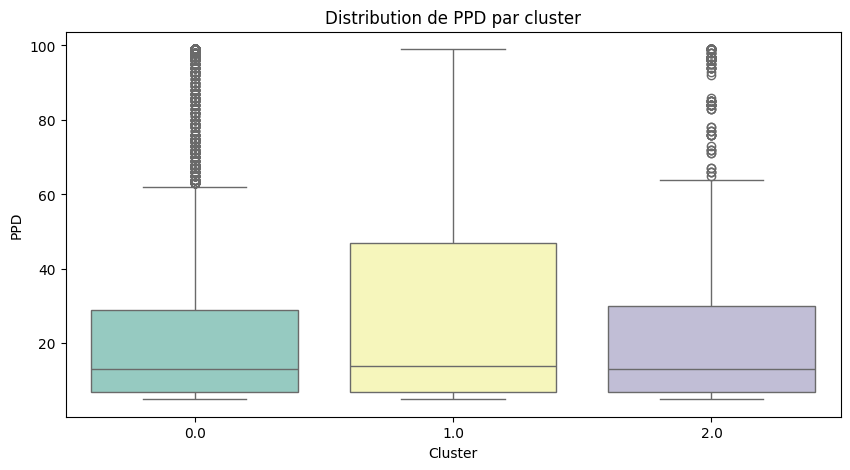

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering

# Charger les données
dt = pd.read_csv("filtered_dataset.csv")

# Colonnes utilisées pour clustering (ajuste selon tes données)
features = ['Air temperature (C)', 
            'Relative humidity (%)', 'Air velocity (m/s)']

# Vérifie que toutes les colonnes existent
missing = [col for col in features + ['PMV', 'PPD'] if col not in dt.columns]
if missing:
    raise ValueError(f"Colonnes manquantes dans le dataset : {missing}")

X = dt[features].dropna()

# Clustering hiérarchique (nombre de clusters = 3)
model = AgglomerativeClustering(n_clusters=3, linkage='average', metric='manhattan')
clusters = model.fit_predict(X)

# Ajouter les clusters dans le dataframe (en conservant l'index correct)
dt.loc[X.index, 'Cluster'] = clusters

# Moyenne PMV et PPD par cluster
cluster_summary = dt.groupby('Cluster')[['PMV', 'PPD']].mean()
print("=== Moyennes PMV / PPD par cluster ===")
print(cluster_summary)

# Visualiser la distribution de PMV par cluster
plt.figure(figsize=(10, 5))
sns.boxplot(data=dt, x='Cluster', y='PMV', palette='Set2')
plt.title("Distribution de PMV par cluster")
plt.show()

# Visualiser la distribution de PPD par cluster
plt.figure(figsize=(10, 5))
sns.boxplot(data=dt, x='Cluster', y='PPD', palette='Set3')
plt.title("Distribution de PPD par cluster")
plt.show()


### Détection de conditions anormales (froid excessif, Chaud excessif, humidité haute)

C:\Users\Rchid\AppData\Local\Temp\ipykernel_20004\1129834611.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=values, palette=['#3498db', '#e67e22', '#e74c3c', '#2ecc71'])


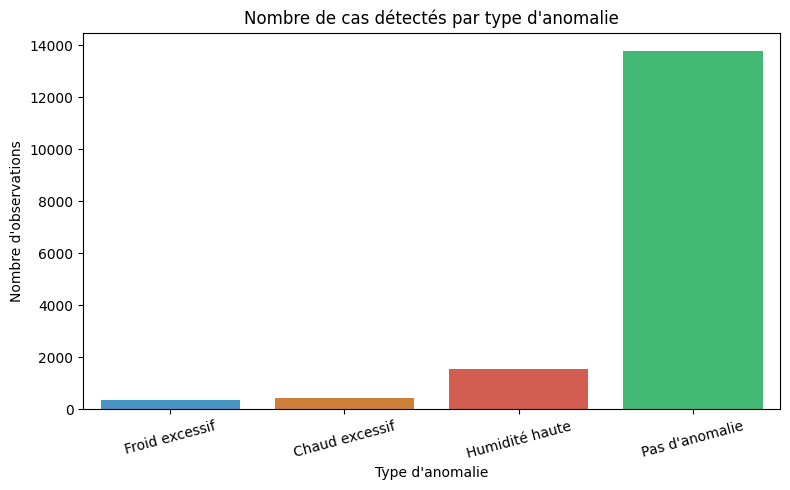

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données
dt = pd.read_csv("filtered_dataset.csv")

# Seuils à adapter selon besoin
TEMP_FROID_SEUIL = 18.0  # °C
TEMP_CHAUD_SEUIL = 35.0  # °C
HUMIDITE_HAUTE_SEUIL = 70.0  # %

# Détection des conditions anormales
dt['Froid_excessif'] = dt['Air temperature (C)'] < TEMP_FROID_SEUIL
dt['Chaud_excessif'] = dt['Air temperature (C)'] > TEMP_CHAUD_SEUIL
dt['Humidite_haute'] = dt['Relative humidity (%)'] > HUMIDITE_HAUTE_SEUIL

# Détection des lignes sans aucune anomalie
dt['Aucune_anomalie'] = ~(
    dt['Froid_excessif'] | dt['Chaud_excessif'] | dt['Humidite_haute']
)

# Compter le nombre d'anomalies par type
counts = {
    'Froid excessif': dt['Froid_excessif'].sum(),
    'Chaud excessif': dt['Chaud_excessif'].sum(),
    'Humidité haute': dt['Humidite_haute'].sum(),
    'Pas d\'anomalie': dt['Aucune_anomalie'].sum()
}

# Préparer les données pour le graphe
labels = list(counts.keys())
values = list(counts.values())

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=labels, y=values, palette=['#3498db', '#e67e22', '#e74c3c', '#2ecc71'])
plt.title("Nombre de cas détectés par type d'anomalie")
plt.ylabel("Nombre d'observations")
plt.xlabel("Type d'anomalie")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Relation Sheep entre PPD, Clo et PMV

In [300]:
# Ajouter une colonne 'Country' avec la valeur 'India'
dataset['Country'] = 'India'

# Filtrer et sélectionner les colonnes nécessaires
dataset_india = dataset[['Country', 'Thermal sensation', 'Air temperature (C)', 'Thermal preference', 'PMV']]
#dataset = dataset[['India', 'Thermal sensation', 'Air temperature (C)', 'Thermal preference','PMV']]
# Enregistrer le DataFrame filtré dans un fichier CSV
dataset.to_csv('data_TS_PMV_TC.csv', index=False)

print("Les colonnes sélectionnées ont été sauvegardées dans 'data_TS_PMV_TC_INDIA.csv'")

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\1005113381.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset['Country'] = 'India'


Les colonnes sélectionnées ont été sauvegardées dans 'data_TS_PMV_TC_INDIA.csv'


C:\Users\Rchid\AppData\Roaming\Python\Python312\site-packages\numpy\polynomial\polynomial.py:1362: RankWarning: The fit may be poorly conditioned
  return pu._fit(polyvander, x, y, deg, rcond, full, w)


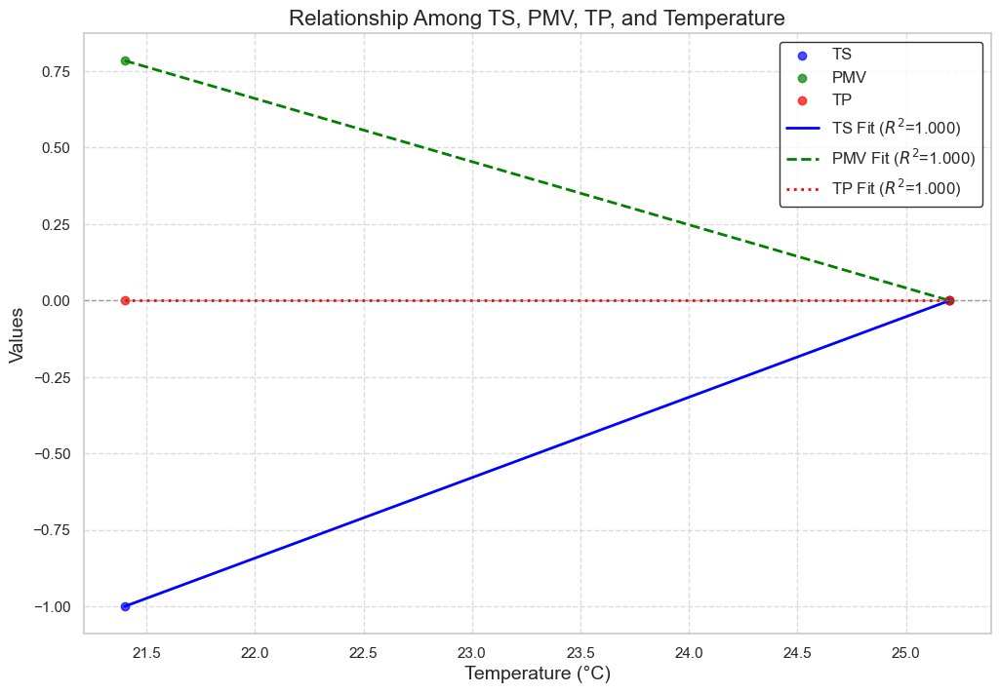

Figures saved successfully:
- plots\relation_sheep_INDIA.png
- plots\relation_sheep_INDIA.pdf


In [303]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from numpy.polynomial.polynomial import Polynomial

# === 1. Chargement des données ===
#file_path = "data_TS_PMV_TC.csv"
file_path = "data_TS_PMV_TC_INDIA.csv"
dt = pd.read_csv(file_path)
# Utiliser seulement une fraction des données aléatoirement
data = dt.sample(frac=0.005, random_state=0).reset_index(drop=True)

# Sélectionner uniquement les colonnes nécessaires
required_columns = ['Thermal preference', 'Thermal sensation', 'Air temperature (C)', 'PMV']
data = data[required_columns]

# Renommer les colonnes pour simplifier le code
data = data.rename(columns={
    'Thermal preference': 'TP',
    'Thermal sensation': 'TS',
    'Air temperature (C)': 'Ta',
    'PMV': 'PMV'
})

# Remplacer les valeurs dans la colonne TP
data['TP'] = data['TP'].replace({
    'warmer': 1,
    'no change': 0,
    'Cooler': -1
})

# Conversion explicite en numérique (ignorer les erreurs)
data['TP'] = pd.to_numeric(data['TP'], errors='coerce')
data['TS'] = pd.to_numeric(data['TS'], errors='coerce')
data['Ta'] = pd.to_numeric(data['Ta'], errors='coerce')
data['PMV'] = pd.to_numeric(data['PMV'], errors='coerce')

# Remplacer les NaN par la moyenne des colonnes pertinentes
data.fillna(data.mean(), inplace=True)

# Filtrer une fraction des données
data_sample = data.sample(frac=0.019, random_state=42)

# Extraire les colonnes pertinentes
temperature = data_sample['Ta']
ts = data_sample['TS']
pmv = data_sample['PMV']
tp = data_sample['TP']

# === 2. Ajustement des modèles ===
degree = 2

poly_ts = Polynomial.fit(temperature, ts, degree, rcond=1e-4)
poly_pmv = Polynomial.fit(temperature, pmv, degree, rcond=1e-4)
poly_tp = Polynomial.fit(temperature, tp, degree, rcond=1e-4)

# Générer les valeurs ajustées
temperature_sorted = np.sort(temperature)
ts_fit = poly_ts(temperature_sorted)
pmv_fit = poly_pmv(temperature_sorted)
tp_fit = poly_tp(temperature_sorted)

# Calculer R²
r2_ts = r2_score(ts, poly_ts(temperature))
r2_pmv = r2_score(pmv, poly_pmv(temperature))
r2_tp = r2_score(tp, poly_tp(temperature))

# === 3. Création des figures ===
fig, ax = plt.subplots(figsize=(12, 8))

# Points de données
ax.scatter(temperature, ts, label="TS", color="blue", alpha=0.7)
ax.scatter(temperature, pmv, label="PMV", color="green", alpha=0.7)
ax.scatter(temperature, tp, label="TP", color="red", alpha=0.7)

# Courbes ajustées
ax.plot(temperature_sorted, ts_fit, label=f"TS Fit ($R^2$={r2_ts:.3f})", color="blue", linewidth=2)
ax.plot(temperature_sorted, pmv_fit, label=f"PMV Fit ($R^2$={r2_pmv:.3f})", color="green", linewidth=2, linestyle='--')
ax.plot(temperature_sorted, tp_fit, label=f"TP Fit ($R^2$={r2_tp:.3f})", color="red", linewidth=2, linestyle=':')

# Configuration du graphique
ax.set_title("Relationship Among TS, PMV, TP, and Temperature", fontsize=16)
ax.set_xlabel("Temperature (°C)", fontsize=14)
ax.set_ylabel("Values", fontsize=14)
ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12, frameon=True, loc="upper right", edgecolor="black")

# Sauvegarde des figures avant affichage
output_dir = "plots"
os.makedirs(output_dir, exist_ok=True)
png_path = os.path.join(output_dir, "relation_sheep_INDIA.png")
pdf_path = os.path.join(output_dir, "relation_sheep_INDIA.pdf")
plt.savefig(png_path, dpi=300, bbox_inches='tight')
plt.savefig(pdf_path, bbox_inches='tight')

# Affichage
plt.show()

# Vérifier la sauvegarde
if os.path.exists(png_path) and os.path.exists(pdf_path):
    print(f"Figures saved successfully:\n- {png_path}\n- {pdf_path}")
else:
    print("Error: Figures were not saved correctly.")

C:\Users\Rchid\AppData\Roaming\Python\Python312\site-packages\numpy\polynomial\polynomial.py:1362: RankWarning: The fit may be poorly conditioned
  return pu._fit(polyvander, x, y, deg, rcond, full, w)


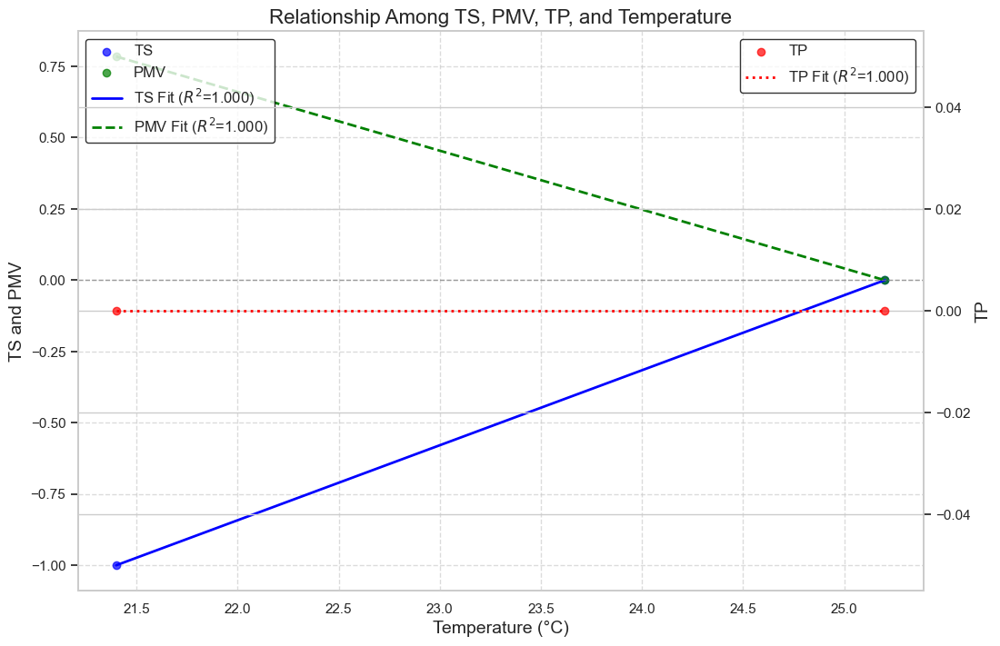

Figures saved successfully:
- plots\relation_sheep_INDIA.png
- plots\relation_sheep_INDIA.pdf


In [306]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from numpy.polynomial.polynomial import Polynomial

# === 1. Chargement des données ===
#file_path = "data_TS_PMV_TC.csv"
file_path = "data_TS_PMV_TC_INDIA.csv"
dt = pd.read_csv(file_path)
# Utiliser seulement une fraction des données aléatoirement
data = dt.sample(frac=0.005, random_state=0).reset_index(drop=True)

# Sélectionner uniquement les colonnes nécessaires
required_columns = ['Thermal preference', 'Thermal sensation', 'Air temperature (C)', 'PMV']
data = data[required_columns]

# Renommer les colonnes pour simplifier le code
data = data.rename(columns={
    'Thermal preference': 'TP',
    'Thermal sensation': 'TS',
    'Air temperature (C)': 'Ta',
    'PMV': 'PMV'
})

# Remplacer les valeurs dans la colonne TP
data['TP'] = data['TP'].replace({
    'warmer': 1,
    'no change': 0,
    'Cooler': -1
})

# Conversion explicite en numérique (ignorer les erreurs)
data['TP'] = pd.to_numeric(data['TP'], errors='coerce')
data['TS'] = pd.to_numeric(data['TS'], errors='coerce')
data['Ta'] = pd.to_numeric(data['Ta'], errors='coerce')
data['PMV'] = pd.to_numeric(data['PMV'], errors='coerce')

# Remplacer les NaN par la moyenne des colonnes pertinentes
data.fillna(data.mean(), inplace=True)

# Filtrer une fraction des données
data_sample = data.sample(frac=0.019, random_state=42)

# Extraire les colonnes pertinentes
temperature = data_sample['Ta']
ts = data_sample['TS']
pmv = data_sample['PMV']
tp = data_sample['TP']

# === 2. Ajustement des modèles ===
degree = 2

poly_ts = Polynomial.fit(temperature, ts, degree, rcond=1e-4)
poly_pmv = Polynomial.fit(temperature, pmv, degree, rcond=1e-4)
poly_tp = Polynomial.fit(temperature, tp, degree, rcond=1e-4)

# Générer les valeurs ajustées
temperature_sorted = np.sort(temperature)
ts_fit = poly_ts(temperature_sorted)
pmv_fit = poly_pmv(temperature_sorted)
tp_fit = poly_tp(temperature_sorted)

# Calculer R²
r2_ts = r2_score(ts, poly_ts(temperature))
r2_pmv = r2_score(pmv, poly_pmv(temperature))
r2_tp = r2_score(tp, poly_tp(temperature))

# === 3. Création des figures ===
fig, ax1 = plt.subplots(figsize=(12, 8))

# Points de données (TS et PMV)
ax1.scatter(temperature, ts, label="TS", color="blue", alpha=0.7)
ax1.scatter(temperature, pmv, label="PMV", color="green", alpha=0.7)

# Courbes ajustées (TS et PMV)
ax1.plot(temperature_sorted, ts_fit, label=f"TS Fit ($R^2$={r2_ts:.3f})", color="blue", linewidth=2)
ax1.plot(temperature_sorted, pmv_fit, label=f"PMV Fit ($R^2$={r2_pmv:.3f})", color="green", linewidth=2, linestyle='--')

# Création d'un second axe y pour TP
ax2 = ax1.twinx()
ax2.scatter(temperature, tp, label="TP", color="red", alpha=0.7)
ax2.plot(temperature_sorted, tp_fit, label=f"TP Fit ($R^2$={r2_tp:.3f})", color="red", linewidth=2, linestyle=':')

# Configuration du graphique
ax1.set_title("Relationship Among TS, PMV, TP, and Temperature", fontsize=16)
ax1.set_xlabel("Temperature (°C)", fontsize=14)
ax1.set_ylabel("TS and PMV", fontsize=14)
ax2.set_ylabel("TP", fontsize=14)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax1.grid(True, linestyle='--', alpha=0.7)

# Légende
ax1.legend(fontsize=12, frameon=True, loc="upper left", edgecolor="black")
ax2.legend(fontsize=12, frameon=True, loc="upper right", edgecolor="black")

# Sauvegarde des figures avant affichage
output_dir = "plots"
os.makedirs(output_dir, exist_ok=True)
png_path = os.path.join(output_dir, "relation_sheep_INDIA.png")
pdf_path = os.path.join(output_dir, "relation_sheep_INDIA.pdf")
plt.savefig(png_path, dpi=300, bbox_inches='tight')
plt.savefig(pdf_path, bbox_inches='tight')

# Affichage
plt.show()

# Vérifier la sauvegarde
if os.path.exists(png_path) and os.path.exists(pdf_path):
    print(f"Figures saved successfully:\n- {png_path}\n- {pdf_path}")
else:
    print("Error: Figures were not saved correctly.")

In [308]:
# Vérification des valeurs aberrantes
print(data.describe())


              TP         TS         Ta        PMV
count  81.000000  81.000000  81.000000  81.000000
mean    0.288889   0.049383  26.590000   0.784615
std     0.339935   1.243998   4.217481   0.778979
min     0.000000  -3.000000  14.700000  -0.900000
25%     0.000000  -1.000000  25.300000   0.300000
50%     0.288889   0.000000  26.600000   0.784615
75%     0.288889   1.000000  28.300000   1.000000
max     1.000000   3.000000  38.300000   3.000000


C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\1723591929.py:40: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['TP'] = data['TP'].replace({
C:\Users\Rchid\AppData\Roaming\Python\Python312\site-packages\numpy\polynomial\polynomial.py:1362: RankWarning: The fit may be poorly conditioned
  return pu._fit(polyvander, x, y, deg, rcond, full, w)


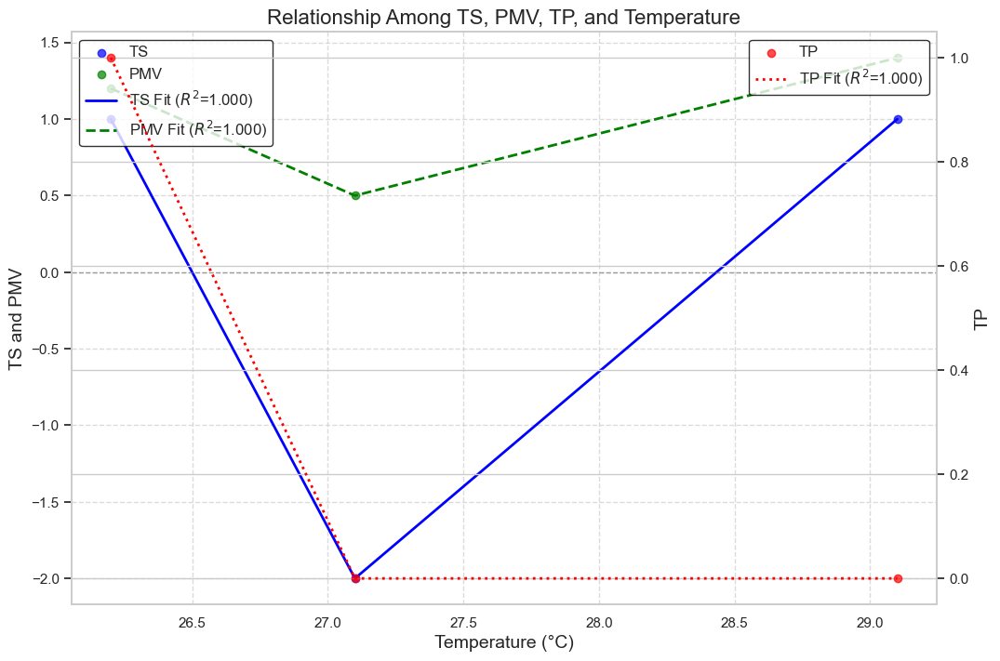

Figures saved successfully:
- plots\relation_sheep_INDIA_filtered.png
- plots\relation_sheep_INDIA_filtered.pdf
R² TS: 1.000
R² PMV: 1.000
R² TP: 1.000


In [310]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from numpy.polynomial.polynomial import Polynomial

# === 1. Chargement des données ===
file_path = "data_TS_PMV_TC_INDIA.csv"
dt = pd.read_csv(file_path)

# Utiliser une fraction plus importante des données (ajustable selon les besoins)
data = dt.sample(frac=0.002, random_state=0).reset_index(drop=True)

# Sélectionner uniquement les colonnes nécessaires
required_columns = ['Thermal preference', 'Thermal sensation', 'Air temperature (C)', 'PMV']
data = data[required_columns]

# Renommer les colonnes pour simplifier le code
data = data.rename(columns={
    'Thermal preference': 'TP',
    'Thermal sensation': 'TS',
    'Air temperature (C)': 'Ta',
    'PMV': 'PMV'
})

# === 2. Filtrage des valeurs non valides ===

# Eliminer les valeurs NaN dans les colonnes pertinentes
data = data.dropna(subset=['TP', 'TS', 'Ta', 'PMV'])

# Filtrer les valeurs aberrantes (par exemple, des températures trop élevées ou trop faibles)
data = data[(data['Ta'] > -20) & (data['Ta'] < 50)]  # Plage raisonnable pour la température

# Filtrer les valeurs non valides pour TP
valid_tp_values = ['warmer', 'no change', 'Cooler']
data = data[data['TP'].isin(valid_tp_values)]

# === 3. Remplacer les valeurs dans la colonne TP ===
data['TP'] = data['TP'].replace({
    'warmer': 1,
    'no change': 0,
    'Cooler': -1
})

# Conversion explicite en numérique (ignorer les erreurs)
data['TP'] = pd.to_numeric(data['TP'], errors='coerce')
data['TS'] = pd.to_numeric(data['TS'], errors='coerce')
data['Ta'] = pd.to_numeric(data['Ta'], errors='coerce')
data['PMV'] = pd.to_numeric(data['PMV'], errors='coerce')

# Remplacer les NaN par la moyenne des colonnes pertinentes
data.fillna(data.mean(), inplace=True)

# Filtrer une fraction des données
data_sample = data.sample(frac=0.2, random_state=42)

# Extraire les colonnes pertinentes
temperature = data_sample['Ta']
ts = data_sample['TS']
pmv = data_sample['PMV']
tp = data_sample['TP']

# === 4. Ajustement des modèles ===
degree = 3  # Tester un degré de polynôme plus élevé

# Ajustement du modèle polynomiale pour TS, PMV, et TP
poly_ts = Polynomial.fit(temperature, ts, degree)
poly_pmv = Polynomial.fit(temperature, pmv, degree)
poly_tp = Polynomial.fit(temperature, tp, degree)

# Générer les valeurs ajustées
temperature_sorted = np.sort(temperature)
ts_fit = poly_ts(temperature_sorted)
pmv_fit = poly_pmv(temperature_sorted)
tp_fit = poly_tp(temperature_sorted)

# Calculer R²
r2_ts = r2_score(ts, poly_ts(temperature))
r2_pmv = r2_score(pmv, poly_pmv(temperature))
r2_tp = r2_score(tp, poly_tp(temperature))

# === 5. Création des figures ===
fig, ax1 = plt.subplots(figsize=(12, 8))

# Points de données (TS et PMV)
ax1.scatter(temperature, ts, label="TS", color="blue", alpha=0.7)
ax1.scatter(temperature, pmv, label="PMV", color="green", alpha=0.7)

# Courbes ajustées (TS et PMV)
ax1.plot(temperature_sorted, ts_fit, label=f"TS Fit ($R^2$={r2_ts:.3f})", color="blue", linewidth=2)
ax1.plot(temperature_sorted, pmv_fit, label=f"PMV Fit ($R^2$={r2_pmv:.3f})", color="green", linewidth=2, linestyle='--')

# Création d'un second axe y pour TP
ax2 = ax1.twinx()
ax2.scatter(temperature, tp, label="TP", color="red", alpha=0.7)
ax2.plot(temperature_sorted, tp_fit, label=f"TP Fit ($R^2$={r2_tp:.3f})", color="red", linewidth=2, linestyle=':')

# Configuration du graphique
ax1.set_title("Relationship Among TS, PMV, TP, and Temperature", fontsize=16)
ax1.set_xlabel("Temperature (°C)", fontsize=14)
ax1.set_ylabel("TS and PMV", fontsize=14)
ax2.set_ylabel("TP", fontsize=14)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax1.grid(True, linestyle='--', alpha=0.7)

# Légende
ax1.legend(fontsize=12, frameon=True, loc="upper left", edgecolor="black")
ax2.legend(fontsize=12, frameon=True, loc="upper right", edgecolor="black")

# Sauvegarde des figures avant affichage
output_dir = "plots"
os.makedirs(output_dir, exist_ok=True)
png_path = os.path.join(output_dir, "relation_sheep_INDIA_filtered.png")
pdf_path = os.path.join(output_dir, "relation_sheep_INDIA_filtered.pdf")
plt.savefig(png_path, dpi=300, bbox_inches='tight')
plt.savefig(pdf_path, bbox_inches='tight')

# Affichage
plt.show()

# Vérifier la sauvegarde
if os.path.exists(png_path) and os.path.exists(pdf_path):
    print(f"Figures saved successfully:\n- {png_path}\n- {pdf_path}")
else:
    print("Error: Figures were not saved correctly.")

# Afficher les R² pour un aperçu rapide de la performance du modèle
print(f"R² TS: {r2_ts:.3f}")
print(f"R² PMV: {r2_pmv:.3f}")
print(f"R² TP: {r2_tp:.3f}")


C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\997375875.py:40: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['TP'] = data['TP'].replace({
C:\Users\Rchid\AppData\Roaming\Python\Python312\site-packages\numpy\polynomial\polynomial.py:1362: RankWarning: The fit may be poorly conditioned
  return pu._fit(polyvander, x, y, deg, rcond, full, w)


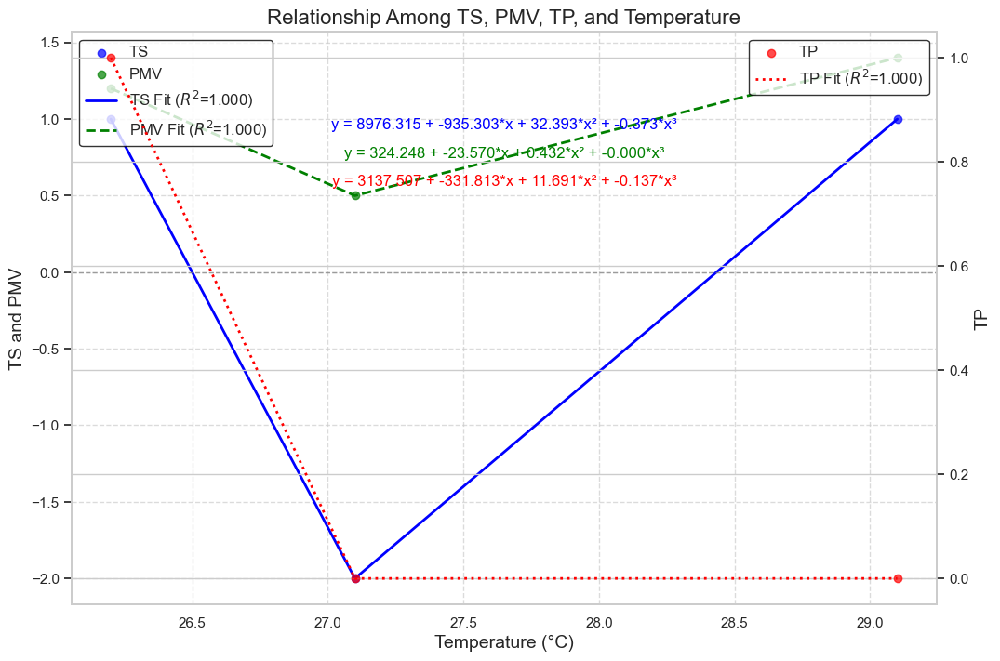

Figures saved successfully:
- plots\relation_sheep_INDIA_with_equations_updated.png
- plots\relation_sheep_INDIA_with_equations_updated.pdf
R² TS: 1.000
R² PMV: 1.000
R² TP: 1.000


In [311]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from numpy.polynomial.polynomial import Polynomial

# === 1. Chargement des données ===
file_path = "data_TS_PMV_TC_INDIA.csv"
dt = pd.read_csv(file_path)

# Utiliser une fraction plus importante des données (ajustable selon les besoins)
data = dt.sample(frac=0.002, random_state=0).reset_index(drop=True)

# Sélectionner uniquement les colonnes nécessaires
required_columns = ['Thermal preference', 'Thermal sensation', 'Air temperature (C)', 'PMV']
data = data[required_columns]

# Renommer les colonnes pour simplifier le code
data = data.rename(columns={
    'Thermal preference': 'TP',
    'Thermal sensation': 'TS',
    'Air temperature (C)': 'Ta',
    'PMV': 'PMV'
})

# === 2. Filtrage des valeurs non valides ===

# Eliminer les valeurs NaN dans les colonnes pertinentes
data = data.dropna(subset=['TP', 'TS', 'Ta', 'PMV'])

# Filtrer les valeurs aberrantes (par exemple, des températures trop élevées ou trop faibles)
data = data[(data['Ta'] > -20) & (data['Ta'] < 50)]  # Plage raisonnable pour la température

# Filtrer les valeurs non valides pour TP
valid_tp_values = ['warmer', 'no change', 'Cooler']
data = data[data['TP'].isin(valid_tp_values)]

# === 3. Remplacer les valeurs dans la colonne TP ===
data['TP'] = data['TP'].replace({
    'warmer': 1,
    'no change': 0,
    'Cooler': -1
})

# Conversion explicite en numérique (ignorer les erreurs)
data['TP'] = pd.to_numeric(data['TP'], errors='coerce')
data['TS'] = pd.to_numeric(data['TS'], errors='coerce')
data['Ta'] = pd.to_numeric(data['Ta'], errors='coerce')
data['PMV'] = pd.to_numeric(data['PMV'], errors='coerce')

# Remplacer les NaN par la moyenne des colonnes pertinentes
data.fillna(data.mean(), inplace=True)

# Filtrer une fraction des données
data_sample = data.sample(frac=0.2, random_state=42)

# Extraire les colonnes pertinentes
temperature = data_sample['Ta']
ts = data_sample['TS']
pmv = data_sample['PMV']
tp = data_sample['TP']

# === 4. Ajustement des modèles ===
degree = 3  # Tester un degré de polynôme plus élevé

# Ajustement du modèle polynomiale pour TS, PMV, et TP
poly_ts = Polynomial.fit(temperature, ts, degree)
poly_pmv = Polynomial.fit(temperature, pmv, degree)
poly_tp = Polynomial.fit(temperature, tp, degree)

# Générer les valeurs ajustées
temperature_sorted = np.sort(temperature)
ts_fit = poly_ts(temperature_sorted)
pmv_fit = poly_pmv(temperature_sorted)
tp_fit = poly_tp(temperature_sorted)

# Extraire les coefficients du modèle polynomial
coeff_ts = poly_ts.convert().coef
coeff_pmv = poly_pmv.convert().coef
coeff_tp = poly_tp.convert().coef

# Générer les équations sous forme de texte
eq_ts = f"y = {coeff_ts[0]:.3f} + {coeff_ts[1]:.3f}*x + {coeff_ts[2]:.3f}*x² + {coeff_ts[3]:.3f}*x³"
eq_pmv = f"y = {coeff_pmv[0]:.3f} + {coeff_pmv[1]:.3f}*x + {coeff_pmv[2]:.3f}*x² + {coeff_pmv[3]:.3f}*x³"
eq_tp = f"y = {coeff_tp[0]:.3f} + {coeff_tp[1]:.3f}*x + {coeff_tp[2]:.3f}*x² + {coeff_tp[3]:.3f}*x³"

# Calculer R²
r2_ts = r2_score(ts, poly_ts(temperature))
r2_pmv = r2_score(pmv, poly_pmv(temperature))
r2_tp = r2_score(tp, poly_tp(temperature))

# === 5. Création des figures ===
fig, ax1 = plt.subplots(figsize=(12, 8))

# Points de données (TS et PMV)
ax1.scatter(temperature, ts, label="TS", color="blue", alpha=0.7)
ax1.scatter(temperature, pmv, label="PMV", color="green", alpha=0.7)

# Courbes ajustées (TS et PMV)
ax1.plot(temperature_sorted, ts_fit, label=f"TS Fit ($R^2$={r2_ts:.3f})", color="blue", linewidth=2)
ax1.plot(temperature_sorted, pmv_fit, label=f"PMV Fit ($R^2$={r2_pmv:.3f})", color="green", linewidth=2, linestyle='--')

# Création d'un second axe y pour TP
ax2 = ax1.twinx()
ax2.scatter(temperature, tp, label="TP", color="red", alpha=0.7)
ax2.plot(temperature_sorted, tp_fit, label=f"TP Fit ($R^2$={r2_tp:.3f})", color="red", linewidth=2, linestyle=':')

# Afficher les équations sur le graphique à des positions stratégiques
ax1.text(0.5, 0.85, eq_ts, transform=ax1.transAxes, fontsize=12, color="blue", verticalalignment='top', horizontalalignment='center')
ax1.text(0.5, 0.80, eq_pmv, transform=ax1.transAxes, fontsize=12, color="green", verticalalignment='top', horizontalalignment='center')
ax2.text(0.5, 0.75, eq_tp, transform=ax2.transAxes, fontsize=12, color="red", verticalalignment='top', horizontalalignment='center')

# Configuration du graphique
ax1.set_title("Relationship Among TS, PMV, TP, and Temperature", fontsize=16)
ax1.set_xlabel("Temperature (°C)", fontsize=14)
ax1.set_ylabel("TS and PMV", fontsize=14)
ax2.set_ylabel("TP", fontsize=14)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax1.grid(True, linestyle='--', alpha=0.7)

# Légende
ax1.legend(fontsize=12, frameon=True, loc="upper left", edgecolor="black")
ax2.legend(fontsize=12, frameon=True, loc="upper right", edgecolor="black")

# Sauvegarde des figures avant affichage
output_dir = "plots"
os.makedirs(output_dir, exist_ok=True)
png_path = os.path.join(output_dir, "relation_sheep_INDIA_with_equations_updated.png")
pdf_path = os.path.join(output_dir, "relation_sheep_INDIA_with_equations_updated.pdf")
plt.savefig(png_path, dpi=300, bbox_inches='tight')
plt.savefig(pdf_path, bbox_inches='tight')

# Affichage
plt.show()

# Vérifier la sauvegarde
if os.path.exists(png_path) and os.path.exists(pdf_path):
    print(f"Figures saved successfully:\n- {png_path}\n- {pdf_path}")
else:
    print("Error: Figures were not saved correctly.")

# Afficher les R² pour un aperçu rapide de la performance du modèle
print(f"R² TS: {r2_ts:.3f}")
print(f"R² PMV: {r2_pmv:.3f}")
print(f"R² TP: {r2_tp:.3f}")

### POUR DETERMINER THERMAL SENSATION ET THERMAL PREFERENCE

In [316]:
import pandas as pd

# Charger le fichier
filtered_dataset = pd.read_csv('filtered_dataset.csv')

# Ajouter une colonne "Thermal Sensation" basée sur les valeurs PMV
def classify_thermal_sensation(pmv):
    if pmv < -3:
        return "Cold"
    elif -3 <= pmv < -2:
        return "Cool"
    elif -2 <= pmv < -1:
        return "Slightly Cool"
    elif -1 <= pmv <= 1:
        return "Neutral"
    elif 1 < pmv <= 2:
        return "Slightly Warm"
    elif 2 < pmv <= 3:
        return "Warm"
    else:
        return "Hot"

# Appliquer la classification
filtered_dataset['Thermal Sensation'] = filtered_dataset['PMV'].apply(classify_thermal_sensation)

# Ajouter une colonne "Thermal Preference" basée sur la préférence thermique supposée
def calculate_thermal_preference(pmv):
    if pmv < -0.5:
        return "Warmer"
    elif -0.5 <= pmv <= 0.5:
        return "No Change"
    else:
        return "Cooler"

# Appliquer la préférence thermique
filtered_dataset['Thermal Preference'] = filtered_dataset['PMV'].apply(calculate_thermal_preference)

# Enregistrer le fichier modifié
output_path = 'thermal_sensation_preference.csv'  # Enregistrer dans le répertoire courant
filtered_dataset.to_csv(output_path, index=False)

print(f"Fichier traité et sauvegardé sous : {output_path}")

Fichier traité et sauvegardé sous : thermal_sensation_preference.csv


#### THERMAL SENSATION  THERMAL COMFORT  TEMPERATURE

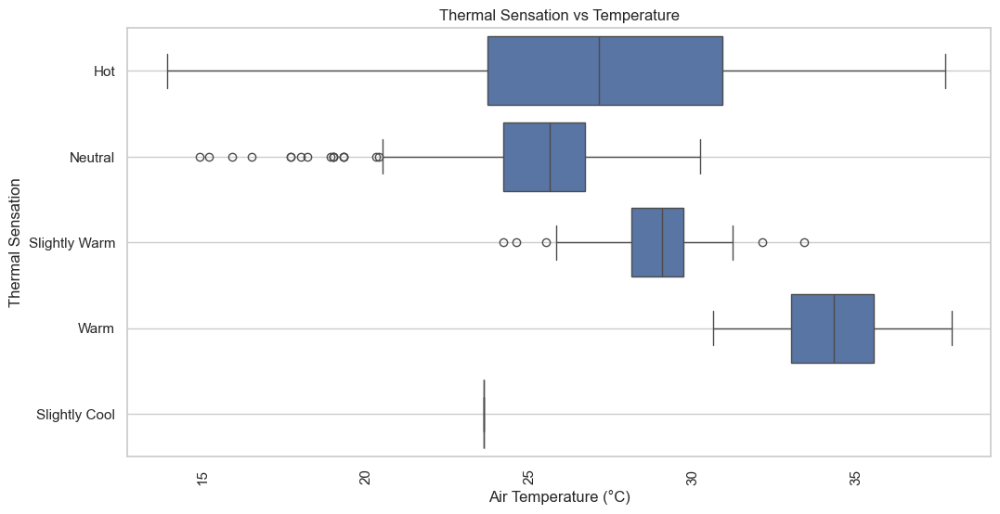

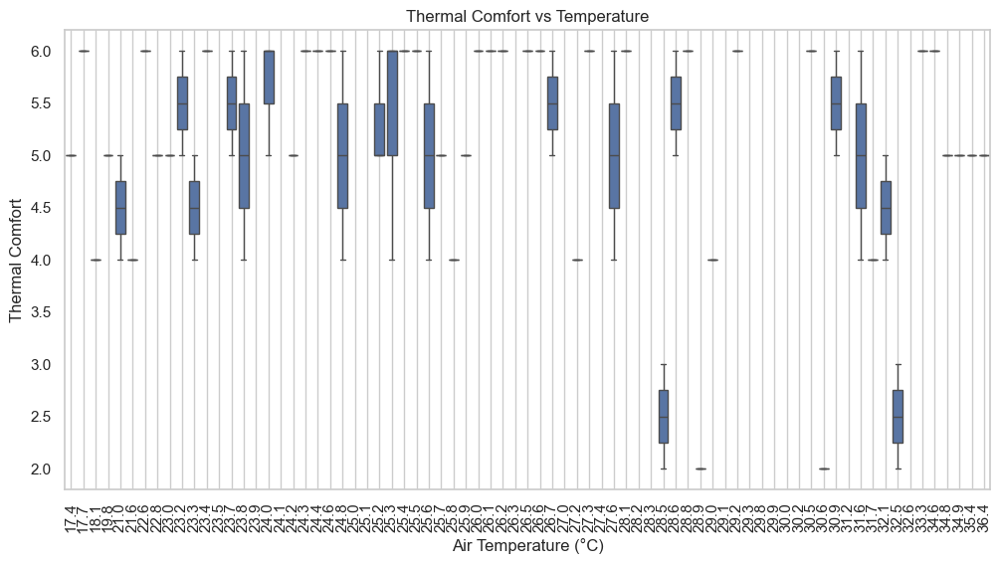

<Figure size 640x480 with 0 Axes>

In [281]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger et nettoyer les données
def load_and_clean_data(filepath, frac_sensation=0.05, frac_comfort=0.05):
    df = pd.read_csv(filepath)
    column_mapping = {
        'Air temperature (C)': 'Temperature',
        'Thermal Sensation': 'Thermal_Sensation',
        'Thermal comfort': 'Thermal_Comfort'
    }
    df.rename(columns=column_mapping, inplace=True)
    df.dropna(subset=['Thermal_Sensation', 'Temperature'], inplace=True)
    df['Thermal_Sensation'] = df['Thermal_Sensation'].astype(str)
    df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')
    df.dropna(subset=['Temperature'], inplace=True)
    
    # Prendre des fractions différentes des données
    df_sensation = df.sample(frac=frac_sensation, random_state=42)
    df_comfort = df.sample(frac=frac_comfort, random_state=42)
    
    return df_sensation, df_comfort

# Tracer les données
def plot_boxplot(df, x_col, y_col, title, xlabel, ylabel):
    if y_col in df.columns and df[y_col].notna().sum() > 0:
        plt.figure(figsize=(12, 6))
        sns.boxplot(x=df[x_col], y=df[y_col])
        plt.xticks(rotation=90)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.grid()
        plt.show()
    else:
        print(f"Pas de données disponibles pour {ylabel}.")

# Exécution du programme
df_sensation, df_comfort = load_and_clean_data('thermal_sensation_preference.csv', frac_sensation=0.05, frac_comfort=0.008)
plot_boxplot(df_sensation, 'Temperature', 'Thermal_Sensation', "Thermal Sensation vs Temperature", "Air Temperature (°C)", "Thermal Sensation")
plot_boxplot(df_comfort, 'Temperature', 'Thermal_Comfort', "Thermal Comfort vs Temperature", "Air Temperature (°C)", "Thermal Comfort")

# Sauvegarder la courbe
plt.savefig("BOXPLOT_TSV_TCV vs T°C_INDIA.png", dpi=300, bbox_inches='tight')

In [283]:
print(dataset.columns)

Index(['Publication (Citation)', 'Data contributor', 'Year', 'Season',
       'Koppen climate classification', 'Climate', 'City', 'Country',
       'Building type', 'Cooling startegy_building level',
       'Cooling startegy_operation mode for MM buildings',
       'Heating strategy_building level', 'Age', 'Sex', 'Thermal sensation',
       'Thermal sensation acceptability', 'Thermal preference',
       'Air movement acceptability', 'Air movement preference',
       'Thermal comfort', 'PMV', 'PPD', 'SET', 'Clo', 'Met', 'activity_10',
       'activity_20', 'activity_30', 'activity_60', 'Air temperature (C)',
       'Air temperature (F)', 'Ta_h (C)', 'Ta_h (F)', 'Ta_m (C)', 'Ta_m (F)',
       'Ta_l (C)', 'Ta_l (F)', 'Operative temperature (C)',
       'Operative temperature (F)', 'Radiant temperature (C)',
       'Radiant temperature (F)', 'Globe temperature (C)',
       'Globe temperature (F)', 'Tg_h (C)', 'Tg_h (F)', 'Tg_m (C)', 'Tg_m (F)',
       'Tg_l (C)', 'Tg_l (F)', 'Relative humi

In [285]:
print(df["Thermal Sensation"].value_counts())

KeyError: 'Thermal Sensation'

In [287]:
print(df["Thermal comfort"].value_counts())

KeyError: 'Thermal comfort'

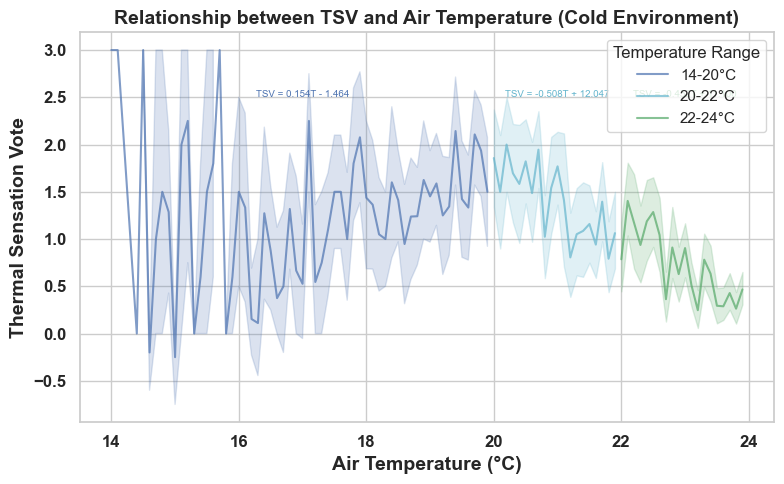

In [327]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import linregress

# Charger les données
df = pd.read_csv('thermal_sensation_preference.csv')

# Utiliser toutes les données (échantillonnage aléatoire pour l'ordre)
df = df.sample(frac=1, random_state=42)

# Convertir la colonne de sensation thermique en valeurs numériques
ts_map = {
    "Cold": -3, "Cool": -2, "Slightly Cool": -1, "Neutral": 0, "Slightly Warm": 1, "Warm": 2, "Hot": 3
}
df["Thermal Sensation"] = df["Thermal Sensation"].map(ts_map)

# Supprimer les lignes avec des NaN dans les colonnes importantes
df.dropna(subset=["Thermal Sensation", "Air temperature (C)"], inplace=True)

# Définir les groupes de température pour l'environnement froid
temp_groups = [(14, 20), (20, 22), (22, 24)]
colors = ['b', 'c', 'g']
markers = ['o', 's', '^']

# Création d'un seul graphique
plt.figure(figsize=(8, 5))

# Tracer les courbes et ajouter la légende
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    
    if not df_group.empty:
        # Tracer la ligne avec un label pour la légende
        sns.lineplot(
            x=df_group["Air temperature (C)"], 
            y=df_group["Thermal Sensation"], 
            color=colors[i], 
            linestyle='-', 
            alpha=0.7, 
            label=f"{t_min}-{t_max}°C"
        )

        # Calcul de la régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal Sensation"])
        equation = f"TSV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"
        
        # Afficher l'équation au centre du groupe
        plt.text((t_min + t_max) / 2, df_group["Thermal Sensation"].max() - 0.5, 
                 equation, fontsize=7, color=colors[i], ha='center')

# Personnalisation du graphique
plt.title("Relationship between TSV and Air Temperature (Cold Environment)", fontsize=14, fontweight='bold')
plt.xlabel("Air Temperature (°C)", fontsize=14, fontweight='bold')
plt.ylabel("Thermal Sensation Vote", fontsize=14, fontweight='bold')
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

# Ajouter la légende
plt.legend(title="Temperature Range")

# Ajustement du layout et sauvegarde
plt.tight_layout()
plt.savefig("TSV_T°C_Cold_ENV_INDIA.png")
plt.show()

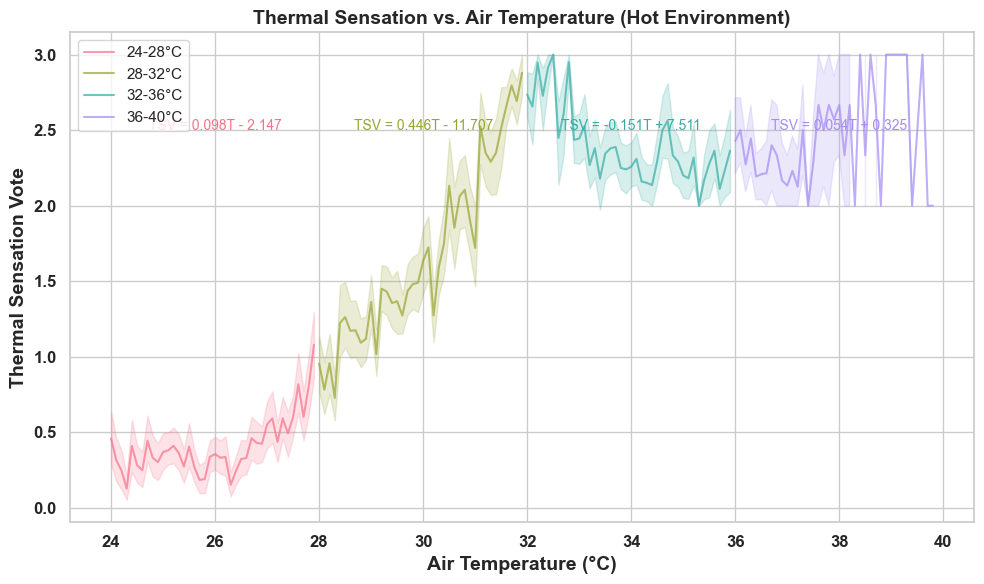

In [329]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import linregress

# Charger les données
df = pd.read_csv('thermal_sensation_preference.csv')

# Réduction de la taille de l'échantillon pour accélérer le traitement
df = df.sample(frac=1, random_state=42)

# Convertir la colonne de sensation thermique en valeurs numériques
ts_map = {
    "Cold": -3, "Cool": -2, "Slightly Cool": -1, "Neutral": 0, "Slightly Warm": 1, "Warm": 2, "Hot": 3
}
df["Thermal Sensation"] = df["Thermal Sensation"].map(ts_map)

# Définition des groupes de température (environnement chaud)
temp_groups = [(24, 28), (28, 32), (32, 36), (36, 40)]
colors = sns.color_palette("husl", len(temp_groups))  # Palette dynamique
markers = ['o', 's', '^', 'D']  

# Création du graphique
plt.figure(figsize=(10, 6))

# Tracer les courbes et ajouter la légende
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    
    if not df_group.empty:
        # Tracer la ligne avec un label pour la légende
        sns.lineplot(
            x=df_group["Air temperature (C)"], 
            y=df_group["Thermal Sensation"], 
            color=colors[i], 
            linestyle='-', 
            alpha=0.7, 
            label=f"{t_min}-{t_max}°C"
        )


        # Calcul de la régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal Sensation"])
        equation = f"TSV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"
        plt.text((t_min + t_max) / 2, df_group["Thermal Sensation"].max() - 0.5, equation, 
                 fontsize=10, color=colors[i], ha='center')

# Personnalisation du graphique
plt.title("Thermal Sensation vs. Air Temperature (Hot Environment)", fontsize=14, fontweight='bold')
plt.xlabel("Air Temperature (°C)", fontsize=14, fontweight='bold')
plt.ylabel("Thermal Sensation Vote", fontsize=14, fontweight='bold')
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()

# Sauvegarder et afficher
plt.savefig("TSV_vs_Temperature_Hot_Env_INDIA.png", dpi=300)
plt.show()

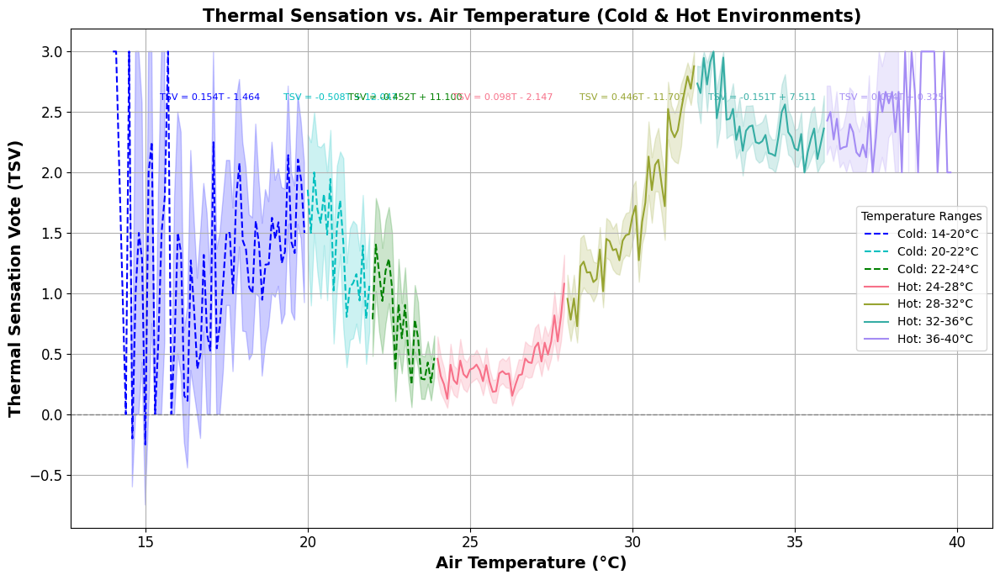

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import linregress

# Charger les données
df = pd.read_csv('thermal_sensation_preference.csv')

# Mélanger les données
df = df.sample(frac=1, random_state=42)

# Mapper la colonne de sensation thermique en valeurs numériques
ts_map = {
    "Cold": -3, "Cool": -2, "Slightly Cool": -1, "Neutral": 0,
    "Slightly Warm": 1, "Warm": 2, "Hot": 3
}
df["Thermal Sensation"] = df["Thermal Sensation"].map(ts_map)

# Supprimer les lignes avec des valeurs manquantes importantes
df.dropna(subset=["Thermal Sensation", "Air temperature (C)"], inplace=True)

# Définir les groupes de température froids et chauds
cold_groups = [(14, 20), (20, 22), (22, 24)]
hot_groups = [(24, 28), (28, 32), (32, 36), (36, 40)]

# Couleurs pour les groupes froids et chauds
cold_colors = ['b', 'c', 'g']
hot_colors = sns.color_palette("husl", len(hot_groups))

# Création du graphique combiné
plt.figure(figsize=(12, 7))

# Tracer les groupes froids
for i, (t_min, t_max) in enumerate(cold_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    if not df_group.empty:
        sns.lineplot(
            x=df_group["Air temperature (C)"], 
            y=df_group["Thermal Sensation"], 
            color=cold_colors[i], 
            linestyle='--', 
            label=f"Cold: {t_min}-{t_max}°C"
        )
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal Sensation"])
        eq = f"TSV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"
        plt.text((t_min + t_max) / 2, df_group["Thermal Sensation"].max() - 0.4, eq,
                 fontsize=8, color=cold_colors[i], ha='center')

# Tracer les groupes chauds
for i, (t_min, t_max) in enumerate(hot_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    if not df_group.empty:
        sns.lineplot(
            x=df_group["Air temperature (C)"], 
            y=df_group["Thermal Sensation"], 
            color=hot_colors[i], 
            linestyle='-', 
            label=f"Hot: {t_min}-{t_max}°C"
        )
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal Sensation"])
        eq = f"TSV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"
        plt.text((t_min + t_max) / 2, df_group["Thermal Sensation"].max() - 0.4, eq,
                 fontsize=8, color=hot_colors[i], ha='center')

# Personnalisation du graphique
plt.title("Thermal Sensation vs. Air Temperature (Cold & Hot Environments)", fontsize=15, fontweight='bold')
plt.xlabel("Air Temperature (°C)", fontsize=14, fontweight='bold')
plt.ylabel("Thermal Sensation Vote (TSV)", fontsize=14, fontweight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.legend(title="Temperature Ranges")
plt.grid(True)
plt.tight_layout()

# Sauvegarde et affichage
plt.savefig("TSV_vs_Temperature_Cold_Hot_Environments_INDIA.png", dpi=300)
plt.show()

In [330]:
import pandas as pd

# Charger le fichier
df = pd.read_csv('thermal_sensation_preference.csv')

# Identifier la colonne cible
target_column = 'Thermal comfort'

# Remplacer les NaN dans la colonne 'Thermal comfort' de manière itérative
for i in range(df[target_column].isna().sum()):
    # Calculer la moyenne des valeurs existantes (sans NaN)
    current_mean = df[target_column].mean()
    
    # Remplacer le premier NaN rencontré par la moyenne actuelle
    df[target_column].fillna(current_mean, inplace=True)

# Afficher les premières lignes et les colonnes avec des valeurs manquantes
df.head(), df.isnull().sum()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\3152227971.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[target_column].fillna(current_mean, inplace=True)


(  Country  Air temperature (C)  Radiant temperature (C)  Air velocity (m/s)  \
 0   India                 25.2                    20.16                 0.1   
 1   India                 25.2                    20.16                 0.1   
 2   India                 25.2                    20.16                 0.1   
 3   India                 25.2                    20.16                 0.1   
 4   India                 25.2                    20.16                 0.1   
 
    Relative humidity (%)  Met   Clo  PMV  PPD  Thermal comfort  \
 0                   64.0  1.0  0.75  0.3  7.0          4.73934   
 1                   64.0  1.0  0.64  0.1  5.0          4.73934   
 2                   64.0  1.0  0.64  0.1  5.0          4.73934   
 3                   64.0  1.0  0.75  0.3  7.0          4.73934   
 4                   64.0  1.0  0.72  0.2  6.0          4.73934   
 
   Thermal Sensation Thermal Preference  
 0           Neutral          No Change  
 1           Neutral          

In [331]:
print(df["Thermal comfort"].value_counts())

Thermal comfort
4.73934    6382
6.00000    3248
5.00000    3090
4.00000    1917
3.00000     706
2.00000     613
1.00000     153
1.30000       1
Name: count, dtype: int64


C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2990444087.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Thermal comfort"].fillna(current_mean, inplace=True)


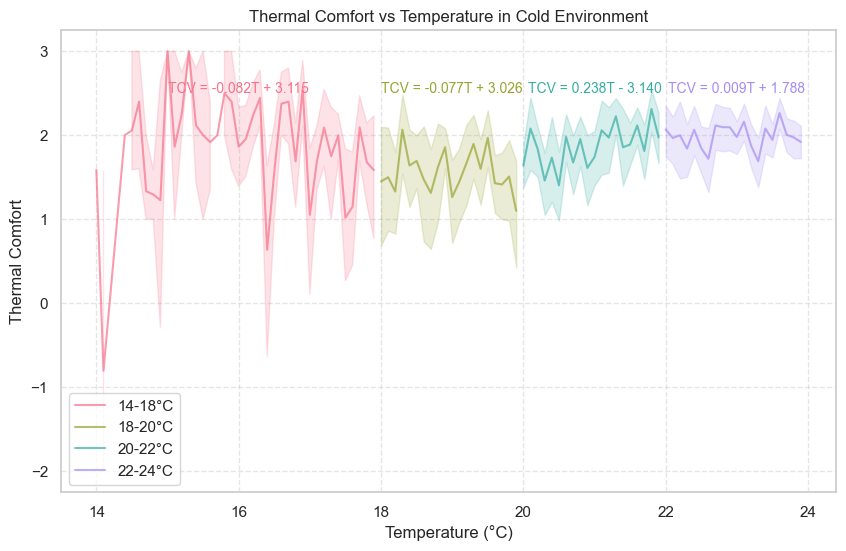

In [332]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Charger les données
file_path = "thermal_sensation_preference.csv"
df = pd.read_csv(file_path)

# Remplacer les valeurs de "Thermal comfort"
comfort_mapping = {
    1: -3,
    2: -2,
    3: -1,
    4: 1,
    5: 2,
    6: 3
}
df["Thermal comfort"] = df["Thermal comfort"].replace(comfort_mapping)

# Remplacer les NaN dans "Thermal comfort" par la moyenne
for _ in range(df["Thermal comfort"].isna().sum()):
    current_mean = df["Thermal comfort"].mean()
    df["Thermal comfort"].fillna(current_mean, inplace=True)

# Filtrer les valeurs valides
df_valid = df.dropna(subset=["Thermal comfort", "Air temperature (C)"])

# Définition des groupes de température
temp_groups = [(14, 18), (18, 20), (20, 22), (22, 24)]
colors = sns.color_palette("husl", len(temp_groups))  # Palette dynamique

# Créer un graphique
plt.figure(figsize=(10, 6))

# Boucle pour tracer les lignes pour chaque groupe de température
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df_valid[(df_valid["Air temperature (C)"] >= t_min) & (df_valid["Air temperature (C)"] < t_max)]
    df_group = df_group.sort_values(by="Air temperature (C)")
    
    if not df_group.empty:
        sns.lineplot(x=df_group["Air temperature (C)"], y=df_group["Thermal comfort"], 
                     color=colors[i], linestyle='-', alpha=0.7, label=f"{t_min}-{t_max}°C")

        # Calcul de la régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal comfort"])
        equation = f"TCV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"

        # Ajouter l'équation à l'endroit moyen de l'intervalle
        plt.text((t_min + t_max) / 2, df_group["Thermal comfort"].max() - 0.5, equation, 
                 fontsize=10, color=colors[i], ha='center')

# Ajouter des labels et un titre
plt.title('Thermal Comfort vs Temperature in Cold Environment')
plt.xlabel('Temperature (°C)')
plt.ylabel('Thermal Comfort')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Sauvegarder la courbe
plt.savefig("TCV vs T°C in Cold Environment_INDIA.png", dpi=300, bbox_inches='tight')

# Afficher le graphique
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\196494570.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[target_column].fillna(df[target_column].mean(), inplace=True)


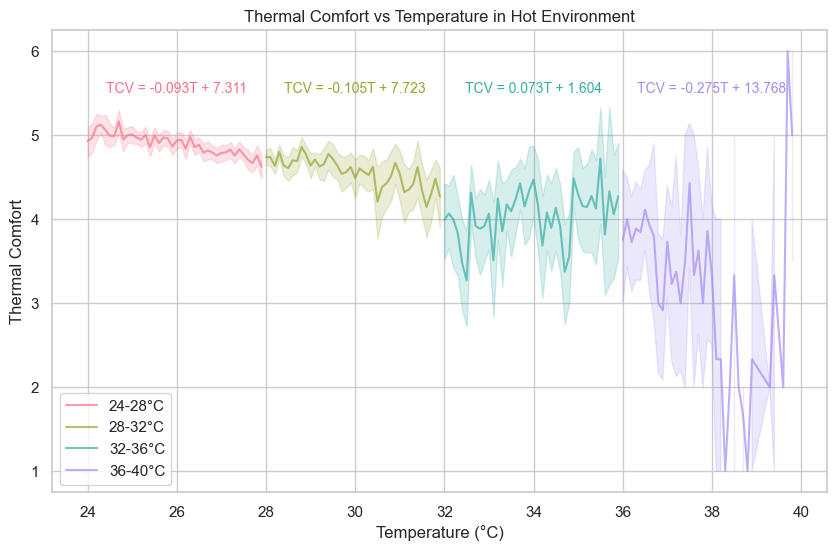

In [337]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Charger le fichier
df = pd.read_csv('thermal_sensation_preference.csv')

# Identifier la colonne cible
target_column = 'Thermal comfort'

# Remplacer les NaN dans la colonne 'Thermal comfort' par la moyenne de cette colonne
df[target_column].fillna(df[target_column].mean(), inplace=True)

# Définir ts_map si nécessaire (exemple, ajustez-le selon vos données)
# Si vous avez une carte pour la colonne "Thermal Sensation", vous pouvez la définir comme suit :
ts_map = {'Cold': 1, 'Neutral': 0, 'Hot': -1}  # Exemple de mapping


# Appliquer le mapping à la colonne "Thermal Sensation"
#df["Thermal Sensation"] = df["Thermal Sensation"].map(ts_map)

# Définition des groupes de température (environnement froid)
temp_groups = [(24, 28), (28, 32), (32, 36), (36, 40)]
colors = sns.color_palette("husl", len(temp_groups))  # Palette dynamique
markers = ['o', 's', '^', 'D']

# Créer un graphique
plt.figure(figsize=(10, 6))

# Boucle pour tracer les points et les lignes pour chaque groupe de température
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    
    if not df_group.empty:
        # Tracer les points + ligne entre eux
        sns.lineplot(x=df_group["Air temperature (C)"], y=df_group["Thermal comfort"], 
                     color=colors[i], linestyle='-', alpha=0.7, label=f"{t_min}-{t_max}°C")

        # Calcul de la régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal comfort"])
        equation = f"TCV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"

        # Ajouter l'équation à l'endroit moyen de l'intervalle
        plt.text((t_min + t_max) / 2, df_group["Thermal comfort"].max() - 0.5, equation, 
                 fontsize=10, color=colors[i], ha='center')

# Ajouter des labels et un titre
plt.title('Thermal Comfort vs Temperature in Hot Environment')
plt.xlabel('Temperature (°C)')
plt.ylabel('Thermal Comfort')

# Afficher la légende
plt.legend()

# Sauvegarder la courbe
#plt.savefig("TCV vs T°C in HOT Environment_INDIA.png", dpi=300, bbox_inches='tight')

# Afficher le graphique
plt.grid(True)
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_22252\1413205534.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[target_column].fillna(df[target_column].mean(), inplace=True)


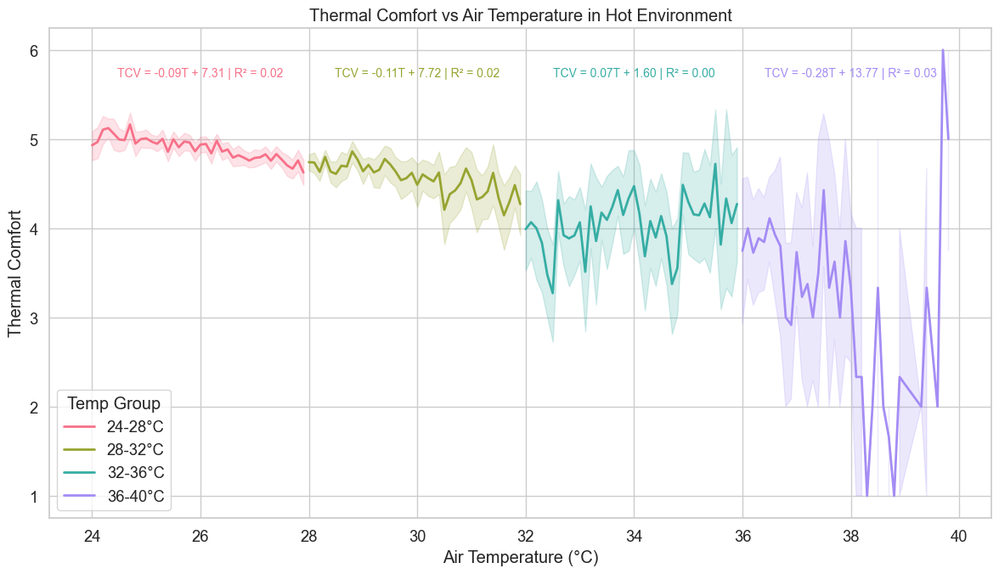

In [289]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# === 1. Chargement et Prétraitement ===
def load_and_clean_data(file_path, target_column='Thermal comfort'):
    df = pd.read_csv(file_path)
    
    # Vérification des colonnes nécessaires
    required_cols = ['Air temperature (C)', target_column]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Colonne manquante : {col}")

    # Remplir les NaN dans la colonne cible
    df[target_column].fillna(df[target_column].mean(), inplace=True)
    return df

# === 2. Tracer le graphique par groupe de température ===
def plot_temperature_vs_comfort(df, target_column='Thermal comfort', output_path=None):
    temp_groups = [(24, 28), (28, 32), (32, 36), (36, 40)]
    colors = sns.color_palette("husl", len(temp_groups))
    
    plt.figure(figsize=(12, 7))
    sns.set(style="whitegrid", font_scale=1.2)
    
    for i, (t_min, t_max) in enumerate(temp_groups):
        group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)]
        group = group.sort_values(by="Air temperature (C)")

        if not group.empty:
            sns.lineplot(x=group["Air temperature (C)"], y=group[target_column],
                         color=colors[i], label=f"{t_min}-{t_max}°C", linewidth=2)

            # Régression linéaire + R²
            slope, intercept, r_value, _, _ = linregress(group["Air temperature (C)"], group[target_column])
            equation = f"TCV = {slope:.2f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.2f} | R² = {r_value**2:.2f}"

            # Position du texte
            mid_x = (t_min + t_max) / 2
            mid_y = group[target_column].max() - 0.3
            plt.text(mid_x, mid_y, equation, fontsize=10, color=colors[i], ha='center')

    plt.title('Thermal Comfort vs Air Temperature in Hot Environment')
    plt.xlabel('Air Temperature (°C)')
    plt.ylabel('Thermal Comfort')
    plt.legend(title='Temp Group')
    plt.grid(True)
    plt.tight_layout()

    # Sauvegarde facultative
    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()

# === 3. Point d’entrée ===
if __name__ == "__main__":
    file_path = 'thermal_sensation_preference.csv'
    df = load_and_clean_data(file_path)
    plot_temperature_vs_comfort(df, output_path="TCV_vs_Temp_HOT_ENV_INDIA.png")

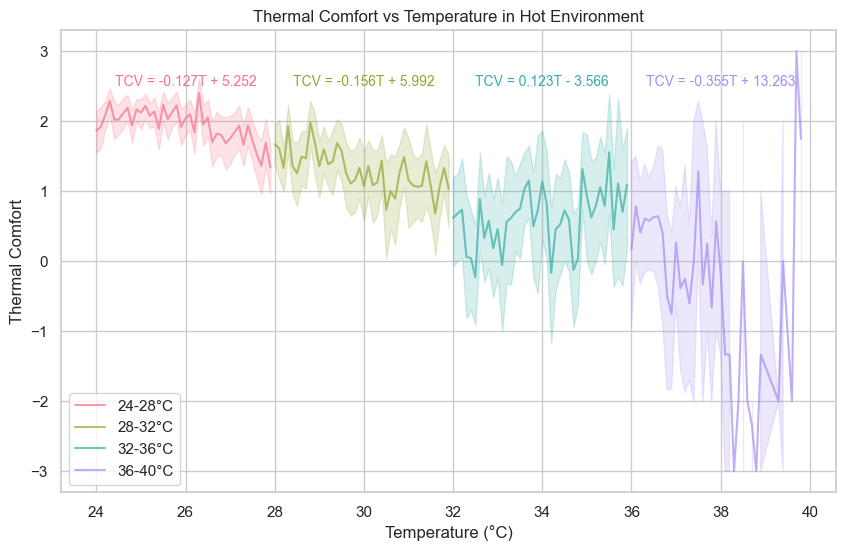

In [339]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Charger le fichier
df = pd.read_csv('thermal_sensation_preference.csv')

# Identifier la colonne cible
target_column = 'Thermal comfort'

# Supprimer les lignes contenant des NaN dans la colonne 'Thermal comfort'
df = df.dropna(subset=[target_column])

# Appliquer le mapping des valeurs de "Thermal comfort"
comfort_mapping = {1: -3, 2: -2, 3: -1, 4: 1, 5: 2, 6: 3}
df["Thermal comfort"] = df["Thermal comfort"].replace(comfort_mapping)

# Supprimer les lignes contenant des NaN dans d'autres colonnes importantes (ex: Température)
df = df.dropna(subset=["Air temperature (C)"])

# Définition des groupes de température (environnement chaud)
temp_groups = [(24, 28), (28, 32), (32, 36), (36, 40)]
colors = sns.color_palette("husl", len(temp_groups))  # Palette dynamique

# Créer un graphique
plt.figure(figsize=(10, 6))

# Boucle pour tracer les points et les lignes pour chaque groupe de température
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")
    
    if not df_group.empty:
        # Tracer les points + ligne entre eux
        sns.lineplot(x=df_group["Air temperature (C)"], y=df_group["Thermal comfort"], 
                     color=colors[i], linestyle='-', alpha=0.7, label=f"{t_min}-{t_max}°C")

        # Calcul de la régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal comfort"])
        equation = f"TCV = {slope:.3f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.3f}"

        # Ajouter l'équation au centre du groupe
        plt.text((t_min + t_max) / 2, df_group["Thermal comfort"].max() - 0.5, equation, 
                 fontsize=10, color=colors[i], ha='center')

# Ajouter des labels et un titre
plt.title('Thermal Comfort vs Temperature in Hot Environment')
plt.xlabel('Temperature (°C)')
plt.ylabel('Thermal Comfort')

# Afficher la légende
plt.legend()

# Sauvegarder la courbe
plt.savefig("TCV vs T°C in Hot Environment_INDIA.png", dpi=300, bbox_inches='tight')

# Afficher le graphique
plt.grid(True)
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_20004\167773370.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Thermal comfort"].fillna(df["Thermal comfort"].mean(), inplace=True)


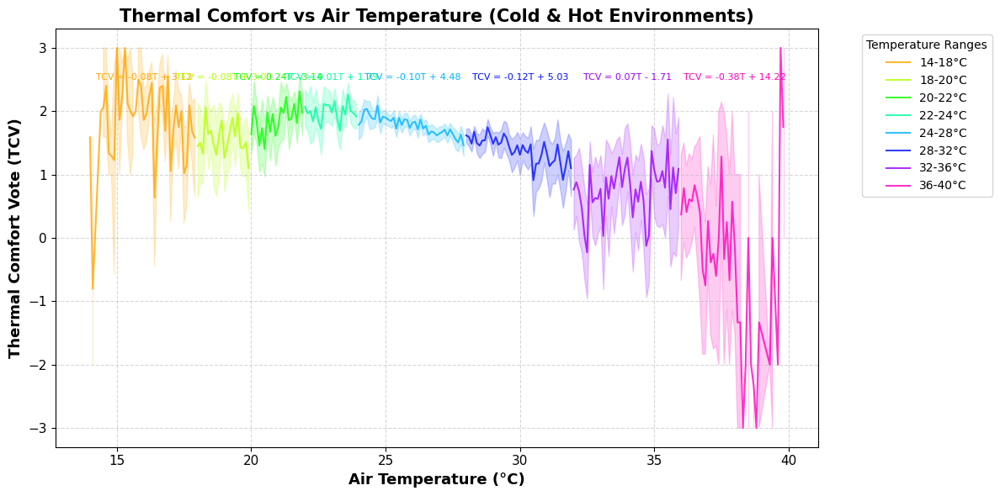

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Charger les données
df = pd.read_csv("thermal_sensation_preference.csv")

# Remplacement des valeurs dans "Thermal comfort"
comfort_mapping = {
    1: -3,
    2: -2,
    3: -1,
    4: 1,
    5: 2,
    6: 3
}
df["Thermal comfort"] = df["Thermal comfort"].replace(comfort_mapping)

# Remplacer les NaN par la moyenne
df["Thermal comfort"].fillna(df["Thermal comfort"].mean(), inplace=True)

# Définir les groupes de température (froid + chaud)
temp_groups = [(14, 18), (18, 20), (20, 22), (22, 24),
               (24, 28), (28, 32), (32, 36), (36, 40)]

# Palette de couleurs
colors = sns.color_palette("hsv", len(temp_groups))

# Création du graphique
plt.figure(figsize=(12, 6))

# Tracer chaque groupe
for i, (t_min, t_max) in enumerate(temp_groups):
    df_group = df[(df["Air temperature (C)"] >= t_min) & (df["Air temperature (C)"] < t_max)].sort_values(by="Air temperature (C)")

    if not df_group.empty:
        sns.lineplot(
            x=df_group["Air temperature (C)"],
            y=df_group["Thermal comfort"],
            color=colors[i],
            label=f"{t_min}-{t_max}°C",
            alpha=0.8
        )

        # Régression linéaire
        slope, intercept, _, _, _ = linregress(df_group["Air temperature (C)"], df_group["Thermal comfort"])
        equation = f"TCV = {slope:.2f}T {'+' if intercept >= 0 else '-'} {abs(intercept):.2f}"
        plt.text((t_min + t_max) / 2, df_group["Thermal comfort"].max() - 0.5,
                 equation, fontsize=8, color=colors[i], ha='center')

# Personnalisation du graphique
plt.title("Thermal Comfort vs Air Temperature (Cold & Hot Environments)", fontsize=15, fontweight='bold')
plt.xlabel("Air Temperature (°C)", fontsize=13, fontweight='bold')
plt.ylabel("Thermal Comfort Vote (TCV)", fontsize=13, fontweight='bold')
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(title="Temperature Ranges", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Sauvegarder
plt.savefig("TCV_vs_Temperature_Combined_INDIA.png", dpi=300)
plt.show()


In [340]:
import pandas as pd

df = pd.read_csv('thermal_sensation_preference.csv')

In [343]:
temp_min = df["Air temperature (C)"].min()
temp_max = df["Air temperature (C)"].max()
print(f"Température minimale: {temp_min}°C")
print(f"Température maximale: {temp_max}°C")

Température minimale: 7.0°C
Température maximale: 40.5°C


In [345]:
# Nombre de chaque valeur de la température en Celsius
temp_counts = df["Air temperature (C)"].value_counts()
print(temp_counts)

Air temperature (C)
25.1    299
25.2    292
26.0    272
25.9    266
26.1    247
       ... 
38.4      1
40.5      1
39.6      1
40.2      1
14.4      1
Name: count, Length: 266, dtype: int64


In [347]:
# Extraire les valeurs qui se répètent dans la température en Celsius
repeated_values_temp_c = df[df["Air temperature (C)"].duplicated()]["Air temperature (C)"].drop_duplicates()
print(repeated_values_temp_c)

1        25.2
8        26.9
27       25.8
30       26.4
38       24.7
         ... 
15316    15.3
15318    14.6
15341    15.8
15342    15.9
15570     NaN
Name: Air temperature (C), Length: 247, dtype: float64


C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\224790079.py:34: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Thermal comfort"].fillna(current_mean, inplace=True)
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\224790079.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_va

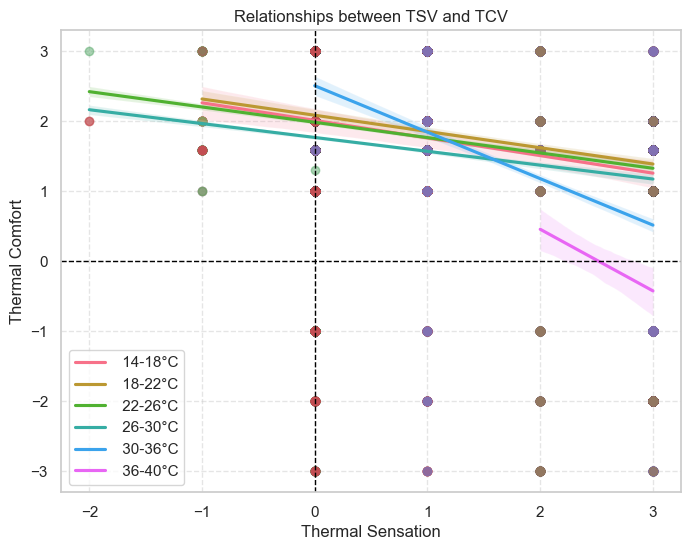

In [353]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données
file_path = "thermal_sensation_preference.csv"
df = pd.read_csv(file_path)

# Mapper les valeurs de "Thermal Sensation"
sensation_mapping = {
    "Cool": -2,
    "Slightly Cool": -1,
    "Neutral": 0,
    "Slightly Warm": 1,
    "Warm": 2,
    "Hot": 3
}
df["Thermal Sensation Numeric"] = df["Thermal Sensation"].map(sensation_mapping)

# Remplacer les valeurs de "Thermal comfort"
comfort_mapping = {
    1: -3,
    2: -2,
    3: -1,
    4: 1,
    5: 2,
    6: 3
}
df["Thermal comfort"] = df["Thermal comfort"].replace(comfort_mapping)

# Remplacer les NaN dans "Thermal comfort" par la moyenne itérative
for _ in range(df["Thermal comfort"].isna().sum()):
    current_mean = df["Thermal comfort"].mean()
    df["Thermal comfort"].fillna(current_mean, inplace=True)

# Filtrer les valeurs valides
df_valid = df.dropna(subset=["Thermal comfort", "Thermal Sensation Numeric", "Air temperature (C)"])

# Définition des groupes de température
bins = [14, 18, 22, 26, 30, 36, 40]  # Définition des seuils
labels = ["14-18°C", "18-22°C", "22-26°C", "26-30°C", "30-36°C", "36-40°C"]
df_valid["Temp Interval"] = pd.cut(df_valid["Air temperature (C)"], bins=bins, labels=labels, include_lowest=True)

# Palette et styles
temp_colors = sns.color_palette("husl", len(labels))  # Palette dynamique
plt.figure(figsize=(8, 6))

# Tracer la courbe pour chaque intervalle de température
for interval, color in zip(labels, temp_colors):
    subset = df_valid[df_valid["Temp Interval"] == interval]
    sns.regplot(
        data=subset, 
        x="Thermal Sensation Numeric", 
        y="Thermal comfort", 
        scatter_kws={"alpha": 0.5}, 
        line_kws={"color": color, "label": f" {interval}"}
    )

# Ajouter les axes et le titre
plt.axhline(0, color='black', linewidth=1, linestyle='--')  # Ligne horizontale centrée sur 0
plt.axvline(0, color='black', linewidth=1, linestyle='--')  # Ligne verticale centrée sur 0
plt.xlabel("Thermal Sensation")
plt.ylabel("Thermal Comfort")
plt.title("Relationships between TSV and TCV")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Afficher la courbe
plt.show()

C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2501349784.py:34: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Thermal comfort"].fillna(df["Thermal comfort"].mean(), inplace=True)
C:\Users\Rchid\AppData\Local\Temp\ipykernel_13368\2501349784.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-ver

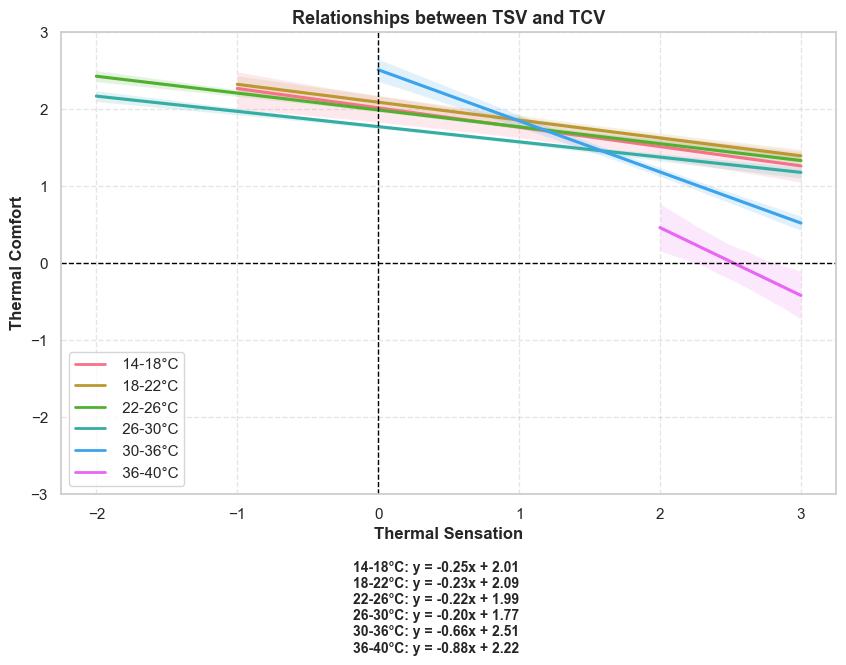

In [359]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Charger les données
file_path = "thermal_sensation_preference.csv"
df = pd.read_csv(file_path)

# Mapper les valeurs de "Thermal Sensation"
sensation_mapping = {
    "Cold": -3,
    "Cool": -2,
    "Slightly Cool": -1,
    "Neutral": 0,
    "Slightly Warm": 1,
    "Warm": 2,
    "Hot": 3
}
df["Thermal Sensation Numeric"] = df["Thermal Sensation"].map(sensation_mapping)

# Remplacer les valeurs de "Thermal comfort"
comfort_mapping = {
    1: -3,
    2: -2,
    3: -1,
    4: 1,
    5: 2,
    6: 3
}
df["Thermal comfort"] = df["Thermal comfort"].replace(comfort_mapping)

# Remplacer les NaN dans "Thermal comfort" par la moyenne
df["Thermal comfort"].fillna(df["Thermal comfort"].mean(), inplace=True)

# Filtrer les valeurs valides
df_valid = df.dropna(subset=["Thermal comfort", "Thermal Sensation Numeric", "Air temperature (C)"])

# Définition des groupes de température
bins = [14, 18, 22, 26, 30, 36, 40]
labels = ["14-18°C", "18-22°C", "22-26°C", "26-30°C", "30-36°C", "36-40°C"]
df_valid["Temp Interval"] = pd.cut(df_valid["Air temperature (C)"], bins=bins, labels=labels, include_lowest=True)

# Palette et styles
temp_colors = sns.color_palette("husl", len(labels))
plt.figure(figsize=(10, 6))

legend_handles = []
equations = []

# Tracer la courbe et ajouter les équations
for interval, color in zip(labels, temp_colors):
    subset = df_valid[df_valid["Temp Interval"] == interval]
    if not subset.empty:
        sns.regplot(
            data=subset, 
            x="Thermal Sensation Numeric", 
            y="Thermal comfort", 
            scatter=False, 
            line_kws={"color": color}
        )
        
        legend_handles.append(plt.Line2D([0], [0], color=color, lw=2, label=f" {interval}"))
        
        slope, intercept, _, _, _ = linregress(subset["Thermal Sensation Numeric"], subset["Thermal comfort"])
        equation = f"{interval}: y = {slope:.2f}x {'+' if intercept >= 0 else '-'} {abs(intercept):.2f}"
        equations.append(equation)

# Ajouter les axes et le titre
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.xlabel("Thermal Sensation", fontsize=12, fontweight='bold')
plt.ylabel("Thermal Comfort", fontsize=12, fontweight='bold')
plt.ylim(-3, 3)  # Fixer l'axe Y entre -3 et 3
plt.title("Relationships between TSV and TCV", fontsize=13, fontweight='bold')

plt.legend(handles=legend_handles)
plt.grid(True, linestyle='--', alpha=0.5)

# Afficher toutes les équations sous le graphique
equation_text = "\n".join(equations)
plt.figtext(0.5, -0.15, equation_text, wrap=True, horizontalalignment='center', fontsize=10, fontweight='bold')

# Sauvegarder la courbe
plt.savefig("Relationships between TSV and TCV_INDIA.png", dpi=300, bbox_inches='tight')

# Afficher la courbe
plt.show()